# Bayesian backpropagation in PyTorch

This is a native PyTorch implementation and executable tutorial. The semantic
and approximation experiments run in this notebook. Benchmark tables and
figures are recomputed in Python from saved per-example predictions, with
configurations and timing receipts. The native Dirty-MNIST chapter includes new
full fits; other benchmark chapters retain their original run provenance. No R-generated plot is presented as a PyTorch result. The notebook
follows one scientific path throughout:

1. encode Gaussian Euclidean adjoints as moment-space messages;
2. propagate moments through ordinary `nn.Module` layers;
3. transport a method-specific EP or MFVI signal backward on a frozen snapshot;
4. update the persistent Gaussian beliefs only after the reverse traversal;
5. evaluate Bayesian predictions by averaging probabilities.

The exact Gaussian example supplies an analytic positive control. EP and MFVI
then use different objectives on the same nonlinear graph. A fixed-belief
experiment finally measures approximation error and computation against a
large reparameterized Monte Carlo calculation. The benchmark chapters apply
the same uncertainty metrics to MNIST, CIFAR-10, SST-2 and CLINC.

| Section | Question answered | Main code |
|---|---|---|
| 1 | How do ordinary derivatives encode Gaussian messages? | `geometry`, `layers`, `graph` |
| 2 | Do exact, EP and MFVI message calculations agree with backprop? | `gaussian_chain`, `heads`, `inference` |
| 3 | What is lost by diagonal moments or a small covariance rank? | `correlation`, `tutorial_evidence` |
| 4 | How are beliefs trained and uncertainty evaluated on MNIST? | `optimizers`, `training`, `metrics` |
| 5 | What changes for residual/dense CNNs on CIFAR-10? | `architectures` |
| 6 | How do Gaussian Q/V adapters work for GPT-2/SST-2? | `python/gpt2` |
| 7 | How do conditional moment carriers work for RoBERTa/CLINC? | `python/blob_mirror` |
| 8 | Which claims can be reproduced, and from which evidence? | tests, manifest, reproduction map |

**Reading the code.** The expanded cells show the mathematical operations,
model builders and short experiment calls. Cells labelled “support” can be
expanded to inspect installation, plotting and complete run routines; their
outputs remain beside the relevant explanation. Exact source excerpts are
labelled as excerpts, and the complete executable source stays embedded in
this single notebook. The PDF prints the key code and all mathematics/results;
support remains accessible in the notebook, HTML and source files.


In [2]:
#@title Python / PyTorch (expand to inspect)
# Standalone support. Copy only this notebook to Colab and run it.
import ast, base64, contextlib, copy, html, importlib.util, io, json, math, os, pathlib, subprocess, sys, tempfile, time, zipfile, warnings
from dataclasses import dataclass
from collections.abc import Callable, Iterable, Iterator, Mapping, Sequence
_here = pathlib.Path.cwd()
if (_here / "pytorch" / "src" / "bayesify_torch").exists():
    _repo = _here
    sys.path.insert(0, str(_here / "pytorch" / "src"))
elif (_here / "src" / "bayesify_torch").exists():
    _repo = _here.parent
    sys.path.insert(0, str(_here / "src"))
else:
    _repo = pathlib.Path(tempfile.mkdtemp(prefix="bayesify_pytorch_"))
    zipfile.ZipFile(io.BytesIO(base64.b64decode("..."))).extractall(_repo)
    sys.path.insert(0, str(_repo / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from torch import Tensor, nn
from IPython.display import HTML, Image, display
from bayesify_torch import *
from bayesify_torch.geometry import add_signals
from bayesify_torch.geometry import _require_nonnegative, _require_positive
from bayesify_torch.graph import GraphMessages, MomentDAG, Node, RecordedNode
from bayesify_torch.layers import *
from bayesify_torch.layers import LayerMessages, LocalRecord
from bayesify_torch.models import *
from bayesify_torch.architectures import *
from bayesify_torch.plotting import *
from bayesify_torch.optimizers import PowerCavity
from bayesify_torch.heads import HeadResult
from bayesify_torch.correlation import RootMoments, FactorMessages
from bayesify_torch.training import (normalization_observations, average_observations,
    EPGradients, MomentGradients, SampledGradients,
    _MomentPass, _cavity_replacements)
torch.set_default_dtype(torch.float64)
torch.manual_seed(41)
torch.set_num_threads(2)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")
_reference_repo = _repo / "tensorflow" if (_repo / "tensorflow/python").exists() else _repo
print("PyTorch", torch.__version__, "| native standalone sources loaded")


PyTorch 2.14.1+cu130 | native standalone sources loaded


In [3]:
#@title Python / PyTorch (expand to inspect)
# The summary/export packages are inspection tools, not inference dependencies.
required = {"torchinfo": "torchinfo>=1.8", "onnx": "onnx>=1.14",
            "onnxoptimizer": "onnxoptimizer>=0.3.13", "onnxruntime": "onnxruntime>=1.16",
            "transformers": "transformers==4.48.3",
            "peft": "peft==0.14.0", "accelerate": "accelerate>=0.33"}
import inspect
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    required["onnxscript"] = "onnxscript>=0.1"
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
# Pin the inspected Transformers/PEFT pair: newer masking primitives can
# require a different ONNX exporter even when native forward inference works.
from importlib.metadata import version
for module in ("transformers","peft"):
    if importlib.util.find_spec(module) is not None and version(module) != required[module].split("==")[1]:
        missing.append(required[module])
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
# Some Colab images combine new PEFT with an obsolete optional torchao.
# PEFT checks it even for unquantized LoRA. Repair that dependency only when
# present and incompatible; this does not alter the model or inference math.
from importlib.metadata import version, PackageNotFoundError
from packaging.version import Version
try:
    if Version(version("peft")) >= Version("0.21") and Version(version("torchao")) < Version("0.16"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "--no-deps", "torchao>=0.16"], check=True)
except PackageNotFoundError:
    pass

_architecture_work = pathlib.Path(tempfile.mkdtemp(prefix="bayesify_onnx_"))
_architecture_assets = ((_repo / "pytorch" / "assets" / "architectures")
                        if (_repo / "pytorch" / "assets").exists()
                        else (_repo / "assets" / "architectures"))

def architecture_link(slug, generated):
    # Sidecar links for the website; self-contained download for one copied notebook.
    packaged = _architecture_assets / "onnx" / f"{slug}.onnx"
    href = (f"assets/architectures/onnx/{slug}.onnx" if packaged.exists() else
            "data:application/octet-stream;base64," + base64.b64encode(pathlib.Path(generated).read_bytes()).decode())
    return f"<a download='{slug}.onnx' href='{html.escape(href)}'>Download complete ONNX graph for Netron</a>"

def show_architecture(name, slug, model, example, *, inline=True):
    '''One summary/export protocol for every self-contained image model.'''
    # Float32 is the deployment/export dtype even when a strict numerical
    # teaching fixture elsewhere in the notebook uses float64.
    inspected = copy.deepcopy(model).float().eval()
    inspected_example = example.float()
    # The current exporter prints a multi-line progress trace even when
    # ``verbose=False``.  Keep the tutorial output focused on the checked
    # receipt; an export exception still escapes this context unchanged.
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        receipt = export_onnx(inspected, inspected_example, _architecture_work / f"{slug}.onnx")
    counts = parameter_summary(inspected)
    display(pd.DataFrame([{ "model": name, "input": tuple(example.shape),
        "output": tuple(inspected(inspected_example).shape), "mean parameters": counts["Gaussian mean parameters"],
        "log-variance parameters": counts["Gaussian log-variance parameters"],
        "ONNX nodes": receipt["nodes"], "ONNX max |error|": receipt["onnxruntime_max_abs_error"] }]))
    text = model_summary(inspected, inspected_example)
    display(HTML("<details><summary><b>Complete torchinfo layer summary</b></summary><pre>"
                 + html.escape(text) + "</pre></details>"))
    preview = _architecture_assets / "netron" / f"{slug}.png"
    if inline:
        display(Image(filename=str(preview)))
    else:
        encoded = base64.b64encode(preview.read_bytes()).decode()
        display(HTML("<details><summary><b>Scrollable full Netron graph</b></summary>"
          "<div style='overflow-x:auto'><img style='max-width:none;height:180px' src='data:image/png;base64,"
          + encoded + "'></div></details>"))
    display(HTML(architecture_link(slug, receipt["path"])))
    return receipt


## Code map

The reusable implementation is ordinary Python modules under
`src/bayesify_torch`. The table is computed from those source files in this
standalone notebook payload.


In [5]:
#@title Support: source inventory (expand to inspect)
rows = []
source_root = (_repo / "src" / "bayesify_torch") if (_repo / "src").exists() else (_repo / "pytorch" / "src" / "bayesify_torch")
for path in sorted(source_root.glob("*.py")):
    tree = ast.parse(path.read_text())
    definitions = [node.name for node in tree.body if isinstance(node, (ast.FunctionDef, ast.ClassDef))]
    rows.append({"module": path.name, "lines": len(path.read_text().splitlines()),
                 "top-level definitions": len(definitions), "examples": ", ".join(definitions[:4])})
display(pd.DataFrame(rows))


,module,lines,top-level definitions,examples
0,__init__.py,89,0,
1,architectures.py,119,4,"_conv, MomentCifarNet, resnet20, densenet40"
2,benchmark.py,210,3,"TrainingConfig, GaussianTrainer, evaluate_batches"
3,correlation.py,338,20,"SharedMoments, StructuredGaussian, covariance,..."
4,data.py,90,8,"download, stratified, mnist, fashion"
5,gaussian_chain.py,345,14,"AffineGaussianLayer, GaussianChainForward, Gau..."
6,geometry.py,159,14,"DiagonalMoments, EuclideanAdjoint, MomentSigna..."
7,graph.py,99,5,"Node, RecordedNode, GraphMessages, GraphPass"
8,heads.py,129,6,"HeadResult, mfvi_gaussian_head, ep_gaussian_he..."
9,inference.py,73,3,"named_gaussian_parameters, apply_mfvi, apply_g..."


## 1. Gaussian coordinates and shared layer maps

For $q(u)=\mathcal N(m,C)$, $M=C+mm^\top$, and a maximized scalar objective
$\Phi$, let $g_m=\partial_m\Phi|_C$ and symmetric
$G_C=\partial_C\Phi|_m$. The Gaussian Fisher map is

$$d_m=Cg_m,\qquad d_M=md_m^\top+d_mm^\top+2CG_CC.$$

For diagonal $C=\operatorname{Diag}v$, this becomes
$d_m=v\odot g_m$ and
$d_s=2m\odot d_m+2v^{\odot2}\odot g_v$. Cholesky solves implement the inverse
full-covariance map; deterministic coordinates carry ordinary adjoints.


## Local Gaussian factor: the two pipelines in the original tutorial

Start with one **frozen** linearized module, $h=c+Ax+Bw$, with independent
beliefs $x\sim\mathcal N(m_x,P_x)$ and $w\sim\mathcal N(m_w,P_w)$.
Its forward moments are $m_h=c+Am_x+Bm_w$ and
$P_h=AP_xA^\top+BP_wB^\top$. This is an exact Gaussian model; keeping the
bilinear term $\delta W\,\delta x$ would define a different, nonlinear model.

**Pipeline A: explicit messages.** Given downstream target moments
$(m_h^+,P_h^+)$, form $K_x=P_xA^\top P_h^{-1}$. Gaussian conditioning and the
law of total covariance give
$$m_x^+=m_x+K_x(m_h^+-m_h),\qquad
P_x^+=P_x+K_x(P_h^+-P_h)K_x^\top.$$
The weight message uses $K_w=P_wB^\top P_h^{-1}$ in the same equations.
Indeed, $x\mid h$ has mean $m_x+K_x(h-m_h)$ and covariance
$P_x-K_xP_hK_x^\top$; integrating over the new law of $h$ proves both formulas.
The downstream factor must act through $h$ for this replacement to be valid.

**Pipeline B: autodiff and Fisher reconstruction.** Write $d=m_h^+-m_h$.
For a scalar objective being **maximized**, seed
$g_h=P_h^{-1}d$ and
$G_h=\tfrac12P_h^{-1}(P_h^+-P_h+dd^\top)P_h^{-1}$.
Use ordinary local VJPs, then reconstruct
$m_x^+=m_x+P_xg_x$ and
$P_x^+=P_x+2P_xG_xP_x-(P_xg_x)(P_xg_x)^\top$.
Substitution of $g_x=A^\top g_h$, $G_x=A^\top G_hA$ cancels the two
$K_xdd^\top K_x^\top$ terms and recovers Pipeline A. Here $G_x$ is the covariance adjoint, whereas $K_x$ is the smoothing gain.
For a minimized loss, negate both objective adjoints.

This comparison concerns **activation and weight-belief messages**, before any
Adam, canonical VI, or site-replacement update. The exact-Gaussian plots in
Section 2 check both kinds of belief. Nonlinear approximation quality is a
separate experiment in Section 3.

**Follow the implementation:**

- `src/bayesify_torch/gaussian_chain.py`: exact Gaussian reference and candidate
- `src/bayesify_torch/geometry.py`: `encode_full`, `decode_full`


### Why a gradient becomes a moment message

The Gaussian is an exponential family with sufficient statistics
$T(u)=(u,uu^\top)$, natural parameters
$\eta=(C^{-1}m,-\tfrac12 C^{-1})$, and expectation parameters
$\mu=E[T]=(m,M)$. Its log partition function satisfies
$\nabla_\eta A=\mu$ and $\nabla_\eta^2 A=\operatorname{Cov}_q(T)=F$.
Consequently the chain rule gives $\nabla_\eta\Phi=F\nabla_\mu\Phi$.
This is a Euclidean derivative in natural coordinates, equivalently the
natural-gradient direction in expectation coordinates. It is not an ordinary
derivative with respect to the mean alone.

To compute it from familiar derivatives, write
$dC=dM-dm\,m^\top-m\,dm^\top$. Substitution into
$d\Phi=g_m^\top dm+\operatorname{tr}(G_C^\top dC)$ gives the
expectation-coordinate covector $(g_m-2G_Cm,G_C)$. For centered Gaussian
$\epsilon=u-m$, odd centered moments vanish and
$E[\epsilon_i\epsilon_j\epsilon_k\epsilon_l]
=C_{ij}C_{kl}+C_{ik}C_{jl}+C_{il}C_{jk}$.
Multiplication by $F=\operatorname{Cov}(T)$ therefore gives

$$d_m=Cg_m,\qquad d_M=md_m^\top+d_mm^\top+2CG_CC.$$

The inverse is $g_m=C^{-1}d_m$ and
$G_C=\tfrac12C^{-1}(d_M-md_m^\top-d_mm^\top)C^{-1}$.
The implementation uses solves, not matrix inverses. The full formula includes
off-diagonal covariances; its restriction to independent coordinates gives
the elementwise diagonal formulas used by the layers.

An input image or token index is observed, not a Gaussian latent variable.
Its zero variance does not admit this inverse. The code carries its ordinary
adjoint without assigning artificial input uncertainty.

### The common reverse operation

For a cached moment map $\mu_y=F_\ell(\mu_x,\mu_w)$:

1. Decode the child signal into ordinary derivatives of its moments.
2. Apply the local vector–Jacobian product of the declared forward map.
3. Sum derivatives arriving at a shared parent from **all** children.
4. Encode the parent derivative using that parent's cached Gaussian belief.
5. Update persistent beliefs only after the reverse sweep is complete.

`literal=True` supplies the handwritten local derivative; `literal=False`
uses `torch.func.vjp`. Both implement this same contract. A global `.backward()`
of the scalar objective is an independent coordinate check, not the explicit
message engine. No custom autograd rule is needed to disguise one coordinate
system as another.


In [9]:
from bayesify_torch.geometry import *

def encode_diagonal(q: DiagonalMoments, g: EuclideanAdjoint) -> MomentSignal:
    """Apply the diagonal-Gaussian Fisher matrix to an ordinary adjoint."""
    _require_nonnegative(q.variance, "variance")
    # Decoding divides the centered signal by ``2 v^2``.  When ``v`` is below
    # sqrt(the smallest normal number), ``v^2`` underflows even though ``v``
    # itself is nonzero.  Such a coordinate is numerically deterministic; keep
    # its ordinary adjoint in the explicit zero-Fisher fields instead of
    # creating a 0/0 during a later reverse traversal.
    active = q.variance > math.sqrt(torch.finfo(q.variance.dtype).tiny)
    dm = torch.where(active, q.variance * g.mean, torch.zeros_like(g.mean))
    centered = torch.where(
        active, 2 * q.variance.square() * g.variance, torch.zeros_like(g.variance)
    )
    return MomentSignal(
        dm,
        2 * q.mean * dm + centered,
        centered,
        torch.where(active, torch.zeros_like(g.mean), g.mean),
        torch.where(active, torch.zeros_like(g.variance), g.variance),
    )

def decode_diagonal(q: DiagonalMoments, d: MomentSignal) -> EuclideanAdjoint:
    """Invert ``encode_diagonal`` on positive-variance coordinates."""
    _require_nonnegative(q.variance, "variance")
    positive = q.variance > math.sqrt(torch.finfo(q.variance.dtype).tiny)
    safe = torch.where(positive, q.variance, torch.ones_like(q.variance))
    return EuclideanAdjoint(
        torch.where(positive, d.delta_mean / safe, d.mean_at_zero),
        torch.where(positive, d.centered / (2 * safe.square()), d.variance_at_zero),
    )

def encode_full(q: FullMoments, g: tuple[Tensor, Tensor]) -> FullMomentSignal:
    """Full-covariance counterpart of the diagonal Fisher conversion."""
    gm, gc = g
    gc = (gc + gc.mT) / 2
    dm = q.covariance @ gm
    dM = (
        torch.outer(q.mean, dm)
        + torch.outer(dm, q.mean)
        + 2 * q.covariance @ gc @ q.covariance
    )
    return FullMomentSignal(dm, dM)

def decode_full(q: FullMoments, d: FullMomentSignal) -> tuple[Tensor, Tensor]:
    """Decode with Cholesky solves; no explicit inverse or hidden jitter."""
    chol = torch.linalg.cholesky(q.covariance)

    def solve(rhs: Tensor) -> Tensor:
        vector = rhs.ndim == 1
        answer = torch.cholesky_solve(rhs[:, None] if vector else rhs, chol)
        return answer[:, 0] if vector else answer

    gm = solve(d.delta_mean)
    residual = (
        d.delta_raw_second
        - torch.outer(q.mean, d.delta_mean)
        - torch.outer(d.delta_mean, q.mean)
    )
    gc = solve(solve(residual).mT).mT / 2
    return gm, (gc + gc.mT) / 2

def tilted_update(q: DiagonalMoments, d: MomentSignal, rho: float = 1.0) -> DiagonalMoments:
    """Install an EP tilted-moment correction in raw-moment coordinates."""
    mean = q.mean + rho * d.delta_mean
    variance = q.variance + q.mean.square() + rho * d.delta_raw_second - mean.square()
    _require_positive(variance, "updated EP variance")
    return DiagonalMoments(mean, variance)

def canonical_mfvi_update(
    q: DiagonalMoments,
    likelihood_signal: MomentSignal,
    prior: DiagonalMoments,
    rho: float = 1.0,
) -> DiagonalMoments:
    """One canonical-coordinate natural-gradient MFVI update.

    ``tau+ = (1-rho)/v + rho*(1/v0 - 2*g_v)`` and
    ``h+ = (1-rho)*m/v + rho*(m0/v0 + g_m - 2*m*g_v)``.
    """
    _require_positive(q.variance, "MFVI variance")
    _require_positive(prior.variance, "prior variance")
    g = decode_diagonal(q, likelihood_signal)
    tau = (1 - rho) / q.variance + rho * (1 / prior.variance - 2 * g.variance)
    h = (1 - rho) * q.mean / q.variance + rho * (
        prior.mean / prior.variance + g.mean - 2 * q.mean * g.variance
    )
    _require_positive(tau, "updated MFVI precision")
    return DiagonalMoments(h / tau, 1 / tau)


In [10]:
q = DiagonalMoments(torch.tensor([-.3, .4]), torch.tensor([.2, 1.1]))
g = EuclideanAdjoint(torch.tensor([.7, -.5]), torch.tensor([.2, -.1]))
recovered = decode_diagonal(q, encode_diagonal(q, g))
print("maximum diagonal round-trip error:",
      max((recovered.mean-g.mean).abs().max().item(),
          (recovered.variance-g.variance).abs().max().item()))


maximum diagonal round-trip error: 1.1102230246251565e-16


For $Y=XA^\top+b$, independence of the input and weight beliefs gives

$$E[Y]=mA^\top+m_b,\qquad
\operatorname{Var}(Y)=v(A^2)^\top+(m^2+v)S^\top+v_b.$$

These product-moment identities do not assume that the input distribution is
Gaussian. The handwritten reverse equations below are checked independently
against a local `torch.func.vjp` of this same map.


## Layer equations and their literal reverse messages

EP and MFVI share the forward layers. Their heads and finite belief updates
are different. Here $V_W$ contains **variances**, not standard deviations.
For independent coordinates and independent input/weight blocks, the affine
rule is $m_y=m_xM_W+m_b$ and
$v_y=v_xM_W^{\odot2}+(m_x^{\odot2}+v_x)V_W+v_b$.
The rule uses first and second moments of the input; it does **not** assume
that the observed input data follow a Gaussian distribution.

For incoming Euclidean adjoints $(a,b)=(\partial\Phi/\partial m_y,
\partial\Phi/\partial v_y)$, the literal affine reverse is
$$\begin{aligned}
g_{m_x}&=aM_W^\top+2m_x\odot(bV_W^\top), &
g_{v_x}&=b(M_W^{\odot2}+V_W)^\top,\\
g_{M_W}&=m_x^\top a+2M_W\odot(v_x^\top b), &
g_{V_W}&=(m_x^{\odot2}+v_x)^\top b.
\end{aligned}$$
Bias adjoints sum $(a,b)$ over examples. These equations follow by
differentiating each summand in the forward mean and variance. Encoding them
with the same parent Fisher blocks gives literal messages; applying a local
VJP to the forward formula gives projected messages. They must agree for the
same declared formula. Convolution uses the identical product rule with
convolution/input-transpose/filter-transpose operators replacing the matrix products.

For $X\sim\mathcal N(m,v)$, let $s=\sqrt v$, $a=m/s$, and let
$\phi,\Phi$ be the standard-normal density and CDF. ReLU has
$M=m\Phi(a)+s\phi(a)$,
$S=(m^2+v)\Phi(a)+ms\phi(a)$, and $V=S-M^2$.
These follow by integrating $x$ and $x^2$ over $x>0$.
Useful derivatives are $M_m=\Phi(a)$, $M_v=\phi(a)/(2s)$,
$S_m=2M$, and $S_v=\Phi(a)$; hence $V_j=S_j-2MM_j$.
At $v=0$, use the deterministic ReLU limit instead of dividing by zero.
Gaussian input is an **activation closure**, not a claim about the dataset
or the exact nonlinear network's joint distribution.

Average pooling applies a linear map $P$: $m'=Pm$, $C'=PCP^\top$.
Dropping correlations yields $v'_j=\sum_iP_{ji}^2v_i$. For two independent
Gaussian pooling candidates, put $s^2=v_1+v_2$ and $a=(m_1-m_2)/s$.
Then $E\max(X_1,X_2)=m_1\Phi(a)+m_2\Phi(-a)+s\phi(a)$ and
$E\max(X_1,X_2)^2=(v_1+m_1^2)\Phi(a)+(v_2+m_2^2)\Phi(-a)
+(m_1+m_2)s\phi(a)$. Repeated pairwise Gaussian projection is an
approximation to a larger max-pooling window, not an exact Gaussian law.

Padding/flattening only rearrange moments. A residual addition requires
$C_{x+y}=C_x+C_y+C_{xy}+C_{yx}$; concatenation retains these as off-diagonal
blocks. The shared-factor extension carries them through reused directions.
At $y=x+x$, $C_y=4C_x$, not $2C_x$. Backward contributions to the same
parent must be **summed before its update**. These checks distinguish a
shared computation graph from fictitious independent copies of a variable.

Batch normalization with frozen statistics is affine; estimating statistics
from an uncertain minibatch introduces additional dependencies. LayerNorm,
attention, GELU and LoRA are treated by their declared local moment/directional
maps in Sections 6–7. Their VJP agreement checks the derivative of that map;
it does not prove that the map is an exact nonlinear expectation.

**Follow the implementation:**

- `src/bayesify_torch/layers.py`: `dense_moments`, `dense_literal_backward`
- `src/bayesify_torch/layers.py`: `conv2d_moments`, `conv2d_literal_backward`
- `src/bayesify_torch/layers.py`: `relu_moments`, `relu_literal_backward`, `gaussian_max_pair`


### The handwritten dense-layer reverse calculation

For row-batched inputs use $M=mA+m_b$ and
$V=vA^{\odot2}+(m^{\odot2}+v)S+v_b$, with $A$ shaped input by output.
For child Euclidean adjoints $(a,b)$, direct differentiation gives
$g_m=aA^\top+2m\odot(bS^\top)$,
$g_v=b(A^{\odot2}+S)^\top$,
$g_A=m^\top a+2A\odot(v^\top b)$ and
$g_S=(m^{\odot2}+v)^\top b$.
Bias adjoints sum $a,b$ over the batch. The PyTorch module stores the transpose
of $A,S$, following `nn.Linear`; the equations are identical after transposing
those parameter adjoints. Encoding these pairs gives the literal messages.
EP and MFVI differ in the incoming head signal, not in this layer derivative.


In [14]:
from bayesify_torch.layers import *

def dense_moments(
    x: DiagonalMoments, weight: DiagonalMoments, bias: DiagonalMoments
) -> DiagonalMoments:
    """Independent affine moments using PyTorch's ``[out, in]`` layout.

    For ``Y = X A^T + b``, independence of ``X`` and ``A`` gives
    ``E[Y] = m A^T + m_b`` and
    ``Var[Y] = v (A^2)^T + (m^2 + v) S^T + v_b``, where ``(A,S)`` are the
    weight mean and variance.  Only two moments are used; ``X`` need not be
    Gaussian.
    """
    mean = F.linear(x.mean, weight.mean, bias.mean)
    variance = (
        F.linear(x.variance, weight.mean.square())
        + F.linear(x.mean.square() + x.variance, weight.variance)
        + bias.variance
    )
    return DiagonalMoments(mean, variance)

def dense_literal_backward(
    x: DiagonalMoments,
    weight: DiagonalMoments,
    bias: DiagonalMoments,
    child: MomentSignal,
) -> tuple[MomentSignal, MomentSignal, MomentSignal]:
    # Decode the child's Fisher signal to ordinary adjoints (a,b).  Directly
    # differentiating the displayed forward equations gives
    #   g_m = a A + 2 m (b S),       g_v = b (A^2 + S),
    #   g_A = a^T m + 2 A (b^T v),  g_S = b^T (m^2 + v).
    # Encoding each pair at its own belief returns the parent moment messages.
    y = dense_moments(x, weight, bias)
    a, b = decode_diagonal(y, child)
    gx = EuclideanAdjoint(
        a @ weight.mean + 2 * x.mean * (b @ weight.variance),
        b @ (weight.mean.square() + weight.variance),
    )
    gw = EuclideanAdjoint(
        a.mT @ x.mean + 2 * weight.mean * (b.mT @ x.variance),
        b.mT @ (x.mean.square() + x.variance),
    )
    gb = EuclideanAdjoint(a.sum(0), b.sum(0))
    return (
        encode_diagonal(x, gx),
        encode_diagonal(weight, gw),
        encode_diagonal(bias, gb),
    )

def conv2d_moments(
    x: DiagonalMoments,
    weight: DiagonalMoments,
    bias: DiagonalMoments,
    stride: int | tuple[int, int] = 1,
    padding: int | tuple[int, int] = 0,
    dilation: int | tuple[int, int] = 1,
    groups: int = 1,
) -> DiagonalMoments:
    """Independent Conv2d moments; spatial covariance is projected out.

    Write ``C(x,A)`` for convolution.  The Dense identities become
    ``M=C(m,A)+m_b`` and ``V=C(v,A^2)+C(m^2+v,S)+v_b``.  A shared filter
    induces spatial/channel covariance, but this diagonal representation keeps
    only its marginal variances.
    """
    convolve = lambda value, kernel, additive=None: F.conv2d(
        value, kernel, additive, stride, padding, dilation, groups
    )
    mean = convolve(x.mean, weight.mean, bias.mean)
    variance = (
        convolve(x.variance, weight.mean.square())
        + convolve(x.mean.square() + x.variance, weight.variance)
        + bias.variance[None, :, None, None]
    )
    return DiagonalMoments(mean, variance)

def relu_terms(x: DiagonalMoments) -> tuple[DiagonalMoments, tuple[Tensor, ...]]:
    positive = x.variance > 0
    scale = torch.sqrt(torch.where(positive, x.variance, torch.ones_like(x.variance)))
    alpha = x.mean / scale
    probability = 0.5 * torch.erfc(-alpha / math.sqrt(2))
    density = torch.exp(-alpha.square() / 2) / math.sqrt(2 * math.pi)
    mean_positive = x.mean * probability + scale * density
    second = (x.mean.square() + x.variance) * probability + x.mean * scale * density
    raw_variance = second - mean_positive.square()
    active = raw_variance > 0
    mean = torch.where(positive, mean_positive, F.relu(x.mean))
    variance = torch.where(positive, raw_variance.clamp_min(0), torch.zeros_like(x.variance))
    gate = (x.mean > 0).to(x.mean.dtype)
    return DiagonalMoments(mean, variance), (
        positive,
        active,
        scale,
        probability,
        density,
        mean_positive,
        gate,
    )

def relu_literal_backward(x: DiagonalMoments, child: MomentSignal) -> tuple[MomentSignal]:
    y, terms = relu_terms(x)
    positive, active, scale, probability, density, mean_positive, gate = terms
    a, b = decode_diagonal(y, child)
    dmean_dm = torch.where(positive, probability, gate)
    dmean_dv = torch.where(positive, density / (2 * scale), torch.zeros_like(scale))
    dvar_dm = torch.where(
        positive & active, 2 * mean_positive * (1 - probability), torch.zeros_like(scale)
    )
    dvar_dv = torch.where(
        positive & active,
        probability - mean_positive * density / scale,
        torch.zeros_like(scale),
    )
    return (
        encode_diagonal(
            x,
            EuclideanAdjoint(
                a * dmean_dm + b * dvar_dm,
                a * dmean_dv + b * dvar_dv,
            ),
        ),
    )


The graph object only caches local maps and sums branch contributions. It does
not choose EP, MFVI, an optimizer, or a covariance approximation.


In [16]:
from bayesify_torch.graph import *

class GraphPass:
    output: DiagonalMoments | RootMoments
    states: dict[str, DiagonalMoments | RootMoments]
    records: tuple[RecordedNode, ...]

    def backward(self, child: MomentSignal | tuple[Tensor, Tensor]) -> GraphMessages:
        # Only a full readout receives an ordinary (mean, root) adjoint.
        # Its local pullback encodes Gaussian signals for all upstream nodes.
        pending = {self.records[-1].node.name: child}
        activation_messages = {}
        parameter_messages: dict[str, MomentSignal] = {}
        for item in reversed(self.records):
            signal = pending.get(item.node.name)
            if signal is None:
                continue
            messages: LayerMessages = item.record.pullback(signal)
            activation_messages[item.node.name] = signal
            for parent, parent_message in zip(item.node.parents, messages.parents):
                pending[parent] = add_signals(pending.get(parent), parent_message)
            for parameter, parameter_message in messages.parameters.items():
                key = f"{item.node.name}.{parameter}"
                parameter_messages[key] = add_signals(parameter_messages.get(key), parameter_message)
        return GraphMessages(pending.get("input"), activation_messages, parameter_messages)

class MomentDAG(nn.Module):
    """A small, inspectable graph whose nodes are ordinary ``nn.Module`` objects."""

    def __init__(self, nodes: Iterable[tuple[str, nn.Module, tuple[str, ...]]]):
        super().__init__()
        triples = list(nodes)
        self.layers = nn.ModuleDict({name: module for name, module, _ in triples})
        self.nodes = tuple(Node(name, tuple(parents)) for name, _, parents in triples)
        known = {"input"}
        for node in self.nodes:
            if not set(node.parents) <= known:
                raise ValueError(f"unknown or forward parent in node {node.name}")
            known.add(node.name)

    def forward(self, x: Tensor, return_states: bool = False):
        states: dict[str, Tensor] = {"input": x}
        for node in self.nodes:
            states[node.name] = self.layers[node.name](*(states[parent] for parent in node.parents))
        return states if return_states else states[self.nodes[-1].name]

    def forward_moments(self, x: DiagonalMoments, *, literal: bool = False, full_readout: bool = False) -> GraphPass:
        states: dict[str, DiagonalMoments] = {"input": x}
        records: list[RecordedNode] = []
        method = "literal" if literal else "project"
        for node in self.nodes:
            parents = tuple(states[parent] for parent in node.parents)
            operation = 'project_full' if full_readout and node is self.nodes[-1] else method
            record: LocalRecord = getattr(self.layers[node.name], operation)(*parents)
            states[node.name] = record.output
            records.append(RecordedNode(node, record))
        return GraphPass(states[self.nodes[-1].name], states, tuple(records))

    def forward_moment_values(self, x: DiagonalMoments, *, full_readout=False):
        """The same layer mathematics, without constructing unused pullbacks."""
        states = {"input": x}
        for node in self.nodes:
            operation = "forward_full_moments" if full_readout and node is self.nodes[-1] else "forward_moments"
            states[node.name] = getattr(self.layers[node.name], operation)(
                *(states[parent] for parent in node.parents))
        return states[self.nodes[-1].name]


# 2. Gaussian, EP and MFVI: message passing equals backpropagation

EP differentiates a tilted normalizer. MFVI differentiates an expected log
factor. They can use the same layer maps, but their heads and finite updates
must not be interchanged.

For EP, $m^+=m+\rho d_m$, $M^+=M+\rho d_M$ and
$C^+=M^+-m^+(m^+)^\top$. For MFVI, the diagonal canonical update is

$$\tau^+=(1-\rho)\tau+\rho(\tau_0-2g_v),\quad
h^+=(1-\rho)h+\rho(h_0+g_m-2m\odot g_v).$$


## Literal messages, projected messages, and custom-gradient carriers

The original tutorial presents custom-gradient and ordinary-autodiff graphs.
The essential distinction is the **calculation carried backward**, not the API
used to transport it. With a fixed forward snapshot, the shared contract is
$$d_{\rm parent}=\operatorname{encode}_{\rm parent}
\left[J_{\rm moments}^{\top}
\operatorname{decode}_{\rm child}(d_{\rm child})\right].$$
A literal implementation writes the local derivatives explicitly. A projected
implementation asks the framework for the VJP of the **same** moment formula.
The released implementations also expose this as an explicit reverse traversal,
so its messages can be inspected before an optimizer runs.

A custom-gradient carrier can return moment signals in slots normally reserved
for Euclidean gradients, but those slots then have a new contract: the next
module must decode them. Mixing such a carrier with an ordinary loss/optimizer
without the conversion is incorrect. The explicit traversal avoids this
implicit convention. Deterministic inputs receive an ordinary input adjoint;
no inverse zero-covariance Fisher block is formed.

For EP, $\Phi=\log E_{q_{\rm cav}}[f]$ yields tilted sufficient-statistic
changes when the expectation is exact. For MFVI,
$\Phi=E_q[\log f]$ gives a likelihood natural-gradient direction, not that
EP tilted distribution. Both can use the same local transport. Their finite
updates below remain distinct. The literal-versus-projected comparisons use
matched objectives, coordinates, beliefs and schedules; the Monte Carlo plots
then test how well the chosen nonlinear expectation is approximated.

**Follow the implementation:**

- `src/bayesify_torch/graph.py`: `MomentDAG.forward_moments`, `GraphPass.backward`
- `src/bayesify_torch/layers.py`: _projected_local and literal backward functions


### EP: a finite tilted-moment identity

Let $q_\eta(u)=\exp\{\eta^\top T(u)-A(\eta)\}$ be a cavity and let
$f(u)$ be fixed while differentiating. Define
$Z(\eta)=E_{q_\eta}f(u)$ and $\widetilde p(u)=q_\eta(u)f(u)/Z$.
Differentiating under the integral, with the usual integrability condition,

$$\nabla_\eta\log Z
=\frac{E_q[f(T-E_qT)]}{E_q f}
=E_{\widetilde p}T-E_qT
=F\nabla_\mu\log Z.$$

Thus the encoded signal is **exactly a finite correction** to sufficient
statistics when the normalizer and its derivatives are exact. At unit step
$m^+=m+d_m$, $M^+=M+d_M$. Reconstructing the covariance gives
$C^+=C+2CG_CC-d_md_m^\top$. The last term follows from expanding
$(m+d_m)(m+d_m)^\top$; dropping it changes the tilted covariance.

For multiple factors, the cavity is obtained by removing the old site:
$\eta_c=\eta_q-\eta_n$. After moment projection of the tilt, replace the
site by $\eta_n^{\rm target}=\eta_{\rm proj}-\eta_c$ and damp in canonical
coordinates if needed. Updating a site without removing its old contribution
counts the same data again. Damping a site is a different operation from
interpolating raw moments. An approximate nonlinear normalizer gives an
**EP-style projected update**, not a proof of exact nonlinear inference.

### MFVI: a different objective and a different finite update

For the likelihood term $\Psi=E_q[\log p(D\mid W)]$, the ELBO is
$\mathcal L=\Psi-\mathrm{KL}(q\|p_0)$.
Since $\mathrm{KL}=(\eta-\eta_0)^\top\mu-A(\eta)+A(\eta_0)$,
its expectation-coordinate derivative is $\eta-\eta_0$; the other terms
cancel because $dA=\mu^\top d\eta$. A canonical natural-gradient step is

$$\eta^+=(1-\rho)\eta+\rho(\eta_0+\nabla_\mu\Psi).$$

For diagonal Gaussians $\eta=(h,-\tau/2)$ with $\tau=1/v$ and $h=\tau m$,
$\nabla_\mu\Psi=(g_m-2m\odot g_v,g_v)$ gives the displayed update for
$\tau$ and $h$. This is why adding the MFVI raw-moment direction with unit
step is generally wrong.

For a Gaussian target with precision $\Lambda$ and information vector $h_*$,
$g_{v_i}^{\rm like}=-(\Lambda_{ii}-\tau_{0i})/2$.
A single-coordinate canonical step therefore yields
$v_i^+=1/\Lambda_{ii}$ and
$m_i^+=(h_{*i}-\sum_{j\ne i}\Lambda_{ij}m_j)/\Lambda_{ii}$:
exact Gaussian coordinate-ascent VI. At convergence $m=\Lambda^{-1}h_*$,
but $v_i=1/\Lambda_{ii}$ generally differs from $(\Lambda^{-1})_{ii}$.
Parallel unit updates need damping; coordinate-wise ascent does not prove
parallel ascent.

For example, a target covariance with unit diagonal and correlation $0.8$
has diagonal-MFVI variance $1-0.8^2=0.36$. A single global EP moment projection
retains variance $1$. Both can have the same mean. Neither discrepancy is a
failure of the Gaussian coordinate conversion.

For MFVI the activation signals are likelihood natural-gradient directions,
not newly conditioned activation posteriors. For EP they are finite tilted
moment corrections only when the declared normalizer is exact. The common
signal representation does not erase that difference in interpretation.


## Cavity, site replacement, and the MFVI update schedule

Let $q(u)\propto p_0(u)\prod_n\tilde f_n(u)$, with Gaussian canonical
coordinates $\eta=(h,-\Lambda/2)$. At EP factor $n$, remove its existing site:
$\eta^{\setminus n}=\eta_q-\eta_n$. Compute
$\hat p_n\propto f_nq^{\setminus n}$, match its retained sufficient statistics,
and set $\eta_n^{\rm target}=\eta_{\rm proj}-\eta^{\setminus n}$.
A damped replacement is
$\eta_n^+=(1-\rho)\eta_n+\rho\eta_n^{\rm target}$ and
$\eta_q^+=\eta^{\setminus n}+\eta_n^+$.
This follows directly from division/multiplication of exponential-family
factors. Revisiting a factor without removing its previous site counts it twice.

The exact normalizer identity uses a downstream factor held fixed when
 differentiating the cavity: $\nabla_\eta\log Z=E_{\hat p}T-E_qT$.
It follows from $\nabla_\eta\log q=T-E_qT$, under the usual integrability
condition allowing differentiation under the integral. A surrogate Gaussian
normalizer still has a computable derivative, but its derivative is not
therefore the exact nonlinear tilted moment. Tied power-EP training in the
benchmark chapters declares its own energy and external field; it is not
silently relabeled as independent site EP.

MFVI instead maximizes $E_q\log p(D\mid u)-\mathrm{KL}(q\Vert p_0)$.
For diagonal $q$, write $\tau=1/v$, $h=m/v$. With likelihood adjoints
$(g_m,g_v)$, a canonical step is
$\tau^+=(1-\rho)\tau+\rho(\tau_0-2g_v)$ and
$h^+=(1-\rho)h+\rho(h_0+g_m-2m g_v)$, elementwise.
Indeed $s=v+m^2$ implies $\partial_s\Phi=g_v$ and
$\partial_m\Phi|_s=g_m-2mg_v$; adding the prior/entropy contribution
$\eta_0-\eta$ gives these two equations.
For a Gaussian target, a unit **sequential coordinate** step recovers CAVI.
Parallel unit steps need not converge. Neither this statement nor monotonic
ELBO improvement guarantees monotonic held-out predictive NLL improvement.

**Follow the implementation:**

- `src/bayesify_torch/inference.py`: `apply_mfvi`, `apply_global_ep_tilt`
- `src/bayesify_torch/optimizers.py`: benchmark-specific updates


### The Gaussian heads already differ before propagation

For Gaussian observation noise $r>0$ and residual $e=y-m$, EP uses
$\Phi_{\rm EP}=\log\mathcal N(y;m,r+v)$. Differentiating gives
$g_m=e/(r+v)$ and $g_v=\tfrac12[e^2/(r+v)^2-1/(r+v)]$.
MFVI instead uses
$\Psi=-\tfrac12[\log(2\pi r)+(e^2+v)/r]$, whose derivatives are
$g_m=e/r$ and $g_v=-1/(2r)$. Sum over observations when appropriate.
The former is a normalizer; the latter is an expected log likelihood.
A likelihood head at the output is not an activation entropy penalty.


In [22]:
from bayesify_torch.heads import categorical_quadrature_head

def categorical_quadrature_head(
    z: DiagonalMoments,
    labels: Tensor,
    method: str = "mfvi",
    power: float = 1.0,
    scale: float = 1.0,
) -> HeadResult:
    """Deterministic probability integration for categorical MFVI or power EP.

    For ``K`` diagonal Gaussian logits, the ``+/- sqrt(K)`` coordinate axes
    have exactly the requested mean and covariance.  They define ``2K``
    deterministic integration nodes. MFVI averages ``log p_y``; power EP uses

    ``log Z_alpha = log mean exp(alpha log p_y) / alpha``.

    Differentiating this declared scalar objective supplies the ordinary
    mean/variance adjoints; the same Fisher encoder starts the reverse pass.
    ``method='ep'`` is therefore not an MFVI loss with a renamed update.
    """
    if method not in {"mfvi", "ep"} or power <= 0:
        raise ValueError("method must be 'mfvi' or 'ep', with positive power")

    def objective(mean: Tensor, variance: Tensor) -> Tensor:
        classes = mean.shape[-1]
        eye = torch.eye(classes, dtype=mean.dtype, device=mean.device)
        offset = math.sqrt(classes) * variance.sqrt().unsqueeze(0) * eye[:, None, :]
        nodes = torch.cat((mean.unsqueeze(0) + offset, mean.unsqueeze(0) - offset), 0)
        log_probability = nodes.log_softmax(-1)
        index = labels[None, :, None].expand(2 * classes, -1, 1)
        log_likelihood = log_probability.gather(-1, index).squeeze(-1)
        if method == "mfvi":
            return scale * log_likelihood.mean(0).sum()
        return scale * (
            torch.logsumexp(power * log_likelihood, 0) - math.log(2 * classes)
        ).sum() / power

    (mean_adjoint, variance_adjoint), value = torch.func.grad_and_value(objective, argnums=(0, 1))(
        z.mean, z.variance
    )
    return HeadResult(value, encode_diagonal(z, EuclideanAdjoint(mean_adjoint, variance_adjoint)))


## Exact Gaussian positive control

For the affine chain $h_{\ell+1}=A_{\ell+1}h_\ell+B_{\ell+1}w_{\ell+1}+c_{\ell+1}$,
the notebook computes the posterior in three independent ways: one dense
conditioning calculation over all weights, a local smoothing recursion, and
autodiff of the exact terminal log normalizer followed by the explicit Fisher
encoder. The reference signal is the finite raw-moment correction
$d_m=m^+-m$ and $d_M=(C^++m^+m^{+\top})-(C+mm^\top)$.


### Why smoothing and backward moment updates coincide

The following proof applies to any frozen affine layer with independent parent
activation and weight blocks, including the shared-weight linearization used
in the R example. Here the executable fixture is a synthetic affine chain;
its dataset and dimensions are not presented as the R MNIST experiment.

**Forward pass.** For $h_{\ell-1}\sim\mathcal N(m,P)$ and independent
$w_\ell\sim\mathcal N(a,V)$, compute $\mu=c+Am+Ba$ and
$S=APA^\top+BVB^\top$. Retain full cross-example activation covariance.

**Literal backward messages.** If the child has conditioned moments
$(\mu^+,S^+)$, write $\delta=\mu^+-\mu$ and $\Delta=S^+-S$.
Gaussian conditioning gives the two gains $K_h=PA^\top S^{-1}$ and
$K_w=VB^\top S^{-1}$. The parent activation has
$m^+=m+K_h\delta$, $P^+=P+K_h\Delta K_h^\top$; the weight block has
$a^+=a+K_w\delta$, $V^+=V+K_w\Delta K_w^\top$.
Apply these equations from the observed output back through all three layers.

**Why the pseudo-gradient route gives the same weight message.** Decode the
child raw-moment change to $g_\mu=S^{-1}\delta$ and
$G_S=\tfrac12S^{-1}(\Delta+\delta\delta^\top)S^{-1}$.
The local VJP gives $g_a=B^\top g_\mu$ and $G_V=B^\top G_SB$.
Encoding gives $d_a=Vg_a=K_w\delta$ and
$d_{M_w}=ad_a^\top+d_aa^\top+K_w(\Delta+\delta\delta^\top)K_w^\top$.
Installing the raw moments subtracts $d_ad_a^\top$ when recovering covariance;
this cancels the $K_w\delta\delta^\top K_w^\top$ term and leaves exactly
$V^+=V+K_w\Delta K_w^\top$. Replacing $(B,V,a)$ by $(A,P,m)$ proves the
activation identity. Induction from the exact Gaussian observation head proves
agreement at every layer.


These are exact marginal posterior updates. Keeping only those marginals does
not store the complete cross-layer posterior covariance. A deterministic
observed input stays clamped; it does not require a Fisher inverse.


**Key code: exact Fisher backpropagation (gaussian_chain.py)**

```python
def backprop_gaussian_chain(
    layers: tuple[AffineGaussianLayer, ...],
    weights: tuple[FullMoments, ...],
    input_belief: FullMoments,
    observation: Tensor,
    observation_covariance: Tensor,
) -> tuple[GaussianChainForward, GaussianChainMessages]:
    """Differentiate the exact log normalizer and encode Fisher messages.

    Every activation boundary and weight block is a separate differentiation
    target.  Autodiff supplies ordinary Euclidean adjoints only; the explicit
    :func:`encode_full` call is what turns them into Gaussian moment messages.
    """

    weight_means = tuple(weight.mean.detach().clone().requires_grad_() for weight in weights)
    weight_covariances = tuple(
        weight.covariance.detach().clone().requires_grad_() for weight in weights
    )
    means = [input_belief.mean]
    covariances = [input_belief.covariance]
    for layer, mean, covariance in zip(layers, weight_means, weight_covariances):
        means.append(layer.activation @ means[-1] + layer.weight @ mean + layer.offset)
        covariances.append(
            layer.activation @ covariances[-1] @ layer.activation.mT
            + layer.weight @ covariance @ layer.weight.mT
        )

    residual = observation - means[-1]
    innovation = _symmetrize(covariances[-1] + observation_covariance)
    chol = torch.linalg.cholesky(innovation)
    quadratic = residual @ torch.cholesky_solve(residual[:, None], chol)[:, 0]
    objective = -(
        observation.numel() * math.log(2 * math.pi)
        + 2 * torch.log(torch.diagonal(chol)).sum()
        + quadratic
    ) / 2

    # The deterministic input is excluded: its covariance has no invertible
    # Fisher block.  Every stochastic hidden boundary is positive definite in
    # the validation fixture.
    targets = tuple(means[1:] + covariances[1:]) + tuple(weight_means + weight_covariances)
    derivatives = torch.autograd.grad(objective, targets)
    layers_count = len(layers)
    activation_gradients = zip(
        derivatives[:layers_count], derivatives[layers_count : 2 * layers_count]
    )
    weight_gradients = zip(
        derivatives[2 * layers_count : 3 * layers_count],
        derivatives[3 * layers_count : 4 * layers_count],
    )
    forward = GaussianChainForward(
        tuple(
            [input_belief]
            + [FullMoments(mean.detach(), covariance.detach()) for mean, covariance in zip(means[1:], covariances[1:])]
        )
    )
    activation_messages = tuple(
        encode_full(forward.activations[index + 1], (gm, gc))
        for index, (gm, gc) in enumerate(activation_gradients)
    )
    weight_messages = tuple(
        encode_full(weight, (gm, gc))
        for weight, (gm, gc) in zip(weights, weight_gradients)
    )
    return forward, GaussianChainMessages(activation_messages, weight_messages)
```


<details><summary><strong>PyTorch source: conditioning, smoothing, and Fisher backprop</strong></summary>

```python
def forward_gaussian_chain(
    layers: tuple[AffineGaussianLayer, ...],
    weights: tuple[FullMoments, ...],
    input_belief: FullMoments,
) -> GaussianChainForward:
    """Propagate exact means and covariances through an affine chain."""

    if len(layers) != len(weights):
        raise ValueError("one independent Gaussian weight belief is required per layer")
    states = [input_belief]
    for layer, weight in zip(layers, weights):
        parent = states[-1]
        mean = layer.activation @ parent.mean + layer.weight @ weight.mean + layer.offset
        covariance = (
            layer.activation @ parent.covariance @ layer.activation.mT
            + layer.weight @ weight.covariance @ layer.weight.mT
        )
        states.append(FullMoments(mean, _symmetrize(covariance)))
    return GaussianChainForward(tuple(states))

def smooth_gaussian_chain(
    layers: tuple[AffineGaussianLayer, ...],
    weights: tuple[FullMoments, ...],
    input_belief: FullMoments,
    observation: Tensor,
    observation_covariance: Tensor,
) -> tuple[GaussianChainForward, GaussianChainPosterior]:
    """Exact terminal conditioning followed by local Gaussian smoothing."""

    forward = forward_gaussian_chain(layers, weights, input_belief)
    posterior_activations = list(forward.activations)
    posterior_weights = list(weights)

    terminal = forward.activations[-1]
    innovation = terminal.covariance + observation_covariance
    terminal_gain = _solve_spd(innovation, terminal.covariance).mT
    terminal_mean = terminal.mean + terminal_gain @ (observation - terminal.mean)
    terminal_covariance = terminal.covariance - terminal_gain @ terminal.covariance
    posterior_activations[-1] = FullMoments(
        terminal_mean, _symmetrize(terminal_covariance)
    )

    for index in range(len(layers) - 1, -1, -1):
        layer = layers[index]
        child_prior = forward.activations[index + 1]
        child_posterior = posterior_activations[index + 1]
        posterior_weights[index] = _condition(
            weights[index],
            weights[index].covariance @ layer.weight.mT,
            child_prior,
            child_posterior,
        )
        # A deterministic input has no Gaussian Fisher block to decode.  Its
        # posterior remains the observed tensor.  Positive-definite uncertain
        # inputs and hidden states use the same smoothing identity.
        parent = forward.activations[index]
        if torch.linalg.matrix_rank(parent.covariance) == parent.covariance.shape[0]:
            posterior_activations[index] = _condition(
                parent,
                parent.covariance @ layer.activation.mT,
                child_prior,
                child_posterior,
            )

    return forward, GaussianChainPosterior(
        tuple(posterior_activations), tuple(posterior_weights)
    )

def condition_gaussian_chain(
    layers: tuple[AffineGaussianLayer, ...],
    weights: tuple[FullMoments, ...],
    input_belief: FullMoments,
    observation: Tensor,
    observation_covariance: Tensor,
) -> GaussianChainPosterior:
    """Independent dense reference: condition all concatenated weights once.

    The reference intentionally accepts a deterministic input.  This is the
    neural-network use case: uncertainty enters through shared weight blocks,
    and the composed Jacobians retain all induced cross-layer dependence.
    """

    if torch.count_nonzero(input_belief.covariance):
        raise ValueError("the dense weight-space reference expects a deterministic input")
    sizes = [weight.mean.numel() for weight in weights]
    starts = [0]
    for size in sizes:
        starts.append(starts[-1] + size)
    total = starts[-1]
    prior_mean = torch.cat([weight.mean for weight in weights])
    prior_covariance = prior_mean.new_zeros((total, total))
    for index, weight in enumerate(weights):
        left, right = starts[index], starts[index + 1]
        prior_covariance[left:right, left:right] = weight.covariance

    jacobians = [input_belief.mean.new_zeros((input_belief.mean.numel(), total))]
    offsets = [input_belief.mean]
    for index, layer in enumerate(layers):
        jacobian = layer.activation @ jacobians[-1]
        left, right = starts[index], starts[index + 1]
        jacobian[:, left:right] = jacobian[:, left:right] + layer.weight
        jacobians.append(jacobian)
        offsets.append(layer.activation @ offsets[-1] + layer.offset)

    design, offset = jacobians[-1], offsets[-1]
    observed_mean = offset + design @ prior_mean
    innovation = design @ prior_covariance @ design.mT + observation_covariance
    gain = _solve_spd(innovation, design @ prior_covariance).mT
    posterior_mean = prior_mean + gain @ (observation - observed_mean)
    posterior_covariance = prior_covariance - gain @ design @ prior_covariance
    posterior_covariance = _symmetrize(posterior_covariance)

    activation_posteriors = []
    for jacobian, offset in zip(jacobians, offsets):
        activation_posteriors.append(
            FullMoments(
                offset + jacobian @ posterior_mean,
                _symmetrize(jacobian @ posterior_covariance @ jacobian.mT),
            )
        )
    weight_posteriors = []
    for index in range(len(weights)):
        left, right = starts[index], starts[index + 1]
        weight_posteriors.append(
            FullMoments(
                posterior_mean[left:right],
                posterior_covariance[left:right, left:right],
            )
        )
    return GaussianChainPosterior(tuple(activation_posteriors), tuple(weight_posteriors))

def posterior_signal(prior: FullMoments, posterior: FullMoments) -> FullMomentSignal:
    """Raw-moment correction taking ``prior`` exactly to ``posterior``."""

    prior_second = prior.covariance + torch.outer(prior.mean, prior.mean)
    posterior_second = posterior.covariance + torch.outer(posterior.mean, posterior.mean)
    return FullMomentSignal(
        posterior.mean - prior.mean,
        posterior_second - prior_second,
    )

def backprop_gaussian_chain(
    layers: tuple[AffineGaussianLayer, ...],
    weights: tuple[FullMoments, ...],
    input_belief: FullMoments,
    observation: Tensor,
    observation_covariance: Tensor,
) -> tuple[GaussianChainForward, GaussianChainMessages]:
    """Differentiate the exact log normalizer and encode Fisher messages.

    Every activation boundary and weight block is a separate differentiation
    target.  Autodiff supplies ordinary Euclidean adjoints only; the explicit
    :func:`encode_full` call is what turns them into Gaussian moment messages.
    """

    weight_means = tuple(weight.mean.detach().clone().requires_grad_() for weight in weights)
    weight_covariances = tuple(
        weight.covariance.detach().clone().requires_grad_() for weight in weights
    )
    means = [input_belief.mean]
    covariances = [input_belief.covariance]
    for layer, mean, covariance in zip(layers, weight_means, weight_covariances):
        means.append(layer.activation @ means[-1] + layer.weight @ mean + layer.offset)
        covariances.append(
            layer.activation @ covariances[-1] @ layer.activation.mT
            + layer.weight @ covariance @ layer.weight.mT
        )

    residual = observation - means[-1]
    innovation = _symmetrize(covariances[-1] + observation_covariance)
    chol = torch.linalg.cholesky(innovation)
    quadratic = residual @ torch.cholesky_solve(residual[:, None], chol)[:, 0]
    objective = -(
        observation.numel() * math.log(2 * math.pi)
        + 2 * torch.log(torch.diagonal(chol)).sum()
        + quadratic
    ) / 2

    # The deterministic input is excluded: its covariance has no invertible
    # Fisher block.  Every stochastic hidden boundary is positive definite in
    # the validation fixture.
    targets = tuple(means[1:] + covariances[1:]) + tuple(weight_means + weight_covariances)
    derivatives = torch.autograd.grad(objective, targets)
    layers_count = len(layers)
    activation_gradients = zip(
        derivatives[:layers_count], derivatives[layers_count : 2 * layers_count]
    )
    weight_gradients = zip(
        derivatives[2 * layers_count : 3 * layers_count],
        derivatives[3 * layers_count : 4 * layers_count],
    )
    forward = GaussianChainForward(
        tuple(
            [input_belief]
            + [FullMoments(mean.detach(), covariance.detach()) for mean, covariance in zip(means[1:], covariances[1:])]
        )
    )
    activation_messages = tuple(
        encode_full(forward.activations[index + 1], (gm, gc))
        for index, (gm, gc) in enumerate(activation_gradients)
    )
    weight_messages = tuple(
        encode_full(weight, (gm, gc))
        for weight, (gm, gc) in zip(weights, weight_gradients)
    )
    return forward, GaussianChainMessages(activation_messages, weight_messages)

def install_full(prior: FullMoments, signal: FullMomentSignal) -> FullMoments:
    """Install one finite raw-moment correction, including the quadratic term."""

    mean = prior.mean + signal.delta_mean
    prior_second = prior.covariance + torch.outer(prior.mean, prior.mean)
    second = prior_second + signal.delta_raw_second
    return FullMoments(mean, _symmetrize(second - torch.outer(mean, mean)))
```

</details>


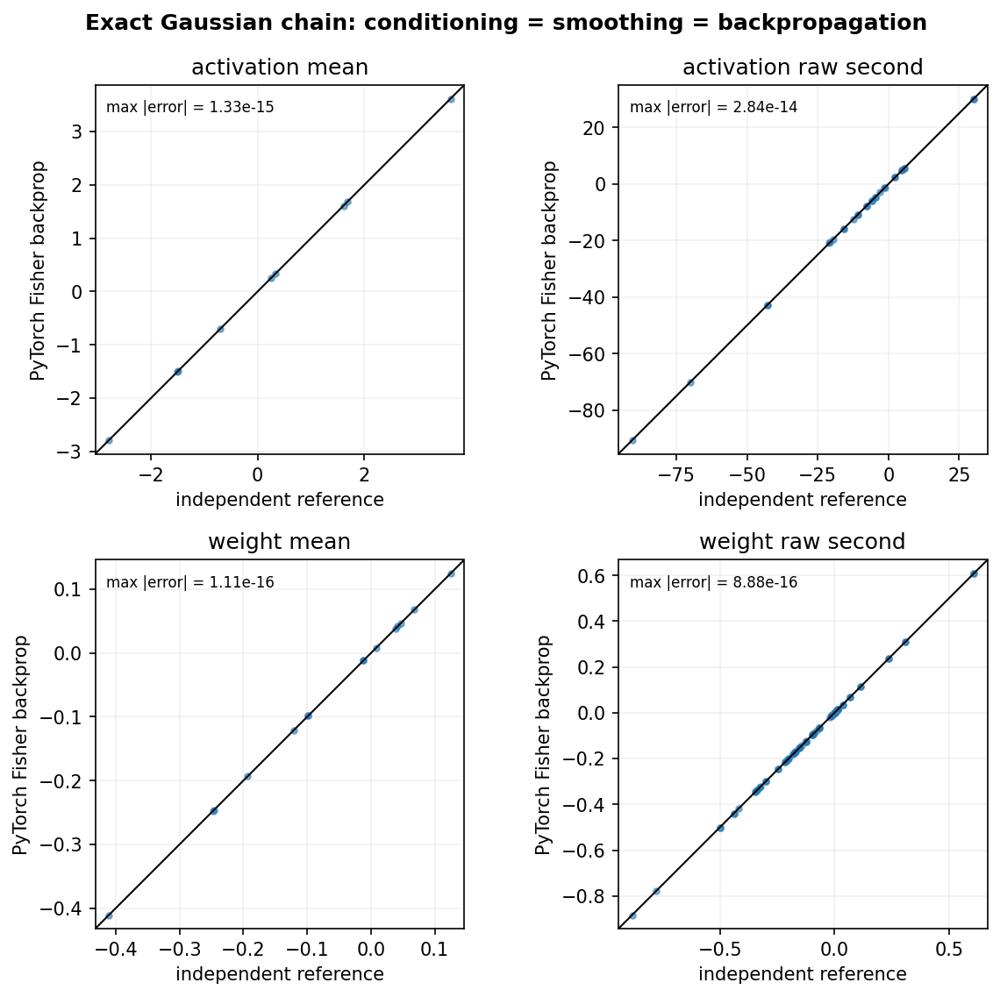

In [27]:
#@title Support: equivalence plot formatting (expand to inspect)
def message_panels(points, title):
    figure, axes = plt.subplots(2, 2, figsize=(8.2, 7.7))
    for axis, (name, pair) in zip(axes.flat, points.items()):
        reference, computed = (value.detach().cpu().numpy() for value in pair)
        agreement_plot(reference, computed, xlabel="independent reference",
                       ylabel="PyTorch Fisher backprop", title=name, ax=axis)
        axis.text(.03, .96, f"max |error| = {np.max(np.abs(reference-computed)):.2e}",
                  transform=axis.transAxes, va="top", fontsize=8)
    figure.suptitle(title, fontweight="bold")
    figure.tight_layout(); plt.show()

message_panels(exact_gaussian_equivalence(),
               "Exact Gaussian chain: conditioning = smoothing = backpropagation")


## EP and MFVI on the same nonlinear graph

The next two figures compare a handwritten literal message calculation with a
local `torch.func.vjp` of the same moment map. EP seeds the reverse traversal
with a log tilted normalizer; MFVI seeds it with an expected log likelihood.
Both figures retain activation and weight signals separately, and retain the
raw-second signal instead of silently treating it as a variance increment.


<details><summary><strong>PyTorch source: native equivalence and approximation experiments</strong></summary>

```python
def exact_gaussian_equivalence(seed: int = 17) -> dict[str, tuple[Tensor, Tensor]]:
    """Coordinates for the exact Gaussian activation/weight four-panel plot."""

    fixture = gaussian_chain_fixture(seed)
    layers, weights, input_belief, observation, observation_covariance = fixture
    forward, candidate = backprop_gaussian_chain(*fixture)
    exact = condition_gaussian_chain(*fixture)
    activation_reference = [
        posterior_signal(prior, posterior)
        for prior, posterior in zip(forward.activations[1:], exact.activations[1:])
    ]
    weight_reference = [
        posterior_signal(prior, posterior) for prior, posterior in zip(weights, exact.weights)
    ]

    def collect(reference, computed, field):
        return torch.cat([getattr(value, field).reshape(-1) for value in reference]), torch.cat(
            [getattr(value, field).reshape(-1) for value in computed]
        )

    return {
        "activation mean": collect(activation_reference, candidate.activations, "delta_mean"),
        "activation raw second": collect(
            activation_reference, candidate.activations, "delta_raw_second"
        ),
        "weight mean": collect(weight_reference, candidate.weights, "delta_mean"),
        "weight raw second": collect(weight_reference, candidate.weights, "delta_raw_second"),
    }

def nonlinear_message_equivalence(
    method: str, seed: int = 7
) -> dict[str, tuple[Tensor, Tensor]]:
    """Literal message equations versus an autodiff VJP on the same closure."""

    if method not in {"ep", "mfvi"}:
        raise ValueError("method must be 'ep' or 'mfvi'")
    torch.manual_seed(seed)
    model = TinyResidualMLP(4, 6, 3).double()
    inputs = DiagonalMoments(torch.randn(16, 4), torch.zeros(16, 4))
    labels = torch.arange(16) % 3
    projected = model.forward_moments(inputs, literal=False)
    literal = model.forward_moments(inputs, literal=True)
    child = categorical_quadrature_head(projected.output, labels, method).signal
    computed, reference = projected.backward(child), literal.backward(child)

    def collect(left, right, field):
        common = sorted(left.keys() & right.keys())
        return torch.cat([getattr(right[key], field).reshape(-1) for key in common]), torch.cat(
            [getattr(left[key], field).reshape(-1) for key in common]
        )

    return {
        "activation mean": collect(
            computed.activations, reference.activations, "delta_mean"
        ),
        "activation raw second": collect(
            computed.activations, reference.activations, "delta_raw_second"
        ),
        "weight mean": collect(computed.parameters, reference.parameters, "delta_mean"),
        "weight raw second": collect(
            computed.parameters, reference.parameters, "delta_raw_second"
        ),
    }

def approximation_benchmark(
    reference_samples: int = 4096,
    ranks: tuple[int, ...] = (1, 4, 16, 64),
    mc_budgets: tuple[int, ...] = (8, 32, 128, 512),
    seed: int = 23,
    method: str = "mfvi",
) -> tuple[list[dict[str, float | str]], dict[str, object]]:
    """Compare native deterministic closures with reparameterized Monte Carlo.

    The returned rows contain measured CPU wall time and relative errors at one
    fixed, randomly initialized Gaussian belief.  The same large Monte Carlo
    run supplies the forward and backward references.  This is a semantic
    approximation study, not a trained-model accuracy claim.
    """

    torch.manual_seed(seed)
    model = TinyResidualMLP(4, 8, 3).double()
    graph = model.network
    inputs = torch.randn(24, 4)
    labels = torch.arange(24) % 3

    reference = _mc_estimate(graph, inputs, labels, reference_samples, seed + 1000, method)
    reference_mean, reference_variance, reference_messages, reference_seconds = reference
    rows: list[dict[str, float | str]] = []

    # Exclude one-time dispatcher/cache initialization from the comparison.
    graph.forward_moments(DiagonalMoments(inputs, torch.zeros_like(inputs)))
    moment_likelihood_gradients(graph, inputs, labels, method)
    start = time.perf_counter()
    passed = graph.forward_moments(DiagonalMoments(inputs, torch.zeros_like(inputs)))
    head = categorical_quadrature_head(passed.output, labels, method)
    diagonal_messages = passed.backward(head.signal).parameters
    diagonal_seconds = time.perf_counter() - start
    rows.append(
        {
            "method": "diagonal moments",
            "budget": 1,
            "seconds": diagonal_seconds,
            "mean_error": _relative_error(passed.output.mean, reference_mean),
            "variance_error": _relative_error(passed.output.variance, reference_variance),
            "mean_message_error": _message_error(
                diagonal_messages, reference_messages, "delta_mean"
            ),
            "second_message_error": _message_error(
                diagonal_messages, reference_messages, "delta_raw_second"
            ),
        }
    )

    estimates: dict[str, object] = {
        "reference": reference,
        "diagonal": (passed.output.mean.detach(), passed.output.variance.detach(), diagonal_messages),
    }
    for rank in ranks:
        _direction_estimate(graph, inputs, labels, rank, seed + rank, method)
        estimate = _direction_estimate(graph, inputs, labels, rank, seed + rank, method)
        mean, variance, messages, seconds = estimate
        name = f"shared directions {rank}"
        estimates[name] = estimate
        rows.append(
            {
                "method": name,
                "budget": 2 * rank,
                "seconds": seconds,
                "mean_error": _relative_error(mean, reference_mean),
                "variance_error": _relative_error(variance, reference_variance),
                "mean_message_error": _message_error(messages, reference_messages, "delta_mean"),
                "second_message_error": _message_error(
                    messages, reference_messages, "delta_raw_second"
                ),
            }
        )
    for samples in mc_budgets:
        _mc_estimate(graph, inputs, labels, samples, seed + samples, method)
        estimate = _mc_estimate(graph, inputs, labels, samples, seed + samples, method)
        mean, variance, messages, seconds = estimate
        name = f"Monte Carlo {samples}"
        estimates[name] = estimate
        rows.append(
            {
                "method": name,
                "budget": samples,
                "seconds": seconds,
                "mean_error": _relative_error(mean, reference_mean),
                "variance_error": _relative_error(variance, reference_variance),
                "mean_message_error": _message_error(messages, reference_messages, "delta_mean"),
                "second_message_error": _message_error(
                    messages, reference_messages, "delta_raw_second"
                ),
            }
        )
    estimates["reference_seconds"] = reference_seconds
    repeat = _mc_estimate(graph, inputs, labels, reference_samples, seed + 2000, method)
    estimates["reference_repeat"] = repeat
    # Centering removes the 2*m*d_m contribution.  A good raw-second signal
    # alone can otherwise hide a bad variance-direction approximation.
    def centered(messages):
        return torch.cat([(messages[k].delta_raw_second - 2*p.mean*messages[k].delta_mean)
                          .detach().reshape(-1) for k, p in sorted(_parameters(graph).items())])
    estimates["centered_reference"] = centered(reference_messages)
    for row in rows:
        key = "diagonal" if row["method"] == "diagonal moments" else row["method"]
        row["centered_message_error"] = _relative_error(
            centered(estimates[key][2]), estimates["centered_reference"])
    estimates["reference_repeat_errors"] = {
        "mean": _relative_error(repeat[0], reference_mean),
        "variance": _relative_error(repeat[1], reference_variance),
        "mean message": _message_error(repeat[2], reference_messages, "delta_mean"),
        "centered second message": _relative_error(centered(repeat[2]), centered(reference_messages)),
    }
    estimates["centered"] = {k: centered(v[2]) for k, v in estimates.items()
                            if isinstance(v, tuple) and len(v) >= 3}
    return rows, estimates
```

</details>


,EP finite update,MFVI canonical update,incorrect MFVI raw increment
0,0.5,0.5,0.0


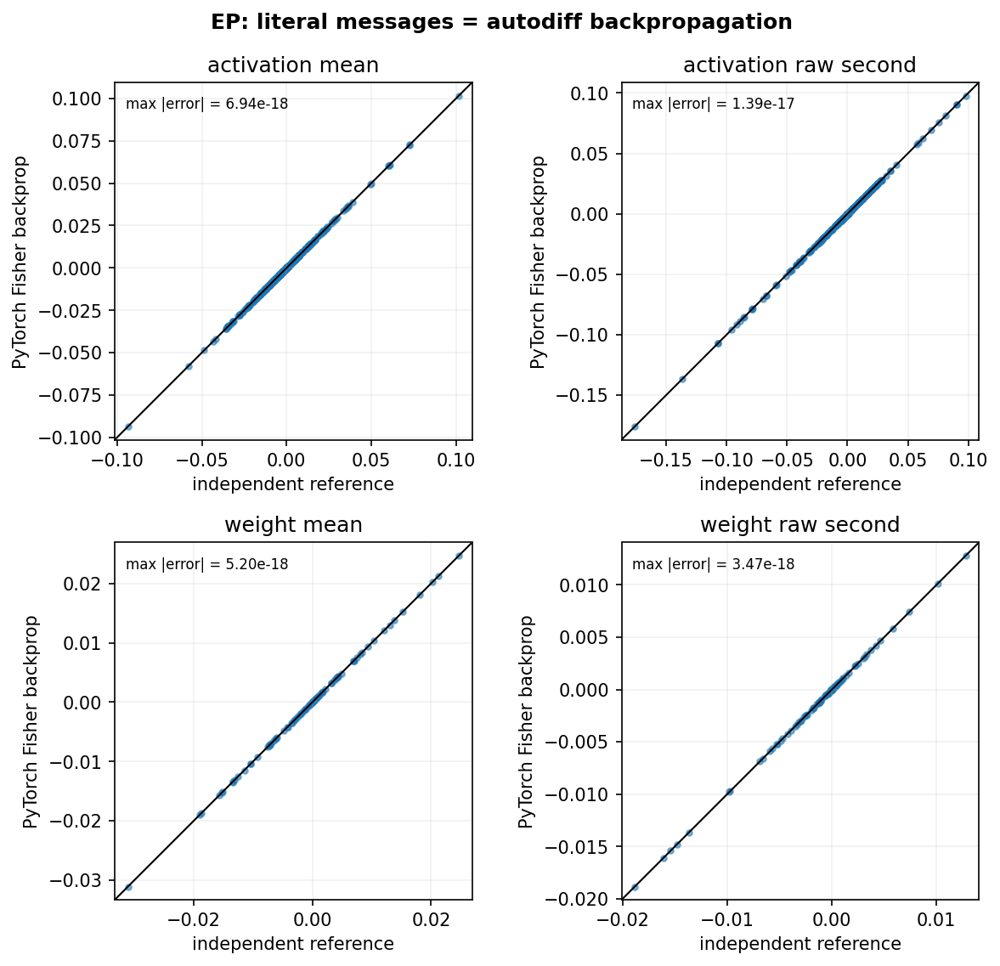

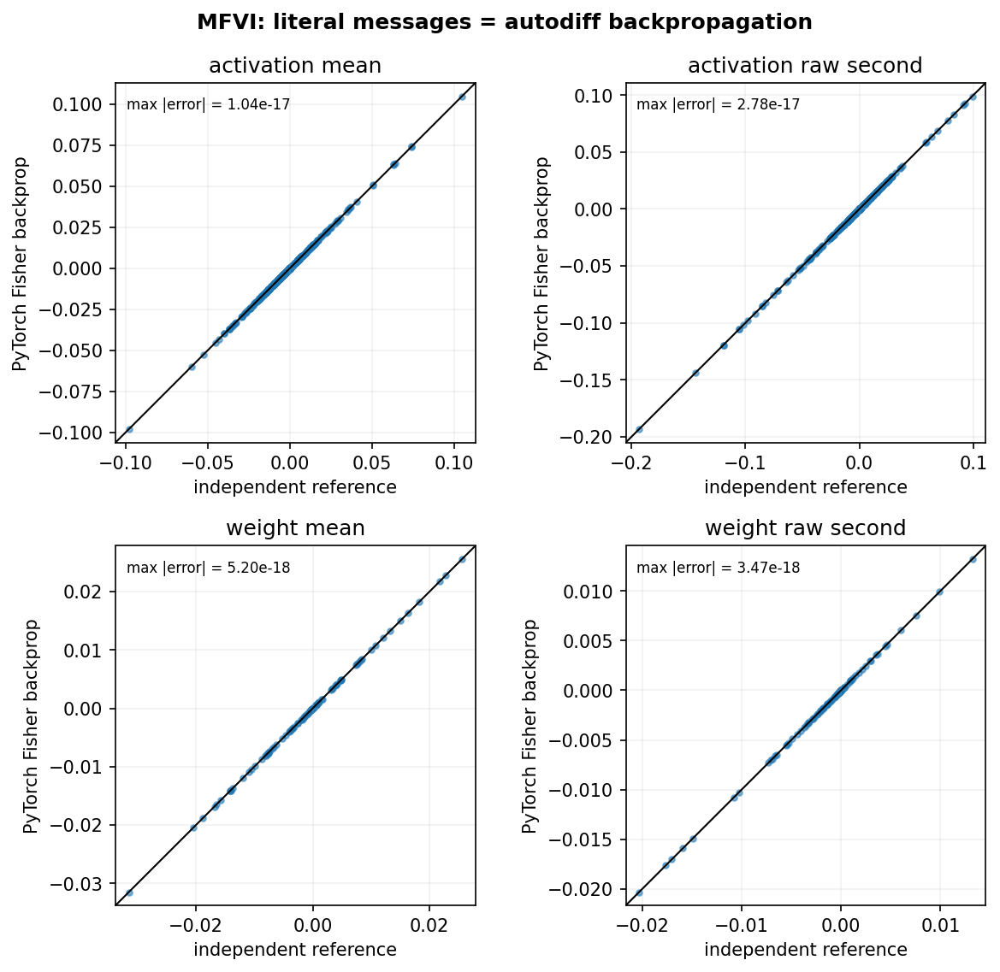

In [30]:
for method in ("ep", "mfvi"):
    message_panels(nonlinear_message_equivalence(method),
                   f"{method.upper()}: literal messages = autodiff backpropagation")

# The scalar counterexample distinguishes a finite EP moment update from the
# canonical MFVI update even when both happen to end at variance 1/2.
q = DiagonalMoments(torch.zeros(1), torch.ones(1))
ep = ep_gaussian_head(q, torch.zeros(1), noise_variance=1.)
vi = mfvi_gaussian_head(q, torch.zeros(1), noise_variance=1.)
display(pd.DataFrame([{
    "EP finite update": tilted_update(q, ep.signal).variance.item(),
    "MFVI canonical update": canonical_mfvi_update(q, vi.signal, q).variance.item(),
    "incorrect MFVI raw increment": (q.variance + vi.signal.delta_raw_second).item(),
}]))


The diagonal identities establish implementation equivalence for each declared
closure. They do not claim that a nonlinear network posterior is exactly a
diagonal Gaussian; that approximation question is measured next.


# 3. Approximation quality versus Monte Carlo and computation

The main accuracy refinement in this section is **sampling-assisted moment
propagation**: integrate a frozen Gaussian surrogate, then use paired network
draws to estimate its nonlinear remainder. The weight belief stays one Gaussian.
The correction is stochastic; it is not the uncorrected 64-direction closure.

Read the residual identity and native implementation first, then the corrected
messages against Monte Carlo. The retained-direction plots are **ablations**:
they explain why covariance retention alone is insufficient. The exact Gaussian,
EP and MFVI message-equivalence checks in Section 2 retain their separate role.

Diagonal activations retain marginal variances. A shared-factor state
$H=m+U^\top\epsilon/\sqrt R$ retains covariance $U^\top U/R$ across examples,
channels and graph branches. A structured weight belief
$W=m+L\xi+\sqrt d\odot\zeta$ has covariance
$LL^\top+\operatorname{Diag}d$.


### Shared factors on a directed acyclic computation graph

Write a boundary as $h\approx m+U\epsilon/\sqrt R$, $\epsilon\sim N(0,I_R)$.
The same columns represent the same latent perturbations at every use of that
boundary. The covariance is $UU^\top/R$; it is never necessary to allocate
this full matrix for a convolutional feature map or a token sequence.
For a local map $y=f(h,w)$, first-order propagation gives
$U_y=J_hU_h+J_wU_w$ and $m_y=f(m_h,m_w)$.
The PyTorch carrier computes these actions locally, not an enormous global Jacobian. In code, factor columns are stored on the leading axis; transpose them to match the column-oriented equations here.

**Residual proposition.** For $y=x+G(x)$, the represented covariance is
$(U_x+U_G)(U_x+U_G)^\top/R$. Expanding gives the two marginal covariances
and both cross terms. If $G(x)=x$, it is $4C_x$; replacing the branches by
independent copies gives $2C_x$. For DenseNet concatenation, stack the factors
to obtain a block covariance with off-diagonal block $U_xU_G^\top/R$.
Both statements follow directly by multiplying the stacked/summed factors. ∎

This is a computation DAG with repeated use, not a claim that all neural
posterior factors form an exact junction tree. Reverse traversal sums
sensitivities; cavity removal concerns likelihood sites. These are related
bookkeeping issues, but not interchangeable operations.

### A diagonal weight posterior can induce strongly correlated activations

For fixed $x$, $y=W^\top x+b$ with independent weight columns has diagonal
output covariance. But for uncertain shared input $X$, independent of the
current weight block, total covariance yields
\[
E[y]=M_W^\top m_X+m_b,\qquad
\operatorname{Cov}(y)=M_W^\top C_XM_W+
\operatorname{Diag}\{V_W^\top(\operatorname{diag}C_X+m_X^2)+v_b\}.
\]
**Proof.** Conditional on $X$, the mean is $M_W^\top X+m_b$ and covariance
is diagonal with entries $\sum_iV_{ij}X_i^2+v_{b_j}$. Average the latter and
add the covariance of the conditional mean. ∎

After one mixing layer, $M_W^\top C_XM_W$ is generally dense. In convolution,
the same filter is reused at every position. Independent weight draws per
pixel would be a different model. The global column identifiers in the
implementation preserve reuse across pixels and examples.

### Nonlinear closure: Gaussian ReLU means and the omitted Hermite residual

For $X\sim N(m,s^2)$, put $a=m/s$, $P=\Phi(a)$ and $p=\phi(a)$.
Integrating over $X>0$ gives $E[\max(X,0)]=mP+sp$ and
$E[\max(X,0)^2]=(m^2+s^2)P+msp$. These follow by substituting
$X=m+sZ$, using $\int_{-a}^\infty z\phi(z)dz=\phi(a)$ and
$\int_{-a}^\infty z^2\phi(z)dz=\Phi(a)-a\phi(a)$.
At $s=0$, use the deterministic value—no invented input noise.

Gaussian integration by parts gives $\operatorname{Cov}(X,\operatorname{ReLU}X)
=s^2P$. Hence the first linear/Hermite projection has slope $P$.
For jointly Gaussian inputs its retained covariance is
$\operatorname{Diag}(P)C\operatorname{Diag}(P)$.
The remaining diagonal variance is nonnegative by orthogonal projection:
$v_{\mathrm{ReLU}}-P^2s^2\ge0$. A diagonal-plus-factor closure may retain
this residual separately. The minimal shared-factor implementation here
retains the first component and **does not claim exact ReLU variance**.
Its omission is an explicit ablation against diagonal marginal matching and
complete-network sampling.

### What a finite covariance sketch guarantees

For diagonal weight variance $V$, choose fixed sign columns $e_r$ and
$U_r=J V^{1/2}e_r$. For independent Rademacher signs,
$E[U_rU_r^\top]=JVJ^\top$. For a scalar projection put
$b=V^{1/2}J^\top a$. Expanding fourth moments gives
$\operatorname{Var}((b^\top e)^2)=2(\|b\|^4-\sum_i b_i^4)$,
so the relative root-mean-square error of the averaged directional variance
is at most $\sqrt{2/R}$. The fourth-moment expansion retains only indices
paired an even number of times; its coefficients are 1 for $b_i^4$ and 6 for
$b_i^2b_j^2$. Subtracting $\|b\|^4$ proves the formula.

These are fixed-belief guarantees. Fitting a model to a fixed sketch can adapt
to its directions, so an independent sketch and sampled posterior prediction
are required after fitting. A low-rank covariance sketch of diagonal weights
is also **not** a learned low-rank weight posterior.

Here is a concrete reason for that qualification. Take weight covariance
$I_P$ and one fixed sign vector $e\in\{-1,+1\}^P$. If a fitted scalar map
has sensitivity $a=e/\sqrt P$, its actual variance under fresh Gaussian
weight perturbations is $a^\top I_Pa=1$, whereas the one-direction estimate
is $(a^\top e)^2=P$. Both equalities follow from $e^\top e=P$.
The usual unbiasedness argument holds when $a$ is fixed independently of
the random probe; it cannot be reapplied after choosing $a$ from that probe.
This linear counterexample explains why retaining covariance and satisfying
the local derivative identities do not alone guarantee trained-belief fidelity.
It is a possible mechanism to investigate, not proof that it caused a particular
experimental discrepancy. Independent-direction and shared-network checks distinguish that question from ordinary sampling variability; the small fixture below is not a learned-network diagnosis.

### Why a small number of directions can give a noisy covariance

For a fixed linearization, let $z_r\sim N(0,C)$ independently and
$\widehat C=R^{-1}\sum_r z_rz_r^\top$, with the mean known to be zero.
Then
\[
E\|\widehat C-C\|_F^2
=\frac{(\operatorname{tr}C)^2+\|C\|_F^2}{R}.
\]
**Proof.** Independence makes the variance of the average $1/R$ times that of
one outer product. For entries $i,j$, the Gaussian fourth-moment identity is
$E[z_i^2z_j^2]=C_{ii}C_{jj}+2C_{ij}^2$. Subtract $C_{ij}^2$ to obtain
$\operatorname{Var}(z_iz_j)=C_{ii}C_{jj}+C_{ij}^2$; sum over $i,j$.
For sign sketches $z=Ae$, the fourth moment has the same Gaussian terms minus
$2\sum_k A_{ik}^2A_{jk}^2$, so the displayed expression is an upper bound. ∎

Thus relative root-mean-square covariance error depends on
$\sqrt{[1+(\operatorname{tr}C)^2/\|C\|_F^2]/R}$, not just parameter count.
For $d$ equal-variance independent outputs this is $\sqrt{(d+1)/R}$.
A sketch can preserve shared-variable semantics and still have substantial
finite-direction error. Keeping a diagonal residual, shrinking noisy
off-diagonal entries, or allocating more directions are distinct remedies;
none removes nonlinear closure bias. This explains why the plots compare
rank and sampling uncertainty rather than using “correlated” as a certificate
of accurate covariance.

### Structured weight beliefs: $D+LL^\top$

This is a mathematical extension. The reported reproduction configurations
use diagonal weight beliefs; their correlated **activation** factors do not
change that weight family. A learned structured weight posterior would need
its own objective, updates and full-training evaluation.

A correlated generator is $w=m+D^{1/2}\epsilon+Lz$, with independent standard
Gaussians $\epsilon,z$. Its covariance follows by expanding the outer product
and observing that the two cross expectations vanish. Store $P$ diagonal
entries and $Pr$ factor entries, not a $P\times P$ matrix.
The matrix determinant lemma gives
$\log|D+LL^\top|=\log|D|+\log|I+L^\top D^{-1}L|$;
Woodbury gives its inverse using an $r\times r$ solve. For an isotropic prior
$N(m_0,\sigma_0^2I)$ the Gaussian KL uses
$\mathrm{tr}(D)+\|L\|_F^2$, $\|m-m_0\|^2$, and that determinant.
These identities make structured VI feasible without a dense weight covariance.

Explicitly, with $K=I+L^\top D^{-1}L$,
$C^{-1}=D^{-1}-D^{-1}LK^{-1}L^\top D^{-1}$; multiplying by $D+LL^\top$
verifies the inverse. The determinant identity follows by evaluating the
same block determinant using either Schur complement. Hence, for
$p_0=N(m_0,\sigma_0^2I_P)$,
$\mathrm{KL}(q\Vert p_0)=\tfrac12[(\operatorname{tr}D+\|L\|_F^2+
\|m-m_0\|^2)/\sigma_0^2-P+P\log\sigma_0^2-\log|C|]$.
This follows by taking the expectation of the Gaussian log-density ratio.
It assumes strictly positive diagonal $D$; a singular low-rank-only law
requires separate support analysis.

One column of $L$ can jointly change LoRA factors in several attention blocks.
Block-diagonal $L$ forbids those cross-block correlations; a global $L$ retains
them. If upstream and current-layer weights share $z$, then the current weight
and its incoming activation are correlated. Reusing an independent-layer
moment formula would drop this dependence. Common latent columns handle its
first-order contribution; second-order products need additional moments.

### Error accounting rather than automatic equality claims

Suppose $\|D^2 f\|\le M$ on the relevant neighborhood and
$\delta\sim N(0,C)$. Taylor's remainder satisfies
$\|r(\delta)\|\le M\|\delta\|^2/2$, hence
$\|E f(m+\delta)-f(m)\|\le M\mathrm{tr}(C)/2$.
Let $A=J\delta$. Since
$\operatorname{Cov}(A+r)-\operatorname{Cov}(A)$ is two cross terms plus
$\operatorname{Cov}(r)$, Cauchy–Schwarz bounds its norm by
$2\sqrt{E\|A\|^2 E\|r\|^2}+E\|r\|^2$, with
$E\|r\|^2\le M^2[(\mathrm{tr}C)^2+2\mathrm{tr}(C^2)]/4$.
The Gaussian fourth-moment identity gives the last expression. A local bound
needs a tail term if the Hessian bound holds only locally. ReLU requires
piecewise/crossing analysis rather than pretending it has a bounded classical
Hessian everywhere. Gradient-approximation bounds require bounds on derivatives
of the *loss gradient*, not just good forward moment estimates.

Thus Monte Carlo converges to the learned belief's actual neural distribution;
it need not converge to a fixed Gaussian closure. The plots should reveal the
approximation gap, its depth/rank dependence and its sampling uncertainty.


In [34]:
from bayesify_torch.correlation import *

class SharedMoments:
    mean: Tensor
    factors: Tensor  # [rank, *mean.shape]

    def __post_init__(self) -> None:
        if self.factors.ndim != self.mean.ndim + 1 or self.factors.shape[1:] != self.mean.shape:
            raise ValueError("factors must have shape [rank, *mean.shape]")

    @property
    def rank(self) -> int:
        return self.factors.shape[0]

    @property
    def variance(self) -> Tensor:
        return self.factors.square().mean(0)

class StructuredGaussian:
    """One Gaussian ``N(m, diag(d) + L L^T)`` over a flattened parameter block."""

    mean: Tensor
    diagonal: Tensor
    factors: Tensor  # [rank, mean.numel()], rows are columns of L transposed

    def __post_init__(self) -> None:
        if self.diagonal.shape != self.mean.shape or torch.any(self.diagonal < 0):
            raise ValueError("diagonal residual must be nonnegative and match the mean")
        if self.factors.ndim != 2 or self.factors.shape[1] != self.mean.numel():
            raise ValueError("factors must have shape [rank, mean.numel()]")

    def covariance(self) -> Tensor:
        return torch.diag(self.diagonal.reshape(-1)) + self.factors.mT @ self.factors

    def rsample(self, samples: int = 1, generator: torch.Generator | None = None) -> Tensor:
        shape = (samples,) + self.mean.shape
        local = torch.randn(shape, dtype=self.mean.dtype, device=self.mean.device, generator=generator)
        global_noise = torch.randn(
            (samples, len(self.factors)),
            dtype=self.mean.dtype,
            device=self.mean.device,
            generator=generator,
        )
        correlated = (global_noise @ self.factors).reshape(shape)
        return self.mean + self.diagonal.sqrt() * local + correlated

def relu_shared(state: SharedMoments) -> SharedMoments:
    """Exact Gaussian marginal mean plus first-Hermite covariance directions.

    With ``s=sqrt(v)``, ``a=m/s``, ``P=Phi(a)`` and ``p=phi(a)``, the exact
    marginal mean is ``m P + s p``.  Price's identity gives the first-order
    response ``d E[ReLU(H)] / dm = P``; hence each shared direction becomes
    ``P U_r``.  Higher Hermite covariance components are deliberately omitted.
    """
    variance = state.variance
    positive = variance > torch.finfo(variance.dtype).tiny
    safe = torch.where(positive, variance, torch.ones_like(variance))
    scale = safe.sqrt()
    limit = 40.0 if variance.dtype == torch.float64 else 12.0
    central = positive & (state.mean.abs() <= limit * scale)
    mean0 = torch.where(central, state.mean, torch.zeros_like(state.mean))
    scale0 = torch.where(central, scale, torch.ones_like(scale))
    standardized = mean0 / scale0
    probability = 0.5 * torch.erfc(-standardized / math.sqrt(2))
    density = torch.exp(-0.5 * standardized.square()) / math.sqrt(2 * math.pi)
    mean = torch.where(central, mean0 * probability + scale0 * density, F.relu(state.mean))
    gate = torch.where(central, probability, (state.mean > 0).to(state.mean.dtype))
    return SharedMoments(mean, state.factors * gate.unsqueeze(0))

def gaussian_readout(
    x: SharedMoments,
    weight_mean: Tensor,
    weight_variance: Tensor,
    bias_mean: Tensor,
    bias_variance: Tensor,
) -> tuple[Tensor, Tensor]:
    """Exact readout moments for the supplied hidden factors and diagonal head.

    ``Cov(z)=W Cov(h) W^T + Diag(E[h^2] Var(W)^T + Var(b))``.  This is exact
    for the represented hidden covariance; approximation occurred upstream.
    """
    mean = F.linear(x.mean, weight_mean, bias_mean)
    projected = torch.einsum("rbi,oi->rbo", x.factors, weight_mean)
    hidden_covariance = torch.einsum("rbi,rbj->bij", projected, projected) / x.rank
    hidden_second = x.mean.square() + x.variance
    independent = F.linear(hidden_second, weight_variance, bias_variance)
    return mean, hidden_covariance + torch.diag_embed(independent)


### Sampling-assisted moment propagation: integrate the nonlinear remainder

Use the Gaussian moment calculation as a control variate, and sample the part
that its nonlinear approximation omits. This retains a single Gaussian weight
belief while providing a measurable accuracy refinement for its messages.

Write $W=m+\sqrt v\odot\epsilon$, with standard-normal density $\phi$.
Freeze the linear logit approximation
$z_0(W)=f(m_*)+J_*(W-m_*)$ at the current snapshot. Let $h=\log p$ for
MFVI and $h=p$ for EP, and let $h_0$ apply the same likelihood to $z_0$.
For an integration proposal $r$ and its known weight $a=\phi/r$,
$E_\phi h=E_\phi h_0+E_r[a(h-h_0)]$.
The proof is the cancellation
$\int\phi h_0+\int r(\phi/r)(h-h_0)=\int\phi h$.
Differentiating under the integral, for integrable derivatives and fixed
surrogate/proposal coefficients, gives the identical decomposition for
$\partial_m E h$ and $\partial_v E h$. Pairing both paths with the same noise preserves their covariance.
For direct integration, $\operatorname{Var}(h-h_0)=\operatorname{Var}(h)+\operatorname{Var}(h_0)-2\operatorname{Cov}(h,h_0)$; variance decreases relative to sampling $h$ alone when
$2\operatorname{Cov}(h,h_0)>\operatorname{Var}(h_0)$. The identity alone does not guarantee variance reduction.

For EP, integrate both $Z=E p$ and $\partial Z$ before dividing by $Z$;
the finite-sample ratio is consistent, not generally unbiased. For MFVI,
integrate $\partial E\log p$ directly. The Gaussian encoding remains
$d_m=v\odot g_m$, $c=2v^2\odot g_v$ and $d_s=2m\odot d_m+c$.
Finite EP and canonical MFVI updates remain distinct, as in the earlier
derivation; the code retains that distinction.

To resolve small derivatives, one may use the following antithetic
importance rule: $r(\epsilon)=\tfrac12\phi(\epsilon)+\tfrac12\phi(\epsilon-\delta)$,
where $\delta=\sqrt v\odot(J_{\rm competitor}-J_y)$ and
$a=2/[1+\exp(\delta^\top\epsilon-\|\delta\|^2/2)]\le2$.
The four nodes $\epsilon,-\epsilon,\delta+\epsilon,\delta-\epsilon$
form one independent integration group. This is an integration proposal;
the weight belief itself stays a single Gaussian.
The frozen surrogate is a function of $W$ anchored at $(m_*,J_*)$: freeze its
coefficients, not the dependence of $W=m+\sqrt v\odot\epsilon$ on the current
belief. Likewise freeze a proposal chosen at that snapshot, and retain all
ratio terms needed for the declared coordinate derivative. A convenient
reparameterized implementation samples $\epsilon$ and uses fixed proposal
coefficients in epsilon space. Stopping the entire surrogate graph would
remove the derivative one is trying to integrate.


**PyTorch source: correct the nonlinear residual before encoding the message**

```python
def residual_backward(q, gaussian, nonlinear, surrogate, weight, method="mfvi"):
    """Correct unnormalized expectations, then encode the Gaussian message.

    Each dictionary contains gm, gv; the sampled ones also contain
    log_likelihood. Sample arrays are [draw, parameter]. Gaussian gm/gv
    integrate derivatives of E[h0], NOT of log E[h0] for EP.
    Integration nodes, proposal ratios and the surrogate stay fixed during
    this derivative calculation. No derivative of a fitted proposal is added.
    """
    if method not in ("mfvi", "ep") or torch.any(q.variance <= 0):
        raise ValueError("use mfvi/ep and a positive-variance Gaussian")
    if torch.any(weight < 0) or not torch.isfinite(weight).all():
        raise ValueError("importance ratios must be finite and nonnegative")
    a = nonlinear["log_likelihood"].exp() if method == "ep" else torch.ones_like(weight)
    b = surrogate["log_likelihood"].exp() if method == "ep" else torch.ones_like(weight)
    gm = gaussian["gm"] + (weight[:, None] * (
        a[:, None] * nonlinear["gm"] - b[:, None] * surrogate["gm"])).mean(0)
    gv = gaussian["gv"] + (weight[:, None] * (
        a[:, None] * nonlinear["gv"] - b[:, None] * surrogate["gv"])).mean(0)
    Z = gaussian["Z"] + (weight * (nonlinear["log_likelihood"].expm1()
        - surrogate["log_likelihood"].expm1())).mean() if method == "ep" else q.mean.new_tensor(1.)
    if not torch.isfinite(Z) or Z <= 0 or not torch.isfinite(gm).all() or not torch.isfinite(gv).all():
        raise ValueError("invalid residual estimate; do not clip a failed EP normalizer")
    gradient = EuclideanAdjoint(gm / Z, gv / Z)
    return ResidualResult(gradient, encode_diagonal(q, gradient), Z)
```


<details><summary><strong>PyTorch source: frozen Gaussian surrogate and paired network integration</strong></summary>

```python
def network_residual_backward(predict, q, label, *, pairs=128, head_power=14, seed=173):
    """A query's logits and weight signals, using a frozen full-class surrogate.

    predict(w) accepts a FLAT parameter vector and returns K logits. Its
    K-by-P Jacobian is intended for diagnostics/small query sets, not a dense
    P-by-P approximation. Each antithetic group uses the SAME weight noise
    in the nonlinear and surrogate paths. Returned methods are separate
    MFVI E[log p] and EP log E[p] calculations at the supplied belief.
    """
    if q.mean.ndim != 1 or q.mean.shape != q.variance.shape or torch.any(q.variance <= 0):
        raise ValueError("q must be a flat, positive-variance Gaussian")
    if pairs < 1 or head_power < 1:
        raise ValueError("positive integration budgets are required")
    # Detaching freezes the reference point, J, variance and proposal. The
    # pathwise derivatives below act on w only, not on how J was constructed.
    m, v = q.mean.detach(), q.variance.detach()
    q = DiagonalMoments(m, v)
    z = predict(m).detach()
    J = torch.func.jacrev(predict)(m).detach()
    K = z.numel()
    if z.ndim != 1 or not 0 <= label < K or K < 2:
        raise ValueError("predict must return a vector of at least two logits")
    C = (J * v) @ J.T
    other = [i for i in range(K) if i != label]
    eye = torch.eye(K, device=m.device, dtype=m.dtype)
    D = eye[other] - eye[label]
    a = D @ z
    # No artificial jitter: a singular contrast covariance is a different
    # integration problem and must be reported, not silently changed.
    L = torch.linalg.cholesky(D @ C @ D.T)
    competitor_index = int(a.argmax())
    delta = L[competitor_index]
    u = torch.quasirandom.SobolEngine(K - 1, scramble=True, seed=seed).draw_base2(
        head_power - 1, dtype=m.dtype).to(m.device)
    normal = torch.special.ndtri(u)
    nodes = torch.cat((normal, normal + delta))
    # r(e) = [phi(e) + phi(e-delta)]/2; hence phi/r = 2 sigmoid(delta²/2-e.delta).
    ratio = 2 * torch.sigmoid(delta.square().sum() / 2 - nodes @ delta)
    logits = (a + nodes @ L.T) @ eye[other]
    p = logits.softmax(-1)
    score = eye[label] - p
    H = p[:, :, None] * p[:, None, :] - torch.diag_embed(p)
    py = p[:, label]

    shift = v.sqrt() * (J[other[competitor_index]] - J[label])
    generator = torch.Generator(device=m.device).manual_seed(seed + 1)
    logp = lambda w: predict(w).log_softmax(-1)[label]
    # Stream independent groups. Keeping all S-by-P weights/gradients at once
    # adds no statistical information and can exceed accelerator memory.
    correction = {method:[torch.zeros_like(m),torch.zeros_like(v),m.new_tensor(0.)]
                  for method in ("mfvi","ep")}
    for begin in range(0,pairs,16):
        e = torch.randn(min(16,pairs-begin),m.numel(),device=m.device,dtype=m.dtype,generator=generator)
        # Four dependent nodes per independent group.
        e = torch.stack((e,-e,e+shift,-e+shift),1).flatten(0,1)
        weight = 2*torch.sigmoid(shift.square().sum()/2-e@shift)
        weights = m+v.sqrt()*e
        ell = torch.func.vmap(logp,chunk_size=16)(weights).detach()
        g = torch.func.vmap(torch.func.grad(logp),chunk_size=16)(weights).detach()
        lp0 = (z+(e*v.sqrt())@J.T).log_softmax(-1)
        g0 = (eye[label]-lp0.exp())@J
        for method in correction:
            a=ell.exp() if method=="ep" else torch.ones_like(ell)
            b=lp0[:,label].exp() if method=="ep" else torch.ones_like(ell)
            difference=weight[:,None]*(a[:,None]*g-b[:,None]*g0)
            correction[method][0]+=difference.sum(0)/(4*pairs)
            correction[method][1]+=(difference*e/(2*v.sqrt())).sum(0)/(4*pairs)
            if method=="ep":correction[method][2]+=(weight*(ell.expm1()-lp0[:,label].expm1())).sum()/(4*pairs)
    result = {}
    for method in ("mfvi", "ep"):
        factor = py if method == "ep" else torch.ones_like(py)
        gz = (ratio[:, None] * factor[:, None] * score).mean(0)
        hessian = H + score[:, :, None] * score[:, None, :] if method == "ep" else H
        GC = (ratio[:, None, None] * factor[:, None, None] * hessian).mean(0) / 2
        # Price's identity: d E[h]/dC = E[Hessian h]/2.
        gaussian = dict(gm=J.T @ gz, gv=torch.einsum("ik,ij,jk->k", J, GC, J),
                        Z=(ratio * py).mean() if method == "ep" else m.new_tensor(1.))
        dm,dv,dZ=correction[method];Z=gaussian["Z"]+dZ
        gradient=EuclideanAdjoint((gaussian["gm"]+dm)/Z,(gaussian["gv"]+dv)/Z)
        if not torch.isfinite(Z) or Z<=0 or not all(torch.isfinite(g).all() for g in gradient):
            raise ValueError("invalid residual estimate; do not clip a failed EP normalizer")
        result[method]=ResidualResult(gradient,encode_diagonal(q,gradient),Z)
    return result
```

</details>


<details><summary><strong>One graph, optional shared activation covariance</strong></summary>

```python
def shared_layer(layer, parents, beliefs, noise, *, readout=False):
    """Extend the SAME native layer using shared Gaussian directions.

    Hidden boundaries carry (m,U), U.shape=[rank,batch,...]. A terminal affine
    readout integrates its independent Gaussian weights analytically. Local
    VJPs act on these factors; a finite-rank covariance is never inverted.
    """
    from .layers import GaussianParameter, MomentReLU
    from torch.func import functional_call, jvp, vmap
    states = tuple(SharedMoments(*p) for p in parents)
    if isinstance(layer, MomentReLU):
        y = relu_shared(states[0]);return y.mean, y.factors
    names = tuple(n for n,p in layer.named_children() if isinstance(p,GaussianParameter))
    means = tuple(q[0] for q in beliefs)
    factors = tuple(q[1].sqrt() * e for q,e in zip(beliefs,noise))
    if readout:
        x = states[0];w,b = beliefs;rank = x.rank
        projected = F.linear(x.factors, w[0])
        diagonal = F.linear(x.mean.square()+x.variance, w[1], b[1])
        root = torch.cat((projected.permute(1,2,0)/math.sqrt(rank),
                          torch.diag_embed(diagonal.sqrt())), -1)
        return F.linear(x.mean,w[0],b[0]),root
    def point(*arguments):
        weights = {name+'.mean':a for name,a in zip(names,arguments[len(states):])}
        return functional_call(layer,weights,arguments[:len(states)],strict=False)
    primals = tuple(x.mean for x in states)+means
    tangents = tuple(x.factors for x in states)+factors
    mean = point(*primals)
    U = vmap(lambda *d:jvp(point,primals,d)[1])(*tangents)
    return mean,U

def shared_forward(graph,inputs,rank=4,seed=41,beliefs=None,noise=None):
    """Diagonal and correlated paths share the graph and parameter objects.

    Noise IDs are reused across branches. One immutable forward snapshot is
    retained for the complete reverse traversal. No optimizer or model copy
    is introduced by the covariance extension.
    """
    from .inference import named_gaussian_parameters
    from .layers import GaussianParameter,MomentLinear
    if rank<1:raise ValueError('rank must be positive')
    if beliefs is None:beliefs={n:(p.mean,p.variance) for n,p in named_gaussian_parameters(graph)}
    if noise is None:
        generator=torch.Generator(device=inputs.device).manual_seed(seed)
        noise={n:(2*torch.randint(0,2,(rank,)+m.shape,device=m.device,generator=generator)-1).to(m.dtype)
               for n,(m,v) in sorted(beliefs.items())}
    states={'input':SharedMoments(inputs,inputs.new_zeros((rank,)+inputs.shape))};records=[]
    for index,node in enumerate(graph.nodes):
        layer=graph.layers[node.name]
        names=tuple(node.name+'.'+n for n,p in layer.named_children() if isinstance(p,GaussianParameter))
        parents=tuple((states[n].mean,states[n].factors) for n in node.parents)
        qs=tuple(beliefs[n] for n in names);es=tuple(noise[n] for n in names)
        readout=index==len(graph.nodes)-1
        if readout and not isinstance(layer,MomentLinear):
            raise ValueError('the full-covariance terminal boundary must be an affine readout')
        local=lambda ps,ws,layer=layer,es=es,readout=readout:shared_layer(layer,ps,ws,es,readout=readout)
        out=local(parents,qs)
        states[node.name]=RootMoments(*out) if readout else SharedMoments(*out)
        records.append((node,names,parents,qs,local))
    return SharedPass(states[graph.nodes[-1].name],states,tuple(records),beliefs)

class SharedPass:
    output: RootMoments
    states: dict
    records: tuple
    beliefs: dict

    def backward(self, child):
        """Local VJP traversal, then Gaussian encoding at persistent weights."""
        from .geometry import DiagonalMoments,EuclideanAdjoint,encode_diagonal
        pending={self.records[-1][0].name:child};weight={}
        def add(table,name,pair):
            table[name]=pair if name not in table else tuple(a+b for a,b in zip(table[name],pair))
        for node,names,parents,beliefs,local in reversed(self.records):
            if node.name not in pending:continue
            _,pull=torch.func.vjp(local,parents,beliefs)
            dp,dw=pull(pending[node.name])
            for n,g in zip(node.parents,dp):add(pending,n,g)
            for n,g in zip(names,dw):add(weight,n,g)
        signals={n:encode_diagonal(DiagonalMoments(*self.beliefs[n]),EuclideanAdjoint(*g))
                 for n,g in weight.items()}
        return weight,pending,signals

def shared_likelihood(graph,inputs,labels,rank=4,seed=41,beliefs=None,
                      method='mfvi',power=1.,scale=1.,noise=None):
    passed=shared_forward(graph,inputs,rank,seed,beliefs,noise)
    head=lambda m,r:root_objective(RootMoments(m,r),labels,method,power,scale)
    child,value=torch.func.grad_and_value(head,argnums=(0,1))(*passed.output)
    weights,activations,signals=passed.backward(child)
    return value,weights,activations,signals,passed
```

</details>


`residual_backward` implements the displayed expectation identity for both
objectives. Its inputs are unnormalized likelihood derivatives for EP and
expected-log-likelihood derivatives for MFVI. The corrected derivatives pass
through the same `encode_diagonal` function as the layer messages. Finite belief
updates remain the separate EP raw-moment and MFVI canonical operations.

The independent tests in `tests/test_residual.py` check linear Gaussian-head
integration against Gauss–Hermite quadrature, nonlinear paired integration,
the EP normalizer, and invalid-estimate rejection. The integration correction
is stochastic; it does not turn the nonlinear network into an exact Gaussian.


### What the approximation errors measure

For $S$ complete-network draws shared across diagnostic inputs, compute
$\widehat m=S^{-1}\sum_s f_{W_s}(X)$ and
$\widehat v=(S-1)^{-1}\sum_s(f_{W_s}(X)-\widehat m)^2$.
A relative discrepancy is $\|\widehat t-t_{\rm ref}\|_2/\|t_{\rm ref}\|_2$.
When the reference norm is zero, report the absolute discrepancy instead;
an arbitrary denominator floor is not a relative-error guarantee.
For independent batches at budget $B$, root-mean-square error is
$[K_B^{-1}\sum_b\|\widehat t_b-t_{\rm ref}\|_2^2]^{1/2}/\|t_{\rm ref}\|_2$.
Pointwise $\pm1.96$ MC standard-error bars, when displayed, concern the finite
reference estimator, not the learned posterior or the approximation's bias.
An independent repeat checks stability; it is not itself a confidence interval.
All comparisons must use the same objective, sum/average normalization,
coordinate system, weight belief and set of reported coordinates.


For a Gaussian ReLU marginal, the mean is exact. The first-Hermite factor map
uses $E[\phi'(Z)]=\Phi(m/\sigma)$; it is a declared covariance closure, not an
exact nonlinear joint distribution. The executable experiment below creates
one native PyTorch Gaussian belief and compares diagonal moments, shared
directions, and finite Monte Carlo budgets with a 16,384-draw reparameterized
reference, repeated independently to check reference stability. MFVI uses
the sum of expected log factors; EP uses the sum of per-example log tilted
normalizers at a fixed cavity. These are different objectives. The latter
checks local messages, not a complete multi-site EP iteration.


In [42]:
#@title Support: integration benchmark and plotting (expand to inspect)
#@title Python / PyTorch (expand to inspect)
studies = {method: approximation_benchmark(reference_samples=16384, method=method)
           for method in ("mfvi", "ep")}
for method, (records, values) in studies.items():
    display(HTML("<b>Small nonlinear fixture: "+method.upper()+"</b>"))
    display(pd.DataFrame(records)[["method", "seconds", "variance_error",
         "mean_message_error", "centered_message_error"]].round(5))
    display(pd.DataFrame([values["reference_repeat_errors"]], index=["Independent MC repeat"]))


,method,seconds,variance_error,mean_message_error,centered_message_error
0,diagonal moments,0.00839,0.08566,0.04195,0.19646
1,shared directions 1,0.00415,0.62903,0.32580,2.77288
2,shared directions 4,0.00424,0.60991,0.13743,1.26512
3,shared directions 16,0.00444,0.29910,0.07588,0.78879
4,shared directions 64,0.00503,0.24811,0.03523,0.32075
5,Monte Carlo 8,0.00342,0.33696,0.31520,2.16278
6,Monte Carlo 32,0.00356,0.24288,0.12633,0.82135
7,Monte Carlo 128,0.00426,0.08912,0.11058,0.42331
8,Monte Carlo 512,0.00652,0.06555,0.05175,0.23592


,mean,variance,mean message,centered second message
Independent MC repeat,0.009428,0.01288,0.010319,0.055722


,method,seconds,variance_error,mean_message_error,centered_message_error
0,diagonal moments,0.00838,0.08566,0.01434,0.10753
1,shared directions 1,0.00426,0.62903,0.14927,2.04637
2,shared directions 4,0.00437,0.60991,0.10264,0.85607
3,shared directions 16,0.00451,0.29910,0.03733,0.39933
4,shared directions 64,0.00509,0.24811,0.02729,0.21358
5,Monte Carlo 8,0.00341,0.33696,0.30496,3.35332
6,Monte Carlo 32,0.00351,0.24288,0.12745,1.45776
7,Monte Carlo 128,0.00425,0.08912,0.10460,0.67374
8,Monte Carlo 512,0.00613,0.06555,0.04759,0.43078


,mean,variance,mean message,centered second message
Independent MC repeat,0.009428,0.01288,0.009388,0.094056


### What the R/TensorFlow repair established

The earlier R/TensorFlow experiment applied this residual correction to 236
selected parameter coordinates spanning the ResNet-20 blocks. On the first of
four predeclared CIFAR-10 inputs, 2,048 correction evaluations were compared with
an independent 8,192-network reference. Relative errors were:

| Method | Mean signal: baseline → corrected ↓ | Raw-second signal: baseline → corrected ↓ |
|---|---:|---:|
| MFVI | 68.30% → 4.64% | 68.09% → 4.34% |
| EP | 50.29% → 9.09% | 52.13% → 9.14% |

Mean and raw-second errors decreased on all four inputs. This is the successful
sampling-assisted repair; it is not evidence that a 64-direction closure alone
is accurate. The raw-second signal is $d_s=2m\odot d_m+c$, whereas the centered
variance signal is $c=2v^2\odot g_v$. A large mean contribution can hide errors
in $c$. In this earlier experiment the corrected centered-signal error was about
133% for both methods, with very large MC uncertainty. The readout experiment
below therefore checks mean and centered variance separately with a larger,
independent reference. The two studies have different coordinates and references;
their percentages are not a common learning curve.

The source CSV, including every input and its MC standard error, is
`r_residual_confirmation.csv` in the supplied matched evidence. These are recorded
R/TensorFlow results, not newly executed full-network experiments in every backend.

## Sampling-assisted readout messages against Monte Carlo

Keep the learned ResNet-20 MFVI or EP belief and CIFAR-10 test input 0 fixed.
An independent **524,288-network** reference measures mean and centered-variance
signals, $d_m=v\odot g_m$ and $c=2v^2\odot g_v$. These are backward sensitivities,
not posterior variances. Both plot axes use the same units and scale; the diagonal
is ideal agreement.

The first figure shows the paired residual correction at 4,096 and 16,384
evaluations. The next two figures are closure ablations: forward variance against
MC, then forward/backward error versus retained directions. They do not represent
the repaired method. Antithetic-group reference standard errors are about 0.25%
for logit variance, 0.88%/0.75% for MFVI mean/variance signals and 2.31%/1.39% for EP.

The residual readout values and complete-network reference were computed in
PyTorch and are shared numerical evidence across the readers. Each framework
renders its own plots. The closure ablations use independently computed native
backend values: 80 checks agree within $1.82\times10^{-13}$ in float64.
Implementation agreement does not imply approximation accuracy. The selected-
coordinate R study above and this readout-only study establish different scopes;
neither establishes a matched all-layer corrected training run in all three backends.


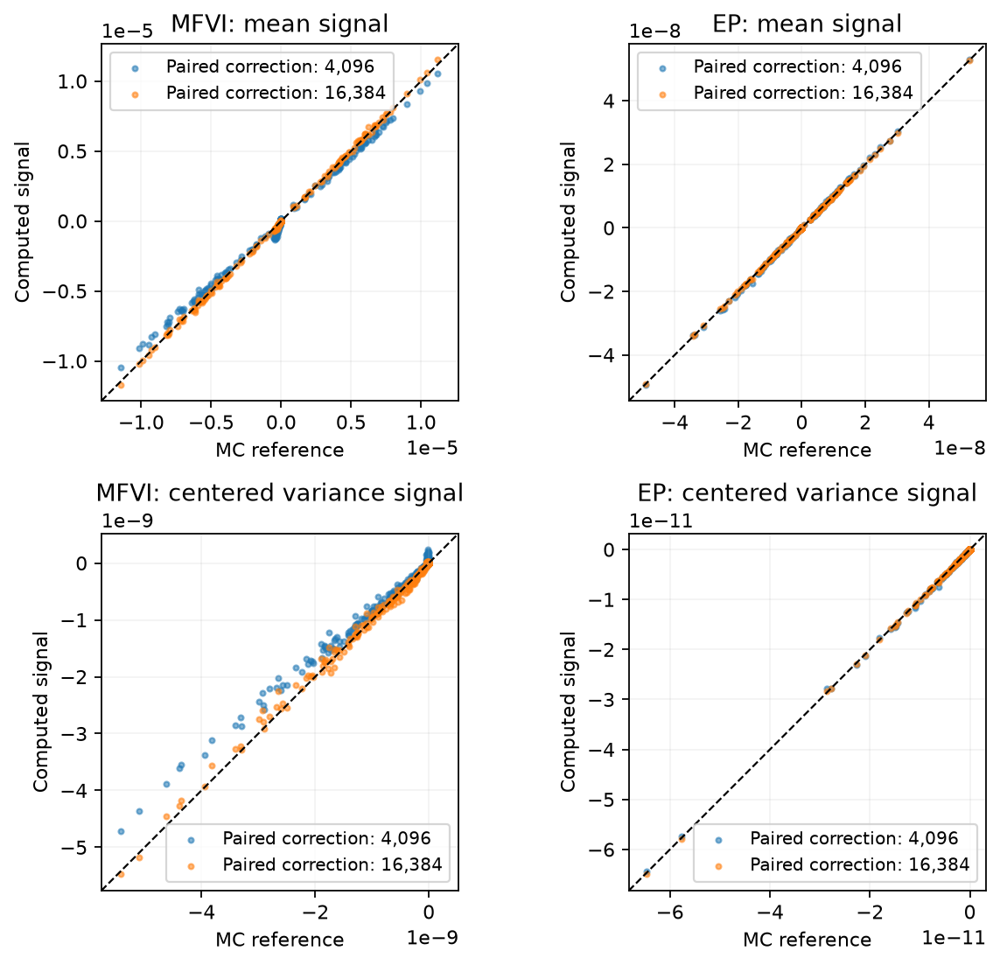

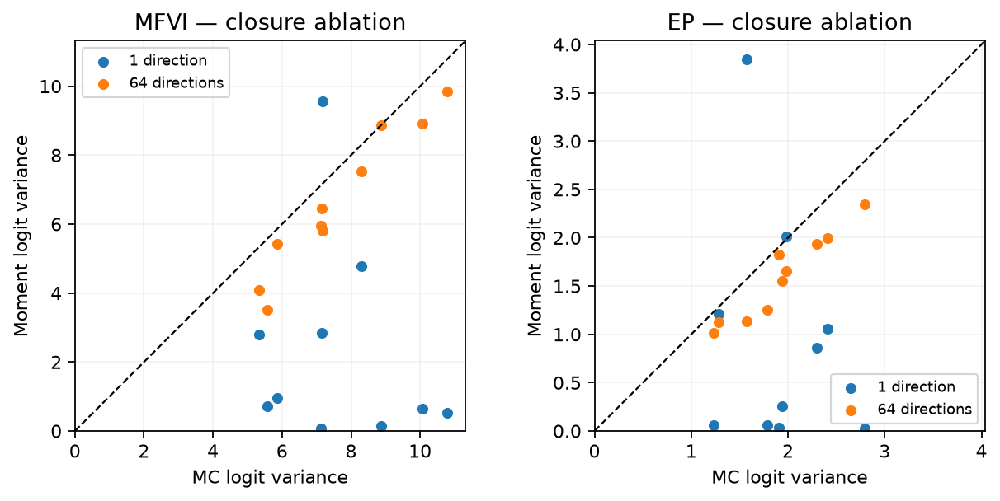

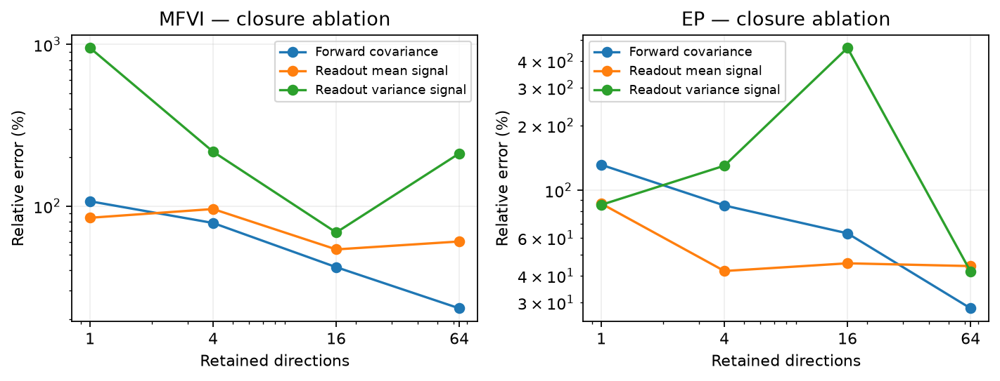

,Method,Network draws,output_mean relative MCSE,output_variance relative MCSE,mean_signal relative MCSE,centered_signal relative MCSE
0,MFVI,524288,0.00014,0.00253,0.00877,0.00751
1,EP,524288,0.00011,0.00257,0.02305,0.01394


,method,networks,mean_error,variance_error,total_seconds
0,mfvi,256,0.13244,0.14882,2.00810
1,mfvi,1024,0.12002,0.16986,2.35802
2,mfvi,4096,0.10107,0.17170,3.75261
3,mfvi,16384,0.02792,0.05849,9.33832
4,mfvi,65536,0.01455,0.02921,31.80272
5,ep,256,0.06761,0.07131,0.30062
6,ep,1024,0.09109,0.07765,0.65233
7,ep,4096,0.02733,0.02086,2.06094
8,ep,16384,0.00978,0.00966,7.69467
9,ep,65536,0.01288,0.00695,30.14999


In [44]:
#@title Python / PyTorch (expand to inspect)
import runpy
_comparison_root = _repo / "site" if (_repo / "site/compare_approximations.py").exists() else _repo / "evidence/matched"
matched = runpy.run_path(str(_comparison_root / "compare_approximations.py"))
error_rows = matched["compare"]()
matched["figures"](error_rows)
for name in ("readout_agreement", "forward_agreement", "covariance_and_message_error"):
    display(Image(filename=str(_comparison_root / "evidence" / (name+".png"))))
reference_rows=[]
for method in ("mfvi","ep"):
    receipt=json.loads((_comparison_root / "evidence" / (method+"_reference.json")).read_text())
    reference_rows.append({"Method":method.upper(),"Network draws":receipt["networks"],
        **{k+" relative MCSE":v for k,v in receipt["MC_relative_standard_error"].items()}})
display(pd.DataFrame(reference_rows).round(5))
cost=pd.DataFrame(json.loads((_comparison_root/"evidence"/"readout_correction_cost.json").read_text()))
display(cost[["method","networks","mean_error","variance_error","total_seconds"]].round(5))


### Accuracy and measured work

| Readout calculation | MFVI mean / variance error ↓ | EP mean / variance error ↓ |
|---|---:|---:|
| Uncorrected 64-direction closure (ablation) | 60.30% / 211.49% | 44.37% / 41.83% |
| Paired correction: 4,096 evaluations | 10.1% / 17.2% | 2.73% / 2.09% |
| Paired correction: 16,384 evaluations | 2.79% / 5.85% | 0.98% / 0.97% |
| Paired correction: 65,536 evaluations | 1.45% / 2.92% | 1.29% / 0.70% |

The correction substantially improves readout agreement for both objectives.
Errors near the reference's MC standard error should not be ranked: the last
two EP rows do not establish that fewer evaluations are intrinsically better.

| Correction evaluations | MFVI seconds ↓ | EP seconds ↓ |
|---:|---:|---:|
| 4,096 | 3.75 | 2.06 |
| 16,384 | 9.34 | 7.69 |
| 65,536 | 31.80 | 30.15 |

These saved L4 timings include Jacobian/surrogate preparation and readout
correction. MFVI ran first and paid more setup overhead. They measure one-input
diagnostics, not training or serving. The correction uses float64 and returns
readout derivatives; the original reverse pass returns all weight derivatives.
They therefore do not establish a 2–3× training-cost claim. No benchmark below
has been retrained or credited with this correction.

**Why the closure remains an ablation.** With 64 directions, forward covariance
errors are still 23.3% (MFVI) and 28.2% (EP). Refining only the Gaussian head from
18 nodes to 262,144 Sobol nodes changes mean/variance errors to 49.2%/38.8% and
42.7%/31.6%. Thus neither adding directions nor integrating that approximate
head more accurately removes the missing nonlinear response. The paired residual
directly measures this missing contribution. It is the supported refinement for
this example; its budget and variance accuracy must be measured, not assumed.


## Readout variance messages: conditioning before approximation

For an independent Gaussian readout, condition on its hidden input $h$ and
write $z_j=\sum_i W_{ji}h_i+b_j$. The hidden distribution need not be Gaussian.
For a smooth scalar likelihood function $F$, Gaussian integration by parts gives
$\partial_m E[F]=E[\partial_wF]$ and
$\partial_v E[F]=\tfrac12 E[\partial_w^2F]$. Indeed,
$\partial_mq=-\partial_wq$ and $\partial_vq=\tfrac12\partial_w^2q$;
integrating once or twice moves derivatives from the Gaussian density onto
$F$, with vanishing boundary terms. Applying the affine chain rule conditional
on $h$, then averaging over the independent upstream weights, proves
$$\partial_{m_{ji}}E[F]=E[h_i\partial_{z_j}F],\qquad
\partial_{v_{ji}}E[F]=\tfrac12E[h_i^2\partial_{z_j}^2F].$$
Let $p=\operatorname{softmax}(z)$, $r_j=1_{j=y}-p_j$, and
$H_{jj}=-p_j(1-p_j)$. For MFVI, $F=\log p_y$ has derivatives
$r_j,H_{jj}$. For EP, $F=p_y$ has derivatives
$p_y r_j,p_y(H_{jj}+r_j^2)$. Average the EP derivatives and $p_y$ separately,
then divide by $Z=E[p_y]$. Averaging log-probability derivatives instead would
change the objective to MFVI. Encode the resulting adjoints as
$d_m=v\odot g_m$ and $d_s-2m\odot d_m=2v^2\odot g_v$.

This readout identity avoids the often noisy pathwise variance estimator
$E[(\partial_wF)\epsilon/(2\sqrt v)]$. Both estimate the same derivative
under their regularity assumptions; their finite-sample variances differ.
The independent affine readout assumption is essential: correlated upstream
and readout weights need their joint conditional calculation.

The paired residual identity can be applied to these derivatives too:
$E_q[A]=E_q[A_0]+E_r[(q/r)(A-A_0)]$, where $A_0$ is a frozen surrogate
and the two paths use the same perturbation. EP corrects its normalizer and
unnormalized derivatives before division. A finite-sample EP ratio remains
biased; agreement with this identity does not prove exact finite-sample EP.
This is an integration refinement within a single Gaussian belief, not a
new optimizer or a mixture posterior. Forward covariance retention and
nonlinear head integration should be assessed separately.

**Follow the implementation:**

`src/bayesify_torch/heads.py`: `sampled_readout_adjoint`; independent Hessian/quadrature tests in `tests/test_readout_price.py`


## Conditional readout: implementation


**Readout derivatives: conditional Gaussian identity**

```python
def sampled_readout_adjoint(features, logits, label, method="mfvi"):
    """Per-network derivatives for an independent Gaussian affine readout.

    Condition on h. For z=Wh+b, Price's identity gives
    d_m E[f]=E[h df/dz], d_v E[f]=E[h² d²f/dz²]/2.
    log p_y has r=e_y-p, diag(H)=-p(1-p); p_y has Hessian
    p_y(H+rrᵀ). EP must average these unnormalized derivatives and p_y
    before dividing. Shapes: h[S,I], z[S,O], gm/gv[S,O,I].
    The hidden activations need not be Gaussian.
    """
    logp=logits.log_softmax(-1);p=logp.exp()
    r=torch.nn.functional.one_hot(torch.as_tensor(label,device=p.device),p.shape[-1]).to(p.dtype)-p
    H=-p*(1-p)
    if method=="mfvi":value=logp[:,label];a=torch.ones_like(value)
    elif method=="ep":value=p[:,label];a=value;H=H+r.square()
    else:raise ValueError("use mfvi or ep")
    h=features[:,None,:];a=a[:,None,None]
    return value,a*r[:,:,None]*h,.5*a*H[:,:,None]*h.square()
```


# 4. MNIST: MLP and LeNet with common uncertainty diagnostics

The MLP is 784-400-400-10. LeNet uses two 5x5 convolution/max-pooling blocks
and three dense layers. Deterministic pooling is ordinary max pooling;
moment pooling uses the Gaussian-pair approximation derived below.
Point, sampled MFVI/EP and moment MFVI/EP in the compact implementation all
share the same Gaussian parameter modules. The prediction is
$\bar p(y|x)=E_q[p(y|x,W)]$: probabilities are averaged before NLL.


### Max pooling: explicit projection and explicit reverse messages

For independent $A\sim N(m_a,v_a)$ and $B\sim N(m_b,v_b)$, put
$s^2=v_a+v_b$, $t=(m_a-m_b)/s$, $P=\Phi(t)$, $p=\phi(t)$.
Splitting the expectation on $A>B$ and integrating the Gaussian difference gives
$E[\max(A,B)]=m_aP+m_b(1-P)+sp$ and
$E[\max(A,B)^2]=(v_a+m_a^2)P+(v_b+m_b^2)(1-P)+(m_a+m_b)sp$.
Subtract the squared mean to obtain the variance. Differentiating the mean
gives $\partial_{m_a}m=P$, $\partial_{m_b}m=1-P$ and
$\partial_{v_a}m=\partial_{v_b}m=p/(2s)$.
The raw-second derivatives in `_max_pair_adjoint` complete the literal reverse
calculation; the projected path independently differentiates the forward map.

A 2×2 pool applies this pair operation twice. Its intermediate maximum is
projected back to a Gaussian, so the four-way result is an approximation even
for independent Gaussian inputs. For zero input variance the layer returns
the exact deterministic maximum. Neither a hidden epsilon variance nor a
silent replacement by average pooling is used.


In [51]:
from bayesify_torch.layers import *

def gaussian_max_pair(a: DiagonalMoments, b: DiagonalMoments) -> DiagonalMoments:
    """Exact two moments of max(A,B) for independent scalar Gaussians.

    s²=v_a+v_b, t=(m_a-m_b)/s, P=Phi(t), p=phi(t):
      mean = m_a P + m_b (1-P) + s p
      second = (v_a+m_a²)P + (v_b+m_b²)(1-P) + (m_a+m_b)s p.
    Pairwise repetition is a Gaussian *projection*, not an exact four-way max.
    At zero variance use the deterministic maximum, without dividing by zero.
    """
    positive = a.variance + b.variance > 0
    s = torch.where(positive, a.variance + b.variance, torch.ones_like(a.mean)).sqrt()
    t = (a.mean-b.mean)/s
    P = .5*torch.erfc(-t/math.sqrt(2))
    p = torch.exp(-.5*t.square())/math.sqrt(2*math.pi)
    m = a.mean*P+b.mean*(1-P)+s*p
    second = (a.variance+a.mean.square())*P+(b.variance+b.mean.square())*(1-P)+(a.mean+b.mean)*s*p
    take_a = a.mean >= b.mean
    return DiagonalMoments(torch.where(positive, m, torch.maximum(a.mean,b.mean)),
        torch.where(positive, (second-m.square()).clamp_min(0), torch.where(take_a,a.variance,b.variance)))

def _max_pair_adjoint(a, b, adjoint):
    """Hand derivatives of the pair's mean/raw second, then chain v=s2-m²."""
    positive = a.variance+b.variance > 0
    s = torch.where(positive,a.variance+b.variance,torch.ones_like(a.mean)).sqrt()
    t = (a.mean-b.mean)/s
    P = .5*torch.erfc(-t/math.sqrt(2))
    p = torch.exp(-.5*t.square())/math.sqrt(2*math.pi)
    m = a.mean*P+b.mean*(1-P)+s*p
    second = (a.variance+a.mean.square())*P+(b.variance+b.mean.square())*(1-P)+(a.mean+b.mean)*s*p
    gv = adjoint.variance*(second-m.square() >= 0)
    gm = adjoint.mean-2*m*gv
    common = p*((a.mean+b.mean)/(2*s)-(a.mean-b.mean)*(a.variance-b.variance)/(2*s**3))
    ga = EuclideanAdjoint(gm*P+gv*(2*a.mean*P+2*a.variance*p/s),
                         gm*p/(2*s)+gv*(P+common))
    gb = EuclideanAdjoint(gm*(1-P)+gv*(2*b.mean*(1-P)+2*b.variance*p/s),
                         gm*p/(2*s)+gv*(1-P+common))
    take = a.mean >= b.mean
    return tuple(EuclideanAdjoint(torch.where(positive,g.mean,adjoint.mean*mean_mask),
                                 torch.where(positive,g.variance,adjoint.variance*mask))
                 for g,mask,mean_mask in ((ga,take,(a.mean>b.mean)+.5*(a.mean==b.mean)),
                                         (gb,~take,(b.mean>a.mean)+.5*(a.mean==b.mean))))

def max_pool_moments(x: DiagonalMoments) -> DiagonalMoments:
    """2x2 stride-2 max pool, with two declared pairwise Gaussian projections."""
    states = [DiagonalMoments(x.mean[...,i::2,j::2],x.variance[...,i::2,j::2])
              for i,j in ((0,0),(0,1),(1,0),(1,1))]
    return gaussian_max_pair(gaussian_max_pair(*states[:2]), gaussian_max_pair(*states[2:]))

def max_pool_literal_backward(x, child):
    states = [DiagonalMoments(x.mean[...,i::2,j::2],x.variance[...,i::2,j::2])
              for i,j in ((0,0),(0,1),(1,0),(1,1))]
    left, right = gaussian_max_pair(*states[:2]),gaussian_max_pair(*states[2:])
    root = gaussian_max_pair(left,right)
    gl, gr = _max_pair_adjoint(left,right,decode_diagonal(root,child))
    derivatives = _max_pair_adjoint(*states[:2],gl)+_max_pair_adjoint(*states[2:],gr)
    gm,gv = torch.zeros_like(x.mean),torch.zeros_like(x.variance)
    for g,(i,j) in zip(derivatives,((0,0),(0,1),(1,0),(1,1))):
        gm[...,i::2,j::2],gv[...,i::2,j::2] = g.mean,g.variance
    return (encode_diagonal(x,EuclideanAdjoint(gm,gv)),)

class MomentMaxPool2d(nn.Module):
    """Ordinary max pooling and a Gaussian-pair moment approximation."""
    def forward(self,x): return F.max_pool2d(x,2)
    def forward_moments(self,x):
        if x.mean.shape[-1]%2 or x.mean.shape[-2]%2:
            raise ValueError("the pairwise teaching pool requires even spatial dimensions")
        return max_pool_moments(x)
    def project(self,x):
        out,backward = _projected_local(self.forward_moments,(x,))
        return LocalRecord(out,lambda child: LayerMessages(backward(child),{}))
    def literal(self,x):
        return LocalRecord(self.forward_moments(x),lambda child: LayerMessages(max_pool_literal_backward(x,child),{}))


In [52]:
from bayesify_torch.models import *

class TinyResidualMLP(nn.Module):
    """A non-sequential graph used to test shared-parent message accumulation."""

    def __init__(self, inputs: int = 4, hidden: int = 6, outputs: int = 3):
        super().__init__()
        # ``graph`` is reserved by torch.fx.GraphModule; use a normal module
        # name so the deterministic architecture remains symbolically traceable.
        self.network = MomentDAG(
            [
                ("input_projection", MomentLinear(inputs, hidden), ("input",)),
                ("activation", MomentReLU(), ("input_projection",)),
                ("residual_projection", MomentLinear(hidden, hidden), ("activation",)),
                ("residual_add", MomentAdd(), ("activation", "residual_projection")),
                ("readout", MomentLinear(hidden, outputs), ("residual_add",)),
            ]
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.network(x)

    def forward_moments(self, x: DiagonalMoments, *, literal: bool = False) -> GraphPass:
        return self.network.forward_moments(x, literal=literal)

class MomentMLP(nn.Module):
    """784-400-400-10 MNIST MLP built from the shared moment modules."""

    def __init__(self, inputs: int = 784, hidden: int = 400, classes: int = 10):
        super().__init__()
        self.network = MomentDAG(
            [
                ("flatten", MomentFlatten(), ("input",)),
                ("dense1", MomentLinear(inputs, hidden), ("flatten",)),
                ("relu1", MomentReLU(), ("dense1",)),
                ("dense2", MomentLinear(hidden, hidden), ("relu1",)),
                ("relu2", MomentReLU(), ("dense2",)),
                ("readout", MomentLinear(hidden, classes), ("relu2",)),
            ]
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.network(x.flatten(1))

    def forward_moments(self, x: DiagonalMoments, *, literal: bool = False) -> GraphPass:
        flattened = DiagonalMoments(x.mean.flatten(1), x.variance.flatten(1))
        return self.network.forward_moments(flattened, literal=literal)

class MomentLeNet(nn.Module):
    """61,706-parameter Conv2d/max-pool LeNet; Gaussian-pair moment pooling."""

    def __init__(self, classes: int = 10):
        super().__init__()
        self.network = MomentDAG(
            [
                ("conv1", MomentConv2d(1, 6, 5, padding=2), ("input",)),
                # max(ReLU(x)) = ReLU(max(x)) for point values. Gaussian
                # projections do NOT commute: match R/JAX's pool-then-ReLU
                # closure, rather than silently defining another approximation.
                ("pool1", MomentMaxPool2d(), ("conv1",)),
                ("relu1", MomentReLU(), ("pool1",)),
                ("conv2", MomentConv2d(6, 16, 5), ("relu1",)),
                ("pool2", MomentMaxPool2d(), ("conv2",)),
                ("relu2", MomentReLU(), ("pool2",)),
                ("flatten", MomentFlatten(), ("relu2",)),
                ("dense1", MomentLinear(16 * 5 * 5, 120), ("flatten",)),
                ("relu3", MomentReLU(), ("dense1",)),
                ("dense2", MomentLinear(120, 84), ("relu3",)),
                ("relu4", MomentReLU(), ("dense2",)),
                ("readout", MomentLinear(84, classes), ("relu4",)),
            ]
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.network(x)

    def forward_moments(self, x: DiagonalMoments, *, literal: bool = False) -> GraphPass:
        return self.network.forward_moments(x, literal=literal)


### Full readout covariance and a diagonal-plus-factor hidden state

The compact teaching head uses diagonal Gaussian logits. The following is
the richer head derived in the R tutorial and used by the archived image
implementations. Its derivation is included separately from that simpler
executable head; equal names do not establish full-training parity.

For ten classes the full **10×10 logit covariance** is
$C_z=M\operatorname{Diag}(v)M^\top+\operatorname{Diag}(V(m^{\odot2}+v)+v_b)$.
This follows directly from total covariance, conditioning first on the hidden
activation. Independent readout weights contribute the diagonal term;
uncertain hidden activations contribute correlations between classes.

In the second hidden layer, define
$D=\operatorname{Diag}(\Phi(m_{z_2}/\sqrt{v_{z_2}}))$ and $Q^\top Q=I_4$,
let $L=DM_2\operatorname{Diag}(\sqrt{v_1})Q$. Use
$C_{h_2}=\operatorname{Diag}(v_2-\operatorname{diag}(LL^\top))$
$+LL^\top$.
The retained part is positive semidefinite and the diagonal is unchanged.
Under the Gaussian ReLU closure, the residual is nonnegative: the first
Hermite component contributes at most the total activation variance, and an
orthogonal projection cannot increase its squared row norm. Explicitly,
Gaussian integration gives $\operatorname{Cov}(Z,Z_+)=v\Phi(m/\sqrt v)$;
Cauchy–Schwarz then implies
$\operatorname{Var}(Z_+)\ge v\Phi(m/\sqrt v)^2$.
Together with $QQ^\top\preceq I$ and the nonnegative weight-variance
contribution to $v_{z_2}$, this bounds each retained row norm by $v_2$.
Hold the basis fixed within each reverse pass. For the once-per-epoch refresh
used in the R example, include the refresh in training time. Backpropagation
includes the covariance correction's dependence on both layer means and
activation variances; it does not differentiate through the basis refresh.



### Contrast-space probability integration

The reported probability is $\bar p(y\mid x)=E_q[p(y\mid x,W)]$.
NLL is $-\log\bar p(y\mid x)$, not an average of sampled losses. Moment
serving factors the covariance of nine logit contrasts and averages softmax
probabilities over 18 symmetric Gaussian cubature nodes. Those are small
head calculations, **not 18 sampled networks**. Explicitly, let
$D=[I_9,-\mathbf 1]$, $a=Dm_z$ and $LL^\top=DC_zD^\top$.
The nodes $a\pm3Le_j$, each with weight $1/18$, have mean $a$ and covariance
$LL^\top$: the signed terms cancel and
$\sum_{j,\pm}(\pm3Le_j)(\pm3Le_j)^\top/18=LL^\top$.
Append a zero tenth logit before softmax; removing a common logit offset leaves
probabilities unchanged. Matching these first two Gaussian moments does not
make integration of nonlinear softmax exact. Sampled serving instead averages
$S$ complete-network probability vectors; each benchmark records $S$.
Both use the same ten classes.

One moment pass performs three affine products in an ordinary hidden layer:
one for the mean, and two for its variance. It also evaluates the nonlinear
moment formulas and the small covariance-aware head. This explains the
additional arithmetic relative to a point forward pass; the reported clocks
measure its actual implementation rather than inferring a speedup from the
number of network passes.


## Complete minibatch semantics

The sampled path returns $E[g]$ and $E[g^2]$ from complete network draws. The
moment MFVI path uses one curvature direction
$E[g(W)^2]\approx E[g(W)]^2+(H\sqrt v\epsilon)^2$. Tied power EP constructs
$\eta_c=(1-\alpha/N)\eta_q+(\alpha/N)\eta_0$ and differentiates both the
tilted term and the Gaussian external field back to the persistent posterior.


### What the optimizer adds—and what it does not

The mathematical EP/MFVI messages above are independent of Adam or Vadam.
For large-scale experiments we must additionally specify a finite update.
Vadam retains moving averages of the likelihood gradient and its squared
value, uses the second statistic to normalize mean steps, and ties posterior
precision to its optimizer state. $E[g^2]$ is not $(E[g])^2$ and is not the
VI derivative with respect to variance. The moment implementation approximates
it with a linearized gradient: if $g(W)\simeq g(m)+H(W-m)$, then
$E[g(W)^{\odot2}]\simeq g(m)^{\odot2}+\operatorname{diag}(HC H^\top)$.
A shared random direction estimates the last diagonal; the optimizer's time
average remains a separate operation. This is an optimizer approximation,
not the exact Gaussian message-passing theorem.

For MFVI, an unbiased minibatch likelihood **sum** is
$(N/B)\sum_{n\in\mathcal B}E_q\log p(y_n\mid x_n,W)$; the KL is counted
once. An equivalent average objective divides both likelihood and KL by $N$.
Temperature changes that objective and must be reported.

### Tied power EP and the external field

The scalable EP-style training path has a tied Gaussian cavity, rather than
storing one full weight-space site per example. Put $k=\alpha/N$ and
$q_c=q^{1-k}p_0^k/A$. The declared energy is

$$\mathcal F=-\frac{\tau}{\alpha}
\left[\frac1N\sum_n\log E_{q_c}
p(y_n\mid x_n,W)^{\alpha/\tau}+\log A\right].$$

For one diagonal coordinate, let $r=v/v_0$ and $d=1+k(r-1)$.
Completing the Gaussian square gives
$v_c=v/d$, $m_c=m_0+(1-k)(m-m_0)/d$, and
$-\log A=\tfrac12[\log d-k\log r+k(1-k)(m-m_0)^2/(v_0d)]$.
Sum this last expression over coordinates. The external field is part of
the scalar objective every minibatch; it is not diluted by the number of
epochs. Differentiating must include the cavity and field dependence on $q$.

Expanding $\log E_q\exp[(\alpha/\tau)\log p]$ to first order in $\alpha$
and using $\log A=-(\alpha/N)\mathrm{KL}(q\|p_0)+O(\alpha^2)$ gives
$\mathcal F\to-\frac1N\sum_n E_q\log p_n
+\frac\tau N\mathrm{KL}(q\|p_0)$.
This connects the tied energy to VI in its small-power limit. Adam on the
mean and log variance optimizes this energy; it is **not** a literal EP site
replacement. The exact site algorithm and this scalable surrogate are named
separately throughout.


**Match the notation to the executable controls.** The code calls the likelihood
power $\alpha/\tau$ `power`, and calls $\tau$ `tau`; it passes
`alpha = tau * power` into `power_cavity`. The reproduced EP configurations use
`power = 1`, so their head averages ordinary class probabilities while the
cavity removal fraction is $\tau/N$. Varying `tau` with `power` fixed is therefore
not the $\alpha\downarrow0$ limit at fixed $\tau$ just proved. This distinction
prevents a regularization sweep from being mislabelled an EP-to-VI limit.


### Complete finite-update recurrences and their state

For the reference Vadam recurrence write $N_{\rm eff}=N/\tau$, prior precision
$p_i=1/v_{0i}$ and $\lambda_i=p_i/N_{\rm eff}$. With likelihood-gradient
moments $a_i=E[g_i]$ and $b_i=E[g_i^2]$, its temporal state updates are
\[
r_i^+=\beta_1r_i+(1-\beta_1)[a_i+\lambda_i(m_i-m_{0i})],\qquad
s_i^+=\beta_2s_i+(1-\beta_2)b_i.
\]
Then $m_i^+=m_i-\eta\widehat r_i/(\sqrt{\widehat s_i}+\lambda_i)$ and
$v_i^+=1/(N_{\rm eff}s_i^++p_i)$, where hats denote the reference's bias
correction. Its initial $s_i=(v_i^{-1}-p_i)/N_{\rm eff}$ preserves the declared
initial belief variance. This initialization is part of the reproduced
algorithm, not a zero-state Adam replacement.

For sampled MFVI, average $g_i$ and $g_i^2$ separately across complete network
draws. For moment MFVI, the reference uses
$b_i\approx a_i^2+(H\sqrt{\operatorname{Diag}v}\,e)_i^2$ with one fixed
Rademacher direction and the point-loss Hessian $H$. To derive the contraction,
linearize $g(w)\approx g(m)+H(w-m)$; independence and $E[ee^\top]=I$ give
$E_e[(H\sqrt{\operatorname{Diag}v}\,e)_i^2]=(H\operatorname{Diag}(v)H^\top)_{ii}$.
A single fixed direction is an approximation to that expectation, not an exact
second moment. This statistic differs from the VI variance derivative and needs
its own validation. The EP optimizer instead consumes the differentiated
cavity likelihood and external field in $(m,\log v)$; it does not replace
posterior variance by Adam's squared-gradient accumulator.

The text reproductions also retain the reference's separate, zero-initialized
likelihood normalization state $u_i^+=\beta_2u_i+(1-\beta_2)b_i$.
When that recorded option is active, the mean denominator uses
$\sqrt{\widehat u_i}+\lambda_i$, while the posterior variance still uses
$1/(N_{\rm eff}s_i+p_i)$. The initial prior-compatible $s_i$ and the temporal
normalizer $u_i$ have different roles. The code records this choice in
`configure_text_belief`; silently identifying these two states changes the
training trajectory even when the sampled gradients are identical.
The compact `Vadam` class shown here implements the first, single-$s$ state
recurrence. The separate-$u$ text variant is described to preserve the original
algorithm distinction, not asserted to be a flag in that compact class.
The archived image curvature refresh frequency is a measured implementation
choice: one fixed direction, refreshed every four MLP or two LeNet updates,
while mean gradients and EMAs update every minibatch. It is not a theorem that
such stale curvature equals a fresh sampled gradient second moment.

For EP-Adam let $a=\log v$. The ordinary chain rule gives
$g_a=v\odot g_v$. Adam maintains separate first and second temporal
accumulators for $g_m$ and $g_a$ and subtracts their bias-corrected, normalized
steps. These accumulators neither replace the belief variance nor perform EP
site removal. The cavity/field objective supplies EP semantics before Adam.


**Key code: power cavity and optimizer steps (optimizers.py)**

```python
def power_cavity(
    parameters: Mapping[str, GaussianParameter], observations: int, alpha: float
) -> PowerCavity:
    """Remove an ``alpha/N`` share of the posterior and restore the prior.

    In information coordinates, with ``k=alpha/N``,

    ``eta_cavity = (1-k) eta_q + k eta_prior``.

    The returned ``log_field`` is the corresponding Gaussian normalizer term;
    it is applied once globally, not once per minibatch example.
    """
    if observations <= 0 or not 0 <= alpha <= observations:
        raise ValueError("require observations>0 and 0<=alpha<=observations")
    k = alpha / observations
    beliefs: dict[str, DiagonalMoments] = {}
    first = next(iter(parameters.values())).mean
    log_field = first.new_zeros(())
    for name, parameter in parameters.items():
        q, prior = parameter.moments(), parameter.prior()
        e = k * (q.variance / prior.variance - 1)
        denominator = 1 + e
        if torch.any(denominator <= 0):
            raise ValueError(f"invalid cavity precision for {name}")
        variance = q.variance / denominator
        mean = prior.mean + (1 - k) * (q.mean - prior.mean) / denominator
        beliefs[name] = DiagonalMoments(mean, variance)
        log_field = log_field - 0.5 * torch.sum(
            torch.log1p(e)
            - k * torch.log(q.variance / prior.variance)
            + k
            * (1 - k)
            * (q.mean - prior.mean).square()
            / (prior.variance * denominator)
        )
    return PowerCavity(beliefs, log_field)

@torch.no_grad()
def step(self, gradient: Sequence[Tensor], gradient_second: Sequence[Tensor]) -> None:
    if not (len(gradient) == len(gradient_second) == len(self.parameters)):
        raise ValueError("one first and second gradient moment is required per parameter")
    self.steps += 1
    beta1, beta2 = self.betas
    for parameter, g, g2, first, second in zip(
        self.parameters, gradient, gradient_second, self.first, self.second
    ):
        regularization = 1 / (self.effective_n * parameter.prior_variance)
        first.mul_(beta1).add_((1 - beta1) * (g + regularization * (parameter.mean - parameter.prior_mean)))
        second.mul_(beta2).add_((1 - beta2) * g2)
        first_hat = first / (1 - beta1**self.steps)
        second_hat = second / (1 - beta2**self.steps)
        parameter.mean.add_(
            -self.learning_rate * first_hat / (second_hat.sqrt() + regularization)
        )
        variance = 1 / (self.effective_n * second + 1 / parameter.prior_variance)
        if torch.any(variance <= 0):
            raise ValueError("Vadam produced an invalid posterior variance")
        parameter.log_variance.copy_(variance.log())

@torch.no_grad()
def step(self, mean_gradient: Sequence[Tensor], variance_gradient: Sequence[Tensor]) -> None:
    if not (len(mean_gradient) == len(variance_gradient) == len(self.parameters)):
        raise ValueError("one mean and variance gradient is required per parameter")
    self.steps += 1
    beta1, beta2 = self.betas
    for p, gm, gv, rm, sm, rv, sv in zip(
        self.parameters,
        mean_gradient,
        variance_gradient,
        self.mean_first,
        self.mean_second,
        self.var_first,
        self.var_second,
    ):
        ga = p.variance * gv
        rm.mul_(beta1).add_((1 - beta1) * gm)
        sm.mul_(beta2).add_((1 - beta2) * gm.square())
        rv.mul_(beta1).add_((1 - beta1) * ga)
        sv.mul_(beta2).add_((1 - beta2) * ga.square())
        rmh, smh = rm / (1 - beta1**self.steps), sm / (1 - beta2**self.steps)
        rvh, svh = rv / (1 - beta1**self.steps), sv / (1 - beta2**self.steps)
        p.mean.add_(-self.learning_rate * rmh / (smh.sqrt() + self.epsilon))
        p.log_variance.add_(
            -self.variance_learning_rate * rvh / (svh.sqrt() + self.epsilon)
        )
```


In [59]:
#@title Support: complete optimizer classes (expand to inspect)
from bayesify_torch.optimizers import *

def power_cavity(
    parameters: Mapping[str, GaussianParameter], observations: int, alpha: float
) -> PowerCavity:
    """Remove an ``alpha/N`` share of the posterior and restore the prior.

    In information coordinates, with ``k=alpha/N``,

    ``eta_cavity = (1-k) eta_q + k eta_prior``.

    The returned ``log_field`` is the corresponding Gaussian normalizer term;
    it is applied once globally, not once per minibatch example.
    """
    if observations <= 0 or not 0 <= alpha <= observations:
        raise ValueError("require observations>0 and 0<=alpha<=observations")
    k = alpha / observations
    beliefs: dict[str, DiagonalMoments] = {}
    first = next(iter(parameters.values())).mean
    log_field = first.new_zeros(())
    for name, parameter in parameters.items():
        q, prior = parameter.moments(), parameter.prior()
        e = k * (q.variance / prior.variance - 1)
        denominator = 1 + e
        if torch.any(denominator <= 0):
            raise ValueError(f"invalid cavity precision for {name}")
        variance = q.variance / denominator
        mean = prior.mean + (1 - k) * (q.mean - prior.mean) / denominator
        beliefs[name] = DiagonalMoments(mean, variance)
        log_field = log_field - 0.5 * torch.sum(
            torch.log1p(e)
            - k * torch.log(q.variance / prior.variance)
            + k
            * (1 - k)
            * (q.mean - prior.mean).square()
            / (prior.variance * denominator)
        )
    return PowerCavity(beliefs, log_field)

class Vadam:
    """Published diagonal Vadam recurrence, written without optimizer wrappers.

    Let ``N_eff=N/tau`` and ``lambda=1/(N_eff v0)``. For likelihood-gradient
    moments ``g=E[grad loss]`` and ``g2=E[(grad loss)^2]``:

    ``r <- b1 r + (1-b1) [g + lambda (m-m0)]``
    ``s <- b2 s + (1-b2) g2``
    ``m <- m - lr r_hat/(sqrt(s_hat)+lambda)``
    ``v <- 1/(N_eff s + 1/v0)``.
    """

    def __init__(
        self,
        parameters: Sequence[GaussianParameter],
        observations: int,
        temperature: float,
        learning_rate: float,
        betas: tuple[float, float] = (0.9, 0.99),
    ):
        if observations <= 0 or temperature <= 0:
            raise ValueError("observations and temperature must be positive")
        self.parameters = list(parameters)
        self.effective_n = observations / temperature
        self.learning_rate, self.betas, self.steps = learning_rate, betas, 0
        self.first = [torch.zeros_like(p.mean) for p in self.parameters]
        self.second = [
            (1 / p.variance.detach() - 1 / p.prior_variance) / self.effective_n
            for p in self.parameters
        ]

    @torch.no_grad()
    def step(self, gradient: Sequence[Tensor], gradient_second: Sequence[Tensor]) -> None:
        if not (len(gradient) == len(gradient_second) == len(self.parameters)):
            raise ValueError("one first and second gradient moment is required per parameter")
        self.steps += 1
        beta1, beta2 = self.betas
        for parameter, g, g2, first, second in zip(
            self.parameters, gradient, gradient_second, self.first, self.second
        ):
            regularization = 1 / (self.effective_n * parameter.prior_variance)
            first.mul_(beta1).add_((1 - beta1) * (g + regularization * (parameter.mean - parameter.prior_mean)))
            second.mul_(beta2).add_((1 - beta2) * g2)
            first_hat = first / (1 - beta1**self.steps)
            second_hat = second / (1 - beta2**self.steps)
            parameter.mean.add_(
                -self.learning_rate * first_hat / (second_hat.sqrt() + regularization)
            )
            variance = 1 / (self.effective_n * second + 1 / parameter.prior_variance)
            if torch.any(variance <= 0):
                raise ValueError("Vadam produced an invalid posterior variance")
            parameter.log_variance.copy_(variance.log())

class EPAdam:
    """Separate Adam recurrences for Gaussian means and log variances.

    If ``g_v=d loss/dv`` and ``a=log(v)``, the chain rule gives
    ``d loss/da = v*g_v``.  This quantity is distinct from Adam's second
    accumulator and from Vadam's ``E[g^2]``.
    """

    def __init__(
        self,
        parameters: Sequence[GaussianParameter],
        learning_rate: float,
        variance_learning_rate: float,
        betas: tuple[float, float] = (0.9, 0.999),
        epsilon: float = 1e-8,
    ):
        self.parameters = list(parameters)
        self.learning_rate, self.variance_learning_rate = learning_rate, variance_learning_rate
        self.betas, self.epsilon, self.steps = betas, epsilon, 0
        self.mean_first = [torch.zeros_like(p.mean) for p in self.parameters]
        self.mean_second = [torch.zeros_like(p.mean) for p in self.parameters]
        self.var_first = [torch.zeros_like(p.mean) for p in self.parameters]
        self.var_second = [torch.zeros_like(p.mean) for p in self.parameters]

    @torch.no_grad()
    def step(self, mean_gradient: Sequence[Tensor], variance_gradient: Sequence[Tensor]) -> None:
        if not (len(mean_gradient) == len(variance_gradient) == len(self.parameters)):
            raise ValueError("one mean and variance gradient is required per parameter")
        self.steps += 1
        beta1, beta2 = self.betas
        for p, gm, gv, rm, sm, rv, sv in zip(
            self.parameters,
            mean_gradient,
            variance_gradient,
            self.mean_first,
            self.mean_second,
            self.var_first,
            self.var_second,
        ):
            ga = p.variance * gv
            rm.mul_(beta1).add_((1 - beta1) * gm)
            sm.mul_(beta2).add_((1 - beta2) * gm.square())
            rv.mul_(beta1).add_((1 - beta1) * ga)
            sv.mul_(beta2).add_((1 - beta2) * ga.square())
            rmh, smh = rm / (1 - beta1**self.steps), sm / (1 - beta2**self.steps)
            rvh, svh = rv / (1 - beta1**self.steps), sv / (1 - beta2**self.steps)
            p.mean.add_(-self.learning_rate * rmh / (smh.sqrt() + self.epsilon))
            p.log_variance.add_(
                -self.variance_learning_rate * rvh / (svh.sqrt() + self.epsilon)
            )


**Key code: moment likelihood messages and Bayesian prediction (training.py)**

```python
def moment_likelihood_gradients(
    graph: MomentDAG,
    inputs: Tensor,
    labels: Tensor,
    method: str = "mfvi",
    power: float = 1.0,
    scale: float = 1.0,
    head: str = "quadrature",
    rank: int = 0,
    seed: int = 41,
    full_readout: bool = False,
) -> MomentGradients:
    """Forward moments -> method-specific head -> explicit reverse messages.

    The returned ordinary derivatives minimize the negative likelihood
    objective.  The unnegated moment signals remain available for canonical
    MFVI or finite EP updates.
    """
    if rank:
        if head != "quadrature":
            raise ValueError("the shared-covariance head uses contrast quadrature")
        value, weights, adjoints, signals, passed = shared_likelihood(
            graph,inputs,labels,rank,seed,method=method,power=power,scale=scale)
        return MomentGradients(value,{n:-g[0] for n,g in weights.items()},
            {n:-g[1] for n,g in weights.items()},FactorMessages(signals,adjoints),
            normalization_observations(graph,passed.states))
    observed = DiagonalMoments(inputs, torch.zeros_like(inputs))
    passed = graph.forward_moments(observed, literal=False, full_readout=full_readout)
    if full_readout:
        child,value=torch.func.grad_and_value(lambda m,r:root_objective(
            RootMoments(m,r),labels,method,power,scale),argnums=(0,1))(*passed.output)
        messages=passed.backward(child)
    elif head == "quadrature":
        result = categorical_quadrature_head(passed.output, labels, method, power, scale)
    elif head == "second_order" and method == "mfvi":
        result = mfvi_categorical_head(passed.output, labels, scale)
    else:
        raise ValueError("use quadrature for MFVI/EP, or second_order for MFVI")
    if not full_readout:
        value,messages=result.value,passed.backward(result.signal)
    parameters = dict(named_gaussian_parameters(graph))
    mean_gradient, variance_gradient = {}, {}
    for name, parameter in parameters.items():
        ordinary = decode_diagonal(parameter.moments(), messages.parameters[name])
        # Heads maximize log likelihood; optimizers in optimizers.py minimize.
        mean_gradient[name] = -ordinary.mean
        variance_gradient[name] = -ordinary.variance
    return MomentGradients(value, mean_gradient, variance_gradient, messages,
                           normalization_observations(graph, passed.states))

def sampled_predict(
    graph: MomentDAG,
    inputs: Tensor,
    samples: int = 32,
    generator: torch.Generator | None = None,
) -> Tensor:
    """Bayesian model average: average probabilities from complete networks."""
    parameters = dict(named_gaussian_parameters(graph))
    probability = 0
    for _ in range(samples):
        replacements = {}
        for name, parameter in parameters.items():
            epsilon = torch.randn(
                parameter.mean.shape,
                dtype=parameter.mean.dtype,
                device=parameter.mean.device,
                generator=generator,
            )
            replacements[f"layers.{name}.mean"] = parameter.mean + parameter.variance.sqrt() * epsilon
        probability = probability + functional_call(graph, replacements, (inputs,), strict=False).softmax(-1)
    return probability / samples

def moment_predict(graph: MomentDAG, inputs: Tensor, rank: int = 0, seed: int = 41, full_readout=False) -> Tensor:
    """Single-pass ``+/-sqrt(K)`` integration of the diagonal logit belief."""
    if rank:
        z = shared_forward(graph, inputs, rank, seed).output
        return root_nodes(z).softmax(-1).mean(0)
    z = graph.forward_moment_values(DiagonalMoments(inputs, torch.zeros_like(inputs)),full_readout=full_readout)
    if full_readout:return root_nodes(z).softmax(-1).mean(0)
    classes = z.mean.shape[-1]
    eye = torch.eye(classes, dtype=z.mean.dtype, device=z.mean.device)
    offset = math.sqrt(classes) * z.variance.sqrt().unsqueeze(0) * eye[:, None, :]
    nodes = torch.cat((z.mean.unsqueeze(0) + offset, z.mean.unsqueeze(0) - offset), 0)
    return nodes.softmax(-1).mean(0)
```


In [61]:
#@title Support: full sampled/moment training routines (expand to inspect)
from bayesify_torch.training import *

def moment_likelihood_gradients(
    graph: MomentDAG,
    inputs: Tensor,
    labels: Tensor,
    method: str = "mfvi",
    power: float = 1.0,
    scale: float = 1.0,
    head: str = "quadrature",
    rank: int = 0,
    seed: int = 41,
    full_readout: bool = False,
) -> MomentGradients:
    """Forward moments -> method-specific head -> explicit reverse messages.

    The returned ordinary derivatives minimize the negative likelihood
    objective.  The unnegated moment signals remain available for canonical
    MFVI or finite EP updates.
    """
    if rank:
        if head != "quadrature":
            raise ValueError("the shared-covariance head uses contrast quadrature")
        value, weights, adjoints, signals, passed = shared_likelihood(
            graph,inputs,labels,rank,seed,method=method,power=power,scale=scale)
        return MomentGradients(value,{n:-g[0] for n,g in weights.items()},
            {n:-g[1] for n,g in weights.items()},FactorMessages(signals,adjoints),
            normalization_observations(graph,passed.states))
    observed = DiagonalMoments(inputs, torch.zeros_like(inputs))
    passed = graph.forward_moments(observed, literal=False, full_readout=full_readout)
    if full_readout:
        child,value=torch.func.grad_and_value(lambda m,r:root_objective(
            RootMoments(m,r),labels,method,power,scale),argnums=(0,1))(*passed.output)
        messages=passed.backward(child)
    elif head == "quadrature":
        result = categorical_quadrature_head(passed.output, labels, method, power, scale)
    elif head == "second_order" and method == "mfvi":
        result = mfvi_categorical_head(passed.output, labels, scale)
    else:
        raise ValueError("use quadrature for MFVI/EP, or second_order for MFVI")
    if not full_readout:
        value,messages=result.value,passed.backward(result.signal)
    parameters = dict(named_gaussian_parameters(graph))
    mean_gradient, variance_gradient = {}, {}
    for name, parameter in parameters.items():
        ordinary = decode_diagonal(parameter.moments(), messages.parameters[name])
        # Heads maximize log likelihood; optimizers in optimizers.py minimize.
        mean_gradient[name] = -ordinary.mean
        variance_gradient[name] = -ordinary.variance
    return MomentGradients(value, mean_gradient, variance_gradient, messages,
                           normalization_observations(graph, passed.states))

def sampled_likelihood_gradients(
    graph: MomentDAG,
    inputs: Tensor,
    labels: Tensor,
    samples: int = 1,
    generator: torch.Generator | None = None,
) -> SampledGradients:
    """Reparameterized whole-network draws and Vadam gradient moments.

    One sampled parameter tensor is reused for the complete minibatch.  Drawing
    independent weights for examples would estimate a different model.
    """
    if samples <= 0:
        raise ValueError("samples must be positive")
    parameters = dict(named_gaussian_parameters(graph))
    accumulated = {name: torch.zeros_like(p.mean) for name, p in parameters.items()}
    second = {name: torch.zeros_like(p.mean) for name, p in parameters.items()}
    losses, statistics = [], []
    for _ in range(samples):
        draws, replacements = {}, {}
        for name, parameter in parameters.items():
            epsilon = torch.randn(
                parameter.mean.shape,
                dtype=parameter.mean.dtype,
                device=parameter.mean.device,
                generator=generator,
            )
            draw = (parameter.mean.detach() + parameter.variance.detach().sqrt() * epsilon).requires_grad_()
            draws[name] = draw
            replacements[f"layers.{name}.mean"] = draw
        states = functional_call(graph, replacements, (inputs,), {"return_states": True}, strict=False)
        logits = states[graph.nodes[-1].name]
        statistics.append(normalization_observations(graph, states))
        loss = F.cross_entropy(logits, labels)
        gradients = torch.autograd.grad(loss, tuple(draws.values()))
        losses.append(loss.detach())
        for (name, _), gradient in zip(draws.items(), gradients):
            accumulated[name].add_(gradient.detach() / samples)
            second[name].add_(gradient.detach().square() / samples)
    return SampledGradients(torch.stack(losses).mean(), accumulated, second,
                            average_observations(statistics))

def moment_ep_gradients(
    graph: MomentDAG,
    inputs: Tensor,
    labels: Tensor,
    observations: int,
    alpha: float,
    power: float = 1.0,
    scale: float = 1.0,
    rank: int = 0,
    seed: int = 41,
    full_readout: bool = False,
) -> EPGradients:
    """One tied power-EP moment calculation, including the external field.

    With ``k=alpha/N``, the cavity is

    ``eta_c = (1-k) eta_q + k eta_0``.

    Let ``logA`` be the Gaussian normalization correction returned by
    :func:`power_cavity`.  The minimized energy is

    ``L = -log Z_power(cavity) - logA/power``.

    The likelihood derivative is transported by explicit moment messages at
    the cavity.  ``torch.autograd.grad`` is used only for the analytic map from
    posterior coordinates to cavity coordinates and for the external field.
    The external field is applied once globally, preventing the prior from
    being diluted by the number of minibatches.
    """
    parameters = dict(named_gaussian_parameters(graph))
    cavity = power_cavity(parameters, observations, alpha)
    if rank:
        qs = {n: (q.mean,q.variance) for n,q in cavity.beliefs.items()}
        value, _, adjoints, signals, passed = shared_likelihood(
            graph,inputs,labels,rank,seed,qs,"ep",power,scale)
        messages = FactorMessages(signals,adjoints)
    else:
        wrapper = _MomentPass(graph, full_readout)
        passed = functional_call(
            wrapper, _cavity_replacements(cavity), (inputs,), strict=False
        )
        if full_readout:
            child,value=torch.func.grad_and_value(lambda m,r:root_objective(
                RootMoments(m,r),labels,'ep',power,scale),argnums=(0,1))(*passed.output)
            messages=passed.backward(child)
        else:
            head = categorical_quadrature_head(passed.output, labels, "ep", power, scale)
            value, messages = head.value, passed.backward(head.signal)

    cavity_mean, cavity_variance = [], []
    mean_adjoint, variance_adjoint = [], []
    for name, belief in cavity.beliefs.items():
        ordinary = decode_diagonal(belief, messages.parameters[name])
        cavity_mean.append(belief.mean)
        cavity_variance.append(belief.variance)
        mean_adjoint.append(ordinary.mean)
        variance_adjoint.append(ordinary.variance)

    posterior_coordinates = tuple(
        value for parameter in parameters.values() for value in (parameter.mean, parameter.log_variance)
    )
    objective_gradients = torch.autograd.grad(
        tuple(cavity_mean + cavity_variance + [cavity.log_field]),
        posterior_coordinates,
        grad_outputs=tuple(
            mean_adjoint
            + variance_adjoint
            + [cavity.log_field.new_tensor(1 / power)]
        ),
        allow_unused=False,
    )
    mean_gradient, variance_gradient = {}, {}
    for (name, parameter), gm, ga in zip(
        parameters.items(), objective_gradients[0::2], objective_gradients[1::2]
    ):
        # ``ga`` is d(max objective)/d log(v). EPAdam expects d(min loss)/dv.
        mean_gradient[name] = -gm
        variance_gradient[name] = -ga / parameter.variance
    loss = -value - cavity.log_field / power
    return EPGradients(loss, mean_gradient, variance_gradient, messages,
                       normalization_observations(graph, passed.states))

def sampled_ep_gradients(
    graph: MomentDAG,
    inputs: Tensor,
    labels: Tensor,
    observations: int,
    alpha: float,
    samples: int = 4,
    power: float = 1.0,
    generator: torch.Generator | None = None,
    scale: float = 1.0,
) -> EPGradients:
    """Reparameterized reference for the same tied power-EP energy.

    ``scale`` multiplies the likelihood sum only. Training uses ``1/B``;
    the one global external field must not be divided by the minibatch size.
    """
    if samples <= 0:
        raise ValueError("samples must be positive")
    parameters = dict(named_gaussian_parameters(graph))
    cavity = power_cavity(parameters, observations, alpha)
    likelihoods, statistics = [], []
    for _ in range(samples):
        replacements = {}
        for name, belief in cavity.beliefs.items():
            epsilon = torch.randn(
                belief.mean.shape,
                dtype=belief.mean.dtype,
                device=belief.mean.device,
                generator=generator,
            )
            replacements[f"layers.{name}.mean"] = belief.mean + belief.variance.sqrt() * epsilon
        states = functional_call(graph, replacements, (inputs,), {"return_states": True}, strict=False)
        logits = states[graph.nodes[-1].name]
        statistics.append(normalization_observations(graph, states))
        likelihoods.append(-F.cross_entropy(logits, labels, reduction="none"))
    log_likelihood = torch.stack(likelihoods)
    log_normalizer = (
        torch.logsumexp(power * log_likelihood, 0) - math.log(samples)
    ).sum() / power
    loss = -scale * log_normalizer - cavity.log_field / power
    coordinates = tuple(
        value for parameter in parameters.values() for value in (parameter.mean, parameter.log_variance)
    )
    derivatives = torch.autograd.grad(loss, coordinates)
    mean_gradient, variance_gradient = {}, {}
    for (name, parameter), gm, ga in zip(
        parameters.items(), derivatives[0::2], derivatives[1::2]
    ):
        mean_gradient[name] = gm.detach()
        variance_gradient[name] = (ga / parameter.variance).detach()
    return EPGradients(loss.detach(), mean_gradient, variance_gradient, None,
                       average_observations(statistics))

def moment_vadam_second(
    graph: MomentDAG,
    inputs: Tensor,
    labels: Tensor,
    mean_gradient: dict[str, Tensor],
    generator: torch.Generator | None = None,
) -> dict[str, Tensor]:
    """One-direction curvature statistic used by moment Vadam.

    If ``g(m)`` is the point-network minibatch gradient and
    ``d=sqrt(v) epsilon``, the local Gaussian approximation gives

    ``E[g(W)^2] approximately E[g(W)]^2 + (H(m)d)^2``.

    This is the deterministic counterpart of the sampled Vadam second moment;
    the optimizer's exponential accumulator remains a separate state.
    """
    parameters = dict(named_gaussian_parameters(graph))
    means = tuple(parameter.mean for parameter in parameters.values())
    directions = tuple(
        parameter.variance.sqrt()
        * (
            2
            * torch.randint(
                0,
                2,
                parameter.mean.shape,
                device=parameter.mean.device,
                generator=generator,
            ).to(parameter.mean.dtype)
            - 1
        )
        for parameter in parameters.values()
    )

    names = tuple(parameters)

    def point_loss(*candidate_means: Tensor) -> Tensor:
        replacements = {
            f"layers.{name}.mean": candidate for name, candidate in zip(names, candidate_means)
        }
        logits = functional_call(graph, replacements, (inputs,), strict=False)
        return F.cross_entropy(logits, labels)

    gradient_function = grad(point_loss, argnums=tuple(range(len(means))))
    _, hessian_direction = jvp(gradient_function, means, directions)
    return {
        name: mean_gradient[name].square() + hd.detach().square()
        for name, hd in zip(names, hessian_direction)
    }

def sampled_predict(
    graph: MomentDAG,
    inputs: Tensor,
    samples: int = 32,
    generator: torch.Generator | None = None,
) -> Tensor:
    """Bayesian model average: average probabilities from complete networks."""
    parameters = dict(named_gaussian_parameters(graph))
    probability = 0
    for _ in range(samples):
        replacements = {}
        for name, parameter in parameters.items():
            epsilon = torch.randn(
                parameter.mean.shape,
                dtype=parameter.mean.dtype,
                device=parameter.mean.device,
                generator=generator,
            )
            replacements[f"layers.{name}.mean"] = parameter.mean + parameter.variance.sqrt() * epsilon
        probability = probability + functional_call(graph, replacements, (inputs,), strict=False).softmax(-1)
    return probability / samples

def moment_predict(graph: MomentDAG, inputs: Tensor, rank: int = 0, seed: int = 41, full_readout=False) -> Tensor:
    """Single-pass ``+/-sqrt(K)`` integration of the diagonal logit belief."""
    if rank:
        z = shared_forward(graph, inputs, rank, seed).output
        return root_nodes(z).softmax(-1).mean(0)
    z = graph.forward_moment_values(DiagonalMoments(inputs, torch.zeros_like(inputs)),full_readout=full_readout)
    if full_readout:return root_nodes(z).softmax(-1).mean(0)
    classes = z.mean.shape[-1]
    eye = torch.eye(classes, dtype=z.mean.dtype, device=z.mean.device)
    offset = math.sqrt(classes) * z.variance.sqrt().unsqueeze(0) * eye[:, None, :]
    nodes = torch.cat((z.mean.unsqueeze(0) + offset, z.mean.unsqueeze(0) - offset), 0)
    return nodes.softmax(-1).mean(0)


In [62]:
#@title Support: minibatch orchestration (expand to inspect)
from bayesify_torch.benchmark import *

class TrainingConfig:
    method: str                    # point, mfvi, or ep
    approximation: str            # point, sampled, or moment
    observations: int
    learning_rate: float
    variance_learning_rate: float | None = None
    temperature: float = 0.01
    power: float = 1.0
    samples: int = 1
    weight_decay: float = 0.0
    rank: int = 0                  # 0: diagonal activations; >0: shared covariance directions
    direction_seed: int = 41
    full_readout: bool = False
    curvature_refresh: int = 1
    adam_beta2: float = 0.999

    def __post_init__(self):
        allowed = {("point", "point"), ("mfvi", "sampled"), ("mfvi", "moment"),
                   ("ep", "sampled"), ("ep", "moment")}
        if (self.method, self.approximation) not in allowed:
            raise ValueError(f"unsupported method/approximation: {self.method}/{self.approximation}")
        if self.rank < 0:
            raise ValueError("rank cannot be negative")
        if self.curvature_refresh < 1:
            raise ValueError("curvature_refresh must be positive")

class GaussianTrainer:
    """One minibatch update with no hidden inference substitution."""

    def __init__(self, graph: MomentDAG, config: TrainingConfig):
        self.graph, self.config = graph, config
        self.named = dict(named_gaussian_parameters(graph))
        self.updates = 0
        self.curvature = {name:torch.zeros_like(p.mean) for name,p in self.named.items()}
        parameters = list(self.named.values())
        variance_rate = config.variance_learning_rate or config.learning_rate
        if config.method == "point":
            self.optimizer = torch.optim.AdamW(
                [parameter.mean for parameter in parameters],
                lr=config.learning_rate,
                weight_decay=config.weight_decay,
                betas=(0.9, config.adam_beta2),
            )
        elif config.method == "mfvi":
            self.optimizer = Vadam(
                parameters,
                config.observations,
                config.temperature,
                config.learning_rate,
            )
        else:
            self.optimizer = EPAdam(parameters, config.learning_rate, variance_rate)

    @torch.no_grad()
    def commit_statistics(self, observations):
        if self.graph.training:
            for name, (mean, variance) in observations.items():
                layer = self.graph.layers[name]
                layer.running_mean.lerp_(mean, layer.momentum)
                layer.running_var.lerp_(variance, layer.momentum)

    def step(
        self, inputs: Tensor, labels: Tensor, generator: torch.Generator | None = None
    ) -> float:
        c = self.config
        names = tuple(self.named)
        if c.method == "point":
            self.optimizer.zero_grad(set_to_none=True)
            states = self.graph(inputs, return_states=True)
            loss = F.cross_entropy(states[self.graph.nodes[-1].name], labels)
            loss.backward()
            self.optimizer.step()
            self.commit_statistics(normalization_observations(self.graph, states))
            return float(loss.detach())

        if c.method == "mfvi" and c.approximation == "sampled":
            result = sampled_likelihood_gradients(
                self.graph, inputs, labels, c.samples, generator
            )
            self.optimizer.step(
                [result.mean[name] for name in names],
                [result.second[name] for name in names],
            )
            self.commit_statistics(result.statistics)
            return float(result.loss)

        if c.method == "mfvi":
            # The head is a SUM by default for message calculations. Vadam
            # consumes the gradient of the MEAN minibatch likelihood, just
            # like sampled_likelihood_gradients and the point-loss HVP.
            result = moment_likelihood_gradients(
                self.graph, inputs, labels, "mfvi", scale=1 / len(labels),
                rank=c.rank, seed=c.direction_seed,
                full_readout=c.full_readout,
            )
            if self.updates % c.curvature_refresh == 0:
                probe = torch.Generator(device=inputs.device).manual_seed(c.direction_seed)
                second = moment_vadam_second(self.graph, inputs, labels, result.mean, probe)
                self.curvature = {n:(second[n]-g.square()).detach() for n,g in result.mean.items()}
            second = {n:g.square()+self.curvature[n] for n,g in result.mean.items()}
            self.optimizer.step(
                [result.mean[name] for name in names],
                [second[name] for name in names],
            )
            self.commit_statistics(result.statistics)
            self.updates += 1
            return float(-result.objective.detach())

        alpha = c.temperature * c.power
        if c.approximation == "sampled":
            result = sampled_ep_gradients(
                self.graph,
                inputs,
                labels,
                c.observations,
                alpha,
                c.samples,
                c.power,
                generator,
                scale=1 / len(labels),
            )
        else:
            result = moment_ep_gradients(
                self.graph,
                inputs,
                labels,
                c.observations,
                alpha,
                c.power,
                scale=1 / len(labels),
                rank=c.rank, seed=c.direction_seed,
                full_readout=c.full_readout,
            )
        self.optimizer.step(
            [result.mean[name] for name in names],
            [result.variance[name] for name in names],
        )
        self.commit_statistics(result.statistics)
        # Only the likelihood is averaged. The external field was counted
        # once globally; dividing it by B would weaken the prior as B grows.
        return float(result.loss.detach())

    @torch.no_grad()
    def probabilities(
        self, inputs: Tensor, draws: int = 32, generator: torch.Generator | None = None
    ) -> Tensor:
        c = self.config
        if c.method == "point":
            return self.graph(inputs).softmax(-1)
        if c.approximation == "moment":
            return moment_predict(self.graph, inputs, c.rank, c.direction_seed, c.full_readout)
        return sampled_predict(self.graph, inputs, draws, generator)

def evaluate_batches(
    trainer: GaussianTrainer,
    batches: Iterable[tuple[Tensor, Tensor]],
    draws: int = 32,
    generator: torch.Generator | None = None,
) -> dict[str, Tensor | float]:
    """Predictive NLL uses ``-log E_q[p(y|x,W)]``, never mean sampled CE."""
    probabilities, labels = [], []
    for inputs, target in batches:
        probabilities.append(trainer.probabilities(inputs, draws, generator).cpu())
        labels.append(target.cpu())
    probability, label = torch.cat(probabilities), torch.cat(labels)
    selected = probability.gather(1, label[:, None]).clamp_min(1e-30)
    return {
        "probability": probability,
        "label": label,
        "accuracy": float((probability.argmax(1) == label).double().mean()),
        "nll": float(-selected.log().mean()),
    }


## Metrics used without changing definitions between benchmarks

ECE is computed from equal-width confidence bins. AURC integrates selective
risk. Ranking functions consume complete tied-score groups so input order
cannot improve AUROC/AUPRC. OOD detection reports entropy and one-minus-MSP.


### Metric definitions and uncertainty decomposition

For posterior draws $w_s$, use $\bar p(y\mid x)=S^{-1}\sum_s p(y\mid x,w_s)$
and predictive NLL $-N^{-1}\sum_n\log\bar p(y_n\mid x_n)$.
The expectation of sampled cross-entropy is a training quantity, not this
predictive NLL. The moment method instead integrates its declared logit
Gaussian; it is a one-moment-pass prediction, not 100 sampled networks charged
to its serving time. Cubature at the small classification head still has cost.

The Brier score is $N^{-1}\sum_n\sum_c(p_{nc}-1\{y_n=c\})^2$.
For bin $B_b$, ECE is $\sum_b |B_b|\,|\mathrm{acc}(B_b)-\mathrm{conf}(B_b)|/N$.
The reliability plot includes counts because a low-occupancy bin is noisy.
ECE depends on binning; it is not a proper scoring rule or a replacement for NLL.

Sort confidence descending; if $e_{(i)}$ is the corresponding 0–1 error,
the selective risk at coverage $k/N$ is $r_k=k^{-1}\sum_{i\le k}e_{(i)}$.
The step-integral AURC is $N^{-1}\sum_k r_k$. Do **not** divide by $N$ again.
Excess AURC subtracts the same error count's oracle ranking, separating ranking
quality from the base error rate. OOD scores use entropy or negative maximum
probability; declare **OOD as the positive class**, report prevalence, AUROC,
AUPRC and FPR at 95% OOD recall. CIFAR-10-C measures corruption robustness;
its severity curves are not automatically an OOD-detection benchmark.

Predictive entropy $H(\bar p)$ combines uncertainties. With actual network
samples, $H(\bar p)-S^{-1}\sum_sH(p_s)$ estimates mutual information with the
sampled weight variable. A moment-head cubature analogue is a quantity for
the represented logit law, not a proof of equality to the full weight mutual
information. Keep those labels distinct.
### Ambiguity is not the same as unfamiliarity

DirtyMNIST combines clean digits with ambiguous images bearing multiple labels.
For one image let $r_c$ be its empirical label frequencies. Any fixed class
prediction gets at most $\max_c r_c$ of those labels right. Its average log
loss is $-\sum_c r_c\log p_c=H(r)+\mathrm{KL}(r\Vert p)\ge H(r)$.
These are finite-label diagnostics, not population Bayes limits. Counting
each label pair is appropriate for classification loss; OOD detection should
count unique images, not duplicate an image for each of its labels.
The native archive here evaluates Fashion-MNIST OOD; it does not contain a
native DirtyMNIST run. Mutual information needs per-network
probabilities, not only their saved average; it is not inferred from the
averaged-probability archives shown below.


**Key code: metrics computed from averaged probabilities (metrics.py)**

```python
def uncertainty_metrics(probability: ArrayLike, labels: ArrayLike, bins: int = 15) -> dict[str, float]:
    """Accuracy, proper scores, calibration and selective-prediction metrics."""
    p = _probabilities(probability)
    y = np.asarray(labels, dtype=np.int64)
    if y.shape != (len(p),) or np.any(y < 0) or np.any(y >= p.shape[1]):
        raise ValueError("labels and probability matrix are incompatible")
    n = len(y)
    confidence, prediction = p.max(1), p.argmax(1)
    error = prediction != y
    target = np.eye(p.shape[1], dtype=np.float64)[y]
    table = reliability(p, y, bins)
    ece = np.nansum(table["count"] * np.abs(table["confidence"] - table["accuracy"])) / n
    order = np.argsort(-confidence, kind="stable")
    risk = np.cumsum(error[order]) / np.arange(1, n + 1)
    oracle = np.cumsum(np.sort(error)) / np.arange(1, n + 1)
    detection = ranking_curve(1 - confidence, error)
    at = lambda fraction: float(risk[int(np.ceil(fraction * n)) - 1])
    return {
        "n": float(n),
        "accuracy": float((~error).mean()),
        "nll": float(-np.log(np.maximum(p[np.arange(n), y], 1e-30)).mean()),
        "brier": float(np.square(p - target).sum(1).mean()),
        "ece": float(ece),
        "aurc": float(risk.mean()),
        "excess_aurc": float((risk - oracle).mean()),
        "error_auroc": detection.auroc,
        "error_auprc": detection.auprc,
        "risk80": at(0.80),
        "risk90": at(0.90),
        "risk95": at(0.95),
        "entropy": float(-(p * np.log(np.maximum(p, 1e-30))).sum(1).mean()),
    }

def ood_metrics(id_probability: ArrayLike, ood_probability: ArrayLike) -> dict[str, float]:
    """OOD ranking from entropy and one minus maximum softmax probability."""
    p_id, p_ood = _probabilities(id_probability), _probabilities(ood_probability)
    if p_id.shape[1] != p_ood.shape[1]:
        raise ValueError("ID and OOD predictions must have the same classes")
    entropy = lambda p: -(p * np.log(np.maximum(p, 1e-30))).sum(1)
    positive = np.r_[np.zeros(len(p_id), dtype=bool), np.ones(len(p_ood), dtype=bool)]
    ent = ranking_curve(np.r_[entropy(p_id), entropy(p_ood)], positive)
    msp = ranking_curve(np.r_[1 - p_id.max(1), 1 - p_ood.max(1)], positive)
    return {
        "entropy_auroc": ent.auroc,
        "entropy_auprc": ent.auprc,
        "entropy_fpr95": ent.fpr95,
        "msp_auroc": msp.auroc,
        "msp_auprc": msp.auprc,
        "msp_fpr95": msp.fpr95,
        "id_n": float(len(p_id)),
        "ood_n": float(len(p_ood)),
        "ood_prevalence": float(positive.mean()),
    }
```


In [66]:
#@title Support: ranking, metrics and plot formatting (expand to inspect)
from bayesify_torch.metrics import *

class Ranking:
    auroc: float
    auprc: float
    fpr95: float
    fpr: FloatArray
    tpr: FloatArray
    precision: FloatArray
    recall: FloatArray

def _probabilities(probability: ArrayLike) -> FloatArray:
    p = np.asarray(probability, dtype=np.float64)
    if p.ndim != 2 or not np.isfinite(p).all() or np.any(p < 0):
        raise ValueError("probabilities must be a finite nonnegative matrix")
    total = p.sum(1, keepdims=True)
    if np.any(total <= 0) or np.max(np.abs(total - 1)) >= 1e-4:
        raise ValueError("probability rows must sum to one")
    return p / total

def reliability(probability: ArrayLike, labels: ArrayLike, bins: int = 15) -> dict[str, FloatArray]:
    """Return count, confidence and accuracy in equal-width confidence bins."""
    p = _probabilities(probability)
    y = np.asarray(labels, dtype=np.int64)
    confidence, prediction = p.max(1), p.argmax(1)
    group = np.minimum((confidence * bins).astype(int), bins - 1)
    count = np.bincount(group, minlength=bins)
    mean_confidence = np.full(bins, np.nan)
    mean_accuracy = np.full(bins, np.nan)
    for i in range(bins):
        take = group == i
        if take.any():
            mean_confidence[i] = confidence[take].mean()
            mean_accuracy[i] = (prediction[take] == y[take]).mean()
    return {"count": count, "confidence": mean_confidence, "accuracy": mean_accuracy}

def ranking_curve(score: ArrayLike, positive: ArrayLike) -> Ranking:
    """Tie-safe binary ranking curve, AUROC, average precision and FPR@95TPR."""
    score = np.asarray(score, dtype=np.float64)
    positive = np.asarray(positive, dtype=bool)
    order = np.argsort(-score, kind="stable")
    score, positive = score[order], positive[order]
    # Evaluate only after a complete tied-score group.
    end = np.r_[np.flatnonzero(np.diff(score) != 0), len(score) - 1]
    cumulative_positive = np.cumsum(positive)[end]
    selected = end + 1
    cumulative_negative = selected - cumulative_positive
    positives, negatives = positive.sum(), (~positive).sum()
    if positives == 0 or negatives == 0:
        nan = np.asarray([np.nan])
        return Ranking(np.nan, np.nan, np.nan, nan, nan, nan, nan)
    recall = cumulative_positive / positives
    fpr = cumulative_negative / negatives
    precision = cumulative_positive / selected
    tpr0, fpr0 = np.r_[0.0, recall], np.r_[0.0, fpr]
    # Trapezoidal integral written directly.  This is the mathematical rule
    # and works in both NumPy 1.x (which lacks ``trapezoid``) and NumPy 2.x
    # (which removed ``trapz``).
    auroc = np.sum(np.diff(fpr0) * (tpr0[:-1] + tpr0[1:]) / 2)
    auprc = np.sum(np.diff(np.r_[0.0, recall]) * precision)
    fpr95 = np.min(fpr0[tpr0 >= 0.95])
    return Ranking(float(auroc), float(auprc), float(fpr95), fpr0, tpr0, precision, recall)

def uncertainty_metrics(probability: ArrayLike, labels: ArrayLike, bins: int = 15) -> dict[str, float]:
    """Accuracy, proper scores, calibration and selective-prediction metrics."""
    p = _probabilities(probability)
    y = np.asarray(labels, dtype=np.int64)
    if y.shape != (len(p),) or np.any(y < 0) or np.any(y >= p.shape[1]):
        raise ValueError("labels and probability matrix are incompatible")
    n = len(y)
    confidence, prediction = p.max(1), p.argmax(1)
    error = prediction != y
    target = np.eye(p.shape[1], dtype=np.float64)[y]
    table = reliability(p, y, bins)
    ece = np.nansum(table["count"] * np.abs(table["confidence"] - table["accuracy"])) / n
    order = np.argsort(-confidence, kind="stable")
    risk = np.cumsum(error[order]) / np.arange(1, n + 1)
    oracle = np.cumsum(np.sort(error)) / np.arange(1, n + 1)
    detection = ranking_curve(1 - confidence, error)
    at = lambda fraction: float(risk[int(np.ceil(fraction * n)) - 1])
    return {
        "n": float(n),
        "accuracy": float((~error).mean()),
        "nll": float(-np.log(np.maximum(p[np.arange(n), y], 1e-30)).mean()),
        "brier": float(np.square(p - target).sum(1).mean()),
        "ece": float(ece),
        "aurc": float(risk.mean()),
        "excess_aurc": float((risk - oracle).mean()),
        "error_auroc": detection.auroc,
        "error_auprc": detection.auprc,
        "risk80": at(0.80),
        "risk90": at(0.90),
        "risk95": at(0.95),
        "entropy": float(-(p * np.log(np.maximum(p, 1e-30))).sum(1).mean()),
    }

def ood_metrics(id_probability: ArrayLike, ood_probability: ArrayLike) -> dict[str, float]:
    """OOD ranking from entropy and one minus maximum softmax probability."""
    p_id, p_ood = _probabilities(id_probability), _probabilities(ood_probability)
    if p_id.shape[1] != p_ood.shape[1]:
        raise ValueError("ID and OOD predictions must have the same classes")
    entropy = lambda p: -(p * np.log(np.maximum(p, 1e-30))).sum(1)
    positive = np.r_[np.zeros(len(p_id), dtype=bool), np.ones(len(p_ood), dtype=bool)]
    ent = ranking_curve(np.r_[entropy(p_id), entropy(p_ood)], positive)
    msp = ranking_curve(np.r_[1 - p_id.max(1), 1 - p_ood.max(1)], positive)
    return {
        "entropy_auroc": ent.auroc,
        "entropy_auprc": ent.auprc,
        "entropy_fpr95": ent.fpr95,
        "msp_auroc": msp.auroc,
        "msp_auprc": msp.auprc,
        "msp_fpr95": msp.fpr95,
        "id_n": float(len(p_id)),
        "ood_n": float(len(p_ood)),
        "ood_prevalence": float(positive.mean()),
    }

def _square(ax, xlabel: str, ylabel: str, title: str) -> None:
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.18)

def agreement_plot(
    reference,
    approximation,
    *,
    xlabel: str = "reference",
    ylabel: str = "approximation",
    title: str = "Moment agreement",
    ax=None,
):
    """All coordinates, common axis limits, and the identity line."""
    reference = np.asarray(reference).reshape(-1)
    approximation = np.asarray(approximation).reshape(-1)
    if reference.shape != approximation.shape:
        raise ValueError("reference and approximation must have the same shape")
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    limits = np.array([reference.min(initial=0), reference.max(initial=0),
                       approximation.min(initial=0), approximation.max(initial=0)])
    lo, hi = limits.min(), limits.max()
    margin = 0.04 * max(hi - lo, 1e-12)
    ax.scatter(reference, approximation, s=10, alpha=0.55)
    ax.plot([lo - margin, hi + margin], [lo - margin, hi + margin], color="black", lw=1)
    ax.set_xlim(lo - margin, hi + margin)
    ax.set_ylim(lo - margin, hi + margin)
    _square(ax, xlabel, ylabel, title)
    return ax

def calibration_plot(probability, labels, bins: int = 15, *, ax=None, label=None):
    """Reliability curve with bin mass shown by marker area."""
    r = reliability(probability, labels, bins)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.4, 4.1))
    ax.plot([0, 1], [0, 1], color="black", lw=1, ls="--")
    valid = r["count"] > 0
    mass = r["count"] / max(r["count"].sum(), 1)
    ax.plot(r["confidence"][valid], r["accuracy"][valid], marker="o", label=label)
    ax.scatter(
        r["confidence"][valid], r["accuracy"][valid], s=30 + 400 * mass[valid], alpha=0.7
    )
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean confidence", ylabel="accuracy",
           title="Reliability")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.18)
    if label:
        ax.legend(frameon=False)
    return ax

def risk_coverage_plot(probability, labels, *, ax=None, label=None):
    """Selective risk in descending confidence order, matching metric AURC."""
    probability = np.asarray(probability)
    labels = np.asarray(labels)
    error = probability.argmax(1) != labels
    order = np.argsort(-probability.max(1), kind="stable")
    coverage = np.arange(1, len(error) + 1) / len(error)
    risk = np.cumsum(error[order]) / np.arange(1, len(error) + 1)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.6, 4.0))
    ax.plot(coverage, risk, label=label)
    ax.set(xlabel="coverage", ylabel="selective error", title="Risk-coverage")
    ax.grid(alpha=0.18)
    if label:
        ax.legend(frameon=False)
    return ax

def ood_roc_plot(id_score, ood_score, *, ax=None, label=None):
    """OOD ROC where larger scores denote more uncertainty."""
    score = np.r_[np.asarray(id_score), np.asarray(ood_score)]
    truth = np.r_[np.zeros(len(id_score), dtype=int), np.ones(len(ood_score), dtype=int)]
    curve = ranking_curve(score, truth)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    ax.plot(curve.fpr, curve.tpr, label=label)
    ax.plot([0, 1], [0, 1], color="black", lw=1, ls="--")
    ax.set(xlabel="false-positive rate", ylabel="true-positive rate", title="OOD ROC")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.18)
    if label:
        ax.legend(frameon=False)
    return ax

def uncertainty_panel(
    probability,
    labels,
    *,
    id_score=None,
    ood_score=None,
    method: str = "model",
):
    """The common calibration/selective/OOD figure used in the tutorial."""
    columns = 3 if id_score is not None and ood_score is not None else 2
    figure, axes = plt.subplots(1, columns, figsize=(4.4 * columns, 4.1))
    calibration_plot(probability, labels, ax=axes[0], label=method)
    risk_coverage_plot(probability, labels, ax=axes[1], label=method)
    if columns == 3:
        ood_roc_plot(id_score, ood_score, ax=axes[2], label=method)
    figure.tight_layout()
    return figure, axes


<details><summary><strong>PyTorch source: summaries and ONNX export</strong></summary>

```python
def model_summary(model: nn.Module, example: Tensor | Mapping[str, Tensor]) -> str:
    """Return one Keras-like ``torchinfo`` summary format for every model.

    ``Param #`` counts all trainable Bayesian scalars.  A diagonal Gaussian
    weight therefore contributes one mean and one log-variance scalar.  Use
    :func:`parameter_summary` to display that split explicitly.
    """
    try:
        from torchinfo import summary
    except ImportError as error:
        raise RuntimeError("Install bayesify-torch[inspect] for model summaries") from error
    text = str(
        summary(
            model,
            input_data=example,
            depth=3,
            col_names=("output_size", "num_params"),
            row_settings=("var_names",),
            verbose=0,
        )
    )
    # torchinfo cannot infer MAC or memory accounting for our custom moment
    # modules and reports zeros for those optional estimates.  Keras summary
    # does not print misleading unavailable estimates, so stop after the real
    # trainable/non-trainable parameter totals.
    lines = text.splitlines()
    kept = []
    for line in lines:
        if line.startswith("Total mult-adds"):
            break
        kept.append(line)
    if kept and kept[-1] != lines[0]:
        kept.append(lines[0])
    return "\n".join(kept)

def parameter_summary(model: nn.Module) -> dict[str, int]:
    """Split trainable scalars into Gaussian means, log variances, and others."""

    beliefs = [module for module in model.modules() if isinstance(module, GaussianParameter)]
    means = sum(module.mean.numel() for module in beliefs)
    log_variances = sum(module.log_variance.numel() for module in beliefs)
    total = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    return {
        "Gaussian mean parameters": means,
        "Gaussian log-variance parameters": log_variances,
        "other trainable parameters": total - means - log_variances,
        "total trainable scalars": total,
    }

def export_onnx(
    model: nn.Module,
    example: Tensor,
    path: str | Path,
    *,
    optimize: bool = True,
    opset: int = 18,
) -> dict[str, object]:
    """Export, check, and describe the executable mean network as ONNX.

    Current PyTorch releases use the recommended dynamo exporter.  The legacy
    branch keeps the tutorial runnable on PyTorch 2.1, whose ONNX exporter
    predates the ``dynamo`` argument.  ``onnxoptimizer`` is used only to remove
    display-only identity nodes; it cannot alter inference or training.
    """

    try:
        import onnx
    except ImportError as error:
        raise RuntimeError("Install bayesify-torch[inspect] for ONNX export") from error

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    model.eval()
    signature = inspect.signature(torch.onnx.export)
    modern = "dynamo" in signature.parameters
    # PyTorch 2.1's legacy exporter emits ReduceMean.axes as an attribute.
    # ONNX moved axes to an input in opset 18; the old graph is valid at 17.
    # Current dynamo exports retain the requested opset.
    if not modern:
        opset = min(opset, 17)
    common = {
        "input_names": ["input"],
        "output_names": ["logits"],
        "opset_version": opset,
    }
    with torch.no_grad():
        if modern:
            torch.onnx.export(
                model,
                (example,),
                str(path),
                dynamo=True,
                external_data=False,
                **common,
            )
        else:
            torch.onnx.export(
                model,
                example,
                str(path),
                dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
                do_constant_folding=True,
                **common,
            )

    graph = onnx.load(path)
    if optimize:
        try:
            import onnxoptimizer
        except ImportError:
            pass
        else:
            available = set(onnxoptimizer.get_available_passes())
            passes = [
                name
                for name in (
                    "eliminate_identity",
                    "eliminate_nop_dropout",
                    "eliminate_nop_flatten",
                    "eliminate_nop_pad",
                    "eliminate_nop_transpose",
                    "eliminate_unused_initializer",
                )
                if name in available
            ]
            graph = onnxoptimizer.optimize(graph, passes)
            onnx.save(graph, path)
    onnx.checker.check_model(graph, full_check=True)
    operators = Counter(node.op_type for node in graph.graph.node)
    runtime_error = None
    try:
        import numpy as np
        import onnxruntime as ort
    except ImportError:
        pass
    else:
        session = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
        with torch.no_grad():
            expected = model(example).detach().cpu().numpy()
        actual = session.run(None, {session.get_inputs()[0].name: example.detach().cpu().numpy()})[0]
        runtime_error = float(np.max(np.abs(expected - actual)))
    receipt = {
        "path": path.as_posix(),
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "bytes": path.stat().st_size,
        "exporter": "torch.onnx dynamo" if modern else "torch.onnx legacy compatibility",
        "opset": opset,
        "nodes": len(graph.graph.node),
        "operators": dict(sorted(operators.items())),
        "onnxruntime_max_abs_error": runtime_error,
        **parameter_summary(model),
    }
    return receipt
```

</details>


,model,input,output,mean parameters,log-variance parameters,ONNX nodes,ONNX max |error|
0,MLP 784-400-400-10,"(1, 1, 28, 28)","(1, 10)",478410,478410,6,7.450581e-09


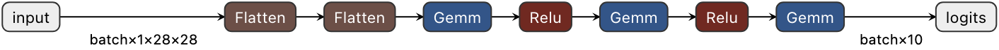

,model,input,output,mean parameters,log-variance parameters,ONNX nodes,ONNX max |error|
0,LeNet,"(1, 1, 28, 28)","(1, 10)",61706,61706,12,7.450581e-09


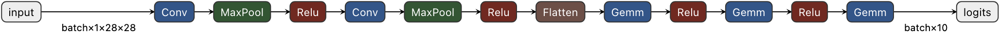

In [68]:
mnist_models = {"MLP 784-400-400-10": MomentMLP().double(),
                "LeNet": MomentLeNet().double()}
mnist_example = torch.zeros(1, 1, 28, 28, dtype=torch.float64)
mnist_architectures = {
    "MLP 784-400-400-10": show_architecture(
        "MLP 784-400-400-10", "mnist_mlp", mnist_models["MLP 784-400-400-10"], mnist_example),
    "LeNet": show_architecture(
        "LeNet", "mnist_lenet", mnist_models["LeNet"], mnist_example),
}


The layer tables are produced by `torchinfo`, PyTorch's maintained
`Model.summary`-style utility. `Param #` counts both the Gaussian mean and its
log variance; the compact row makes that distinction explicit. The ONNX
runtime check compares the exported mean network with the live PyTorch output.
Open the downloaded file in [Netron](https://netron.app) to inspect every edge.


In [70]:
# One complete native PyTorch forward/reverse semantic pass for each model.
torch.manual_seed(41)
image = torch.randn(2, 1, 28, 28)
labels = torch.tensor([2, 7])
smoke = []
for name, model in mnist_models.items():
    start = time.perf_counter()
    passed = model.forward_moments(DiagonalMoments(image, torch.zeros_like(image)))
    head = categorical_quadrature_head(passed.output, labels, "mfvi")
    messages = passed.backward(head.signal)
    smoke.append({"architecture": name, "output shape": tuple(passed.output.mean.shape),
                  "weight message blocks": len(messages.parameters),
                  "finite": bool(torch.isfinite(passed.output.mean).all()
                                 and torch.isfinite(passed.output.variance).all()),
                  "forward + backward seconds": time.perf_counter()-start})
display(pd.DataFrame(smoke))


,architecture,output shape,weight message blocks,finite,forward + backward seconds
0,MLP 784-400-400-10,"(2, 10)",6,True,0.039582
1,LeNet,"(2, 10)",10,True,0.035943


These cells establish executable architecture and message semantics. They do
not substitute a two-example smoke pass for a trained MNIST benchmark. A full
benchmark must be produced by the PyTorch training path and exported from its
own raw predictions; outputs from other frameworks are not embedded in this
PyTorch artifact.


## Trained MNIST results and uncertainty diagnostics

The following evidence comes from the original **PyTorch** MLP/LeNet runs,
not the later R/TensorFlow MNIST rerun. All five methods use categorical
classification; the MLP has two 400-unit hidden layers, and the LeNet has two
convolution/max-pooling blocks. Training, stopping and official test sets were
separated; the archived configuration and selected epoch are retained for each
run. The displayed curves use seed 41, fixed before plotting. The table uses
each available training seed separately, with mean ± standard deviation.
It never averages networks across seeds to turn a method into a deep ensemble.

The short semantic checks above and the historical training below answer
different questions. `evidence/manifest.json` identifies the exact original
implementation and checkpoint hash for each saved prediction. The new compact
trainer has **not** been shown to reproduce every original optimized run.
The uncertainty calculations below do reproduce the saved predictions' metrics.


<details><summary><strong>Shared Python result processing (used by every benchmark)</strong></summary>

```python
"""Regenerate benchmark diagnostics from original native PyTorch predictions.

No training or checkpoint loading occurs here. The same public metric and
plot functions serve all datasets. Historical times retain their device and
measurement scope; no CPU replay is advertised as GPU benchmark training.
"""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from .metrics import uncertainty_metrics, ood_metrics, ranking_curve
from .plotting import calibration_plot, risk_coverage_plot, ood_roc_plot


def load_predictions(directory, family):
    """Read authenticated native arrays with configuration/measurement receipts."""
    directory = Path(directory)
    records = []
    for r in json.loads((directory / "manifest.json").read_text()):
        if r["family"] != family:
            continue
        path = directory / r["file"]
        if hashlib.sha256(path.read_bytes()).hexdigest() != r["sha256"]:
            raise ValueError(f"changed evidence: {path.name}")
        with np.load(path) as a:
            records.append((r, {k: a[k] for k in a.files}))
    if not records:
        raise ValueError(f"no native predictions for {family}")
    return records


def native_image_predictions(directory):
    """Read completed native runs; ambiguous labels and OOD use different units."""
    records=[]
    labels={'ordinary':'Ordinary','moment_mfvi':'Moment MFVI','moment_ep':'Moment EP',
            'sampled_mfvi':'Sampled MFVI','sampled_ep':'Sampled EP'}
    for path in sorted(Path(directory).glob('*/metrics.json')):
        scores=json.loads(path.read_text());cfg=json.loads((path.parent/'config.json').read_text())
        if scores['status']!='complete_fixed_budget':continue
        with np.load(path.parent/'predictions.npz') as a:
            p,y,p_id=a['p'],a['y'],a['p']
            if 'p_ambiguous' in a:
                pa=a['p_ambiguous'];p_id=np.concatenate((p,pa))
                p=np.concatenate((p,np.repeat(pa,10,axis=0)));y=np.concatenate((y,a['ambiguous_labels'].ravel()))
            arrays=dict(probabilities=p,labels=y,ood_id_probabilities=p_id,ood_probabilities=a['p_ood'])
        record=dict(label=labels[cfg['method']],seed=cfg['seed'],ood='Fashion-MNIST',
                    configuration=cfg,measurement=scores)
        records.append((record,arrays))
    return records


def benchmark_metrics(records):
    """Every seed is evaluated separately; do not turn seeds into an ensemble."""
    rows = []
    for r, a in records:
        stats = uncertainty_metrics(a["probabilities"], a["labels"])
        if "ood_probabilities" in a:
            stats.update(ood_metrics(a["ood_id_probabilities"], a["ood_probabilities"]))
        rows.append({"method": r["label"], "seed": r["seed"], **stats})
    return pd.DataFrame(rows)


def benchmark_panel(records, title):
    """Common four-panel diagnostics. Seed 41 is fixed before viewing curves."""
    fig, axes = plt.subplots(2, 2, figsize=(9.6, 8))
    have_ood = all("ood_probabilities" in a for r, a in records if r["seed"] == 41)
    for r, a in records:
        if r["seed"] != 41:
            continue
        p, y, name = a["probabilities"], a["labels"], r["label"]
        calibration_plot(p, y, ax=axes[0, 0], label=name)
        risk_coverage_plot(p, y, ax=axes[0, 1], label=name)
        roc = ranking_curve(1-p.max(1), p.argmax(1) != y)
        axes[1, 0].plot(roc.fpr, roc.tpr, label=f"{name} ({roc.auroc:.3f})")
        if have_ood:
            ood_roc_plot(1-a["ood_id_probabilities"].max(1), 1-a["ood_probabilities"].max(1),
                         ax=axes[1, 1], label=name)
        else:
            axes[1, 1].hist(p.max(1), bins=np.linspace(0, 1, 31), histtype="step",
                            density=True, label=name)
    axes[1, 0].plot([0, 1], [0, 1], "k--", lw=.6)
    axes[1, 0].set(title="Error detection ROC (AUROC)", xlabel="correct cases flagged",
                   ylabel="errors flagged", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    if not have_ood:
        axes[1, 1].set(title="Confidence distribution", xlabel="maximum probability", ylabel="density")
    else:
        axes[1, 1].set_title(f"OOD: {records[0][0]['ood']} (MSP)")
    for ax in axes.flat:
        ax.grid(alpha=.15)
        ax.legend(fontsize=7, framealpha=.9, loc="best")
    fig.suptitle(title+" — seed 41", fontweight="bold")
    fig.tight_layout()
    return fig


def benchmark_learning(directory, family):
    """Saved validation trajectories; average only epochs present for all seeds."""
    table = pd.read_csv(Path(directory)/"learning_curves.csv")
    subset = table[(table.family == family) & (table.cohort.isin(["main", "scratch"]))]
    fig, axes = plt.subplots(2, 2, figsize=(9.6, 7))
    for name, group in subset.groupby("label", sort=False):
        color = None
        for ax, metric, x in zip(axes.flat,
                ["validation_nll", "validation_accuracy"]*2,
                ["epoch", "epoch", "training_seconds", "training_seconds"]):
            for _, seed in group.groupby("seed"):
                seed = seed.sort_values("epoch")
                line, = ax.plot(seed[x], seed[metric], alpha=.3, lw=.7, color=color)
                if color is None: color = line.get_color()
            means = group.groupby("epoch")[[x, metric]].mean() if x != "epoch" else group.groupby("epoch")[metric].mean().reset_index()
            # Recorded training time varies by seed; this is mean time at a
            # common epoch, never interpolation beyond a stopped run.
            counts = group.groupby("epoch").seed.nunique()
            keep = counts[counts == group.seed.nunique()].index
            means = means.loc[means.index.isin(keep)] if x != "epoch" else means[means.epoch.isin(keep)]
            ax.plot(means[x], means[metric], label=name, color=color)
            ax.set(xlabel=x.replace("_", " "), ylabel=metric.replace("_", " "))
            ax.legend(fontsize=7, framealpha=.9)
            ax.grid(alpha=.15)
    fig.tight_layout()
    return fig

```

</details>


In [74]:
#@title Support: shared result-table formatting (expand to inspect)
from bayesify_torch.results import load_predictions, benchmark_metrics, benchmark_panel, benchmark_learning
evidence = _repo / "pytorch" / "evidence" if (_repo / "pytorch/evidence").exists() else _repo / "evidence"

def show_benchmark(family, title, *, learning=False):
    records = load_predictions(evidence, family)
    measured = benchmark_metrics(records)
    fields = {"accuracy": "Accuracy ↑", "nll": "NLL ↓", "brier": "Brier ↓",
              "ece": "ECE ↓", "aurc": "AURC ↓", "error_auroc": "Error AUROC ↑"}
    display(HTML(f"<h3>{title}</h3>"))
    summary = measured.groupby("method", sort=False)[list(fields)].agg(["mean", "std"])
    reader = pd.DataFrame(index=summary.index)
    for key, label in fields.items():
        reader[label] = [f"{m:.5f}" + (f" ± {s:.5f}" if np.isfinite(s) else "")
                         for m, s in zip(summary[key]["mean"], summary[key]["std"])]
    display(reader)
    if "msp_auroc" in measured:
        display(measured.groupby("method", sort=False)[["msp_auroc", "msp_auprc", "msp_fpr95"]]
                .mean().rename(columns={"msp_auroc":"OOD AUROC ↑", "msp_auprc":"OOD AP ↑",
                                        "msp_fpr95":"OOD FPR95 ↓"}).round(5))
    costs = [{"method": r["label"], "seed": r["seed"], **r["costs"]}
             for r, _ in records if "costs" in r]
    if costs:
        times = pd.DataFrame(costs)
        for key in ("training_seconds", "inference_seconds"):
            times[key] = pd.to_numeric(times[key])
        timing_table = times.groupby("method", sort=False).agg(
            training_seconds=("training_seconds", "mean"), inference_seconds=("inference_seconds", "mean"),
            device=("hardware", "first"), prediction_cases=("inference_n", "first"))
        ordinary = timing_table[timing_table.index.str.startswith("Ordinary")].iloc[0]
        if timing_table.device.nunique() == 1 and timing_table.prediction_cases.nunique() == 1:
            timing_table["Train × ↓"] = timing_table.training_seconds/ordinary.training_seconds
            timing_table["Predict × ↓"] = timing_table.inference_seconds/ordinary.inference_seconds
        display(timing_table.rename(columns={"training_seconds":"Train seconds ↓",
                "inference_seconds":"Predict seconds ↓"}).round(3))
        configs = [{"method": r["label"], "seed": r["seed"], **r.get("configuration", {})}
                   for r, _ in records]
        configs = pd.DataFrame(configs)
        keys = [k for k in ["method", "seed", "lr", "tau", "epochs", "best_epoch"] if k in configs]
        display(configs[keys])
        print("Full settings, objective, checkpoint selection and timing provenance: evidence/manifest.json")
    benchmark_panel(records, title); plt.show()
    if learning:
        benchmark_learning(evidence, family); plt.show()
    return measured


Full settings, objective, checkpoint selection and timing provenance: evidence/manifest.json
Full settings, objective, checkpoint selection and timing provenance: evidence/manifest.json


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Ordinary Adam,0.97890 ± 0.00202,0.06951 ± 0.00364,0.03177 ± 0.00297,0.00692 ± 0.00137,0.00092 ± 0.00003,0.96949 ± 0.00267
Moment power-EP,0.98493 ± 0.00071,0.04756 ± 0.00193,0.02285 ± 0.00059,0.00231 ± 0.00016,0.00045 ± 0.00003,0.97843 ± 0.00082
Moment MFVI,0.98407 ± 0.00067,0.05160 ± 0.00173,0.02434 ± 0.00058,0.00379 ± 0.00063,0.00050 ± 0.00004,0.97798 ± 0.00152
Sampled power-EP,0.98310 ± 0.00036,0.05290 ± 0.00128,0.02555 ± 0.00048,0.00305 ± 0.00015,0.00056 ± 0.00005,0.97685 ± 0.00179
Sampled MFVI,0.98563 ± 0.00021,0.04714 ± 0.00149,0.02235 ± 0.00028,0.00304 ± 0.00016,0.00043 ± 0.00001,0.97822 ± 0.00126


,OOD AUROC ↑,OOD AP ↑,OOD FPR95 ↓
method,,,
Ordinary Adam,0.72659,0.78064,0.972
Moment power-EP,0.93846,0.92606,0.236
Moment MFVI,0.91419,0.89482,0.311
Sampled power-EP,0.92307,0.91044,0.334
Sampled MFVI,0.93904,0.92126,0.202


,Train seconds ↓,Predict seconds ↓,device,prediction_cases,Train × ↓,Predict × ↓
method,,,,,,
Ordinary Adam,5.084,0.004,T4,10000,1.000,1.000
Moment power-EP,39.490,0.014,T4,10000,7.767,3.385
Moment MFVI,21.631,0.011,T4,10000,4.255,2.726
Sampled power-EP,19.090,0.173,T4,10000,3.755,42.185
Sampled MFVI,6.444,0.084,T4,10000,1.267,20.500


,method,seed,lr,tau
0,Ordinary Adam,41,0.0003,0.01
1,Ordinary Adam,42,0.0003,0.01
2,Ordinary Adam,43,0.0003,0.01
3,Moment power-EP,41,0.0010,0.01
4,Moment power-EP,42,0.0010,0.01
5,Moment power-EP,43,0.0010,0.01
6,Moment MFVI,41,0.0010,0.01
7,Moment MFVI,42,0.0010,0.01
8,Moment MFVI,43,0.0010,0.01
9,Sampled power-EP,41,0.0003,0.01


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Ordinary Adam,0.98860 ± 0.00193,0.03657 ± 0.00246,0.01758 ± 0.00180,0.00397 ± 0.00127,0.00031 ± 0.00002,0.97885 ± 0.00560
Moment power-EP,0.99217 ± 0.00023,0.02354 ± 0.00238,0.01194 ± 0.00100,0.00278 ± 0.00058,0.00014 ± 0.00003,0.98682 ± 0.00252
Moment MFVI,0.99270 ± 0.00010,0.02165 ± 0.00063,0.01101 ± 0.00013,0.00198 ± 0.00045,0.00013 ± 0.00002,0.98624 ± 0.00208
Sampled power-EP,0.99173 ± 0.00055,0.02420 ± 0.00167,0.01226 ± 0.00063,0.00282 ± 0.00045,0.00015 ± 0.00003,0.98705 ± 0.00208
Sampled MFVI,0.99267 ± 0.00006,0.02250 ± 0.00094,0.01140 ± 0.00027,0.00216 ± 0.00039,0.00013 ± 0.00001,0.98664 ± 0.00182


,OOD AUROC ↑,OOD AP ↑,OOD FPR95 ↓
method,,,
Ordinary Adam,0.95843,0.94963,0.170
Moment power-EP,0.97627,0.96921,0.086
Moment MFVI,0.97806,0.97474,0.097
Sampled power-EP,0.97446,0.96912,0.102
Sampled MFVI,0.98243,0.97975,0.079


,Train seconds ↓,Predict seconds ↓,device,prediction_cases,Train × ↓,Predict × ↓
method,,,,,,
Ordinary Adam,12.808,0.022,T4,10000,1.000,1.000
Moment power-EP,26.453,0.041,T4,10000,2.065,1.844
Moment MFVI,32.757,0.041,T4,10000,2.558,1.868
Sampled power-EP,58.435,0.213,T4,10000,4.563,9.651
Sampled MFVI,15.334,0.284,T4,10000,1.197,12.876


,method,seed,lr,epochs,best_epoch
0,Ordinary Adam,41,0.001,30,5
1,Ordinary Adam,42,0.001,30,6
2,Ordinary Adam,43,0.001,30,10
3,Moment power-EP,41,0.001,30,26
4,Moment power-EP,42,0.001,30,26
5,Moment power-EP,43,0.001,30,22
6,Moment MFVI,41,0.001,30,26
7,Moment MFVI,42,0.001,30,30
8,Moment MFVI,43,0.001,30,22
9,Sampled power-EP,41,0.001,30,26


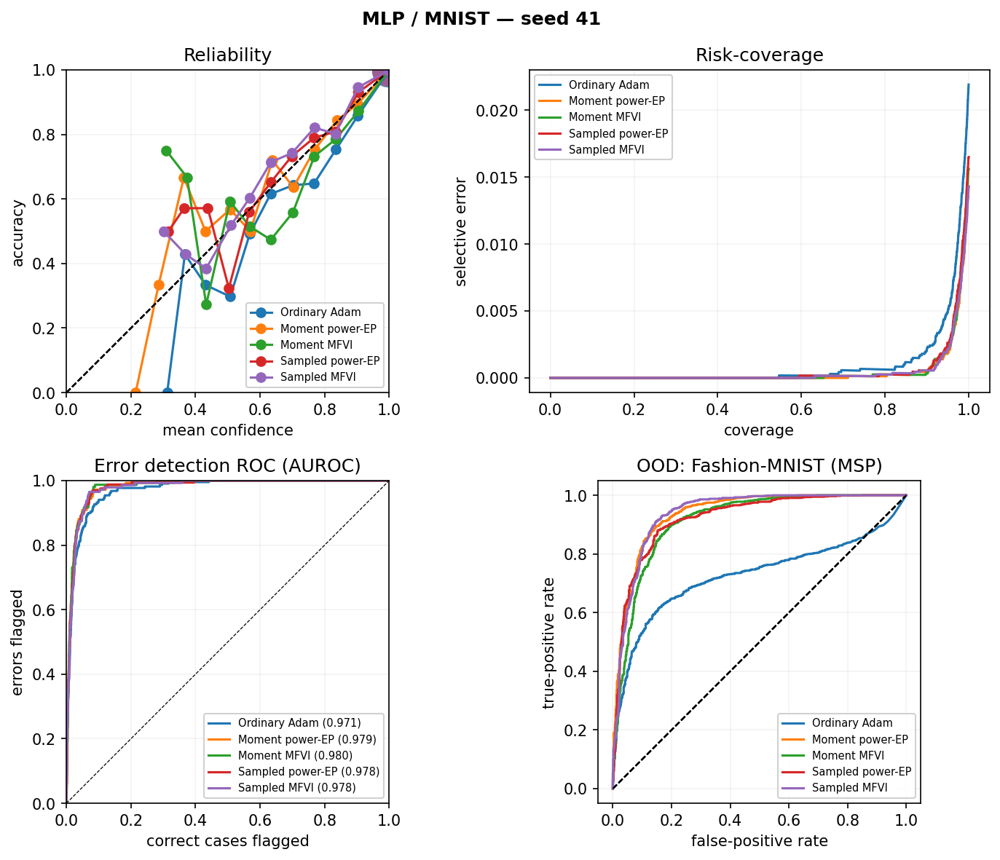

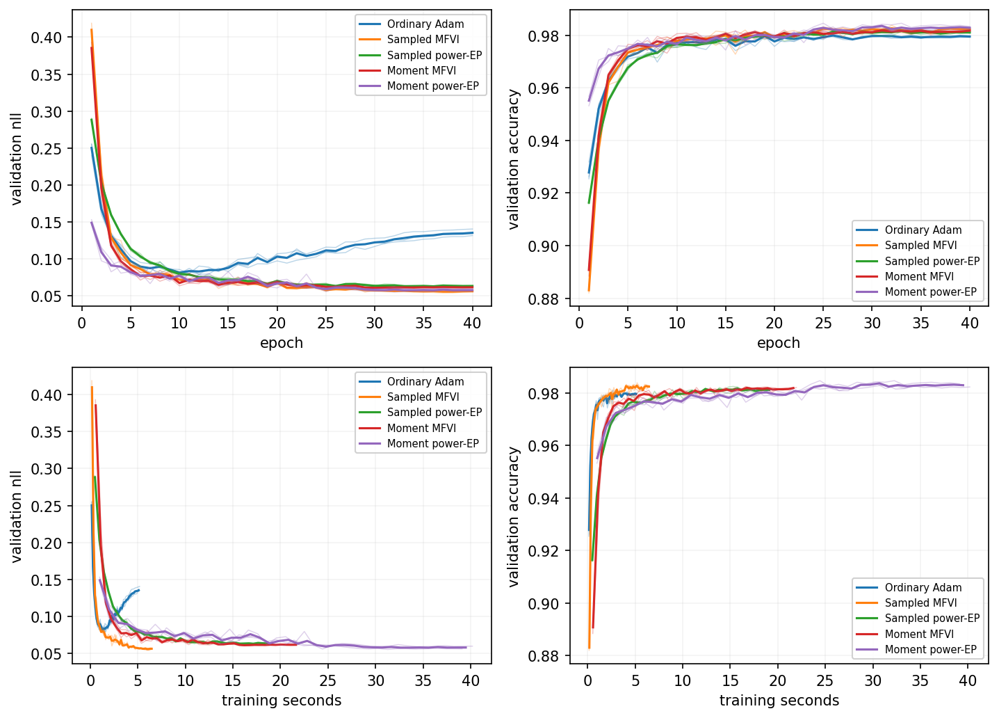

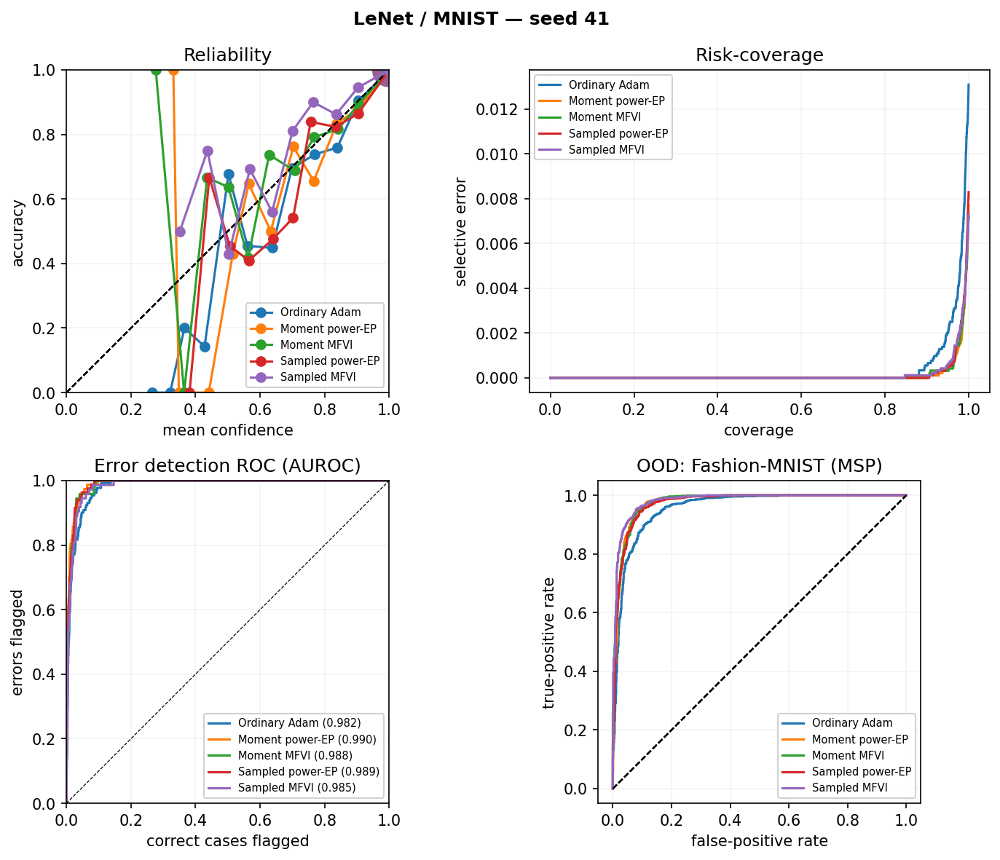

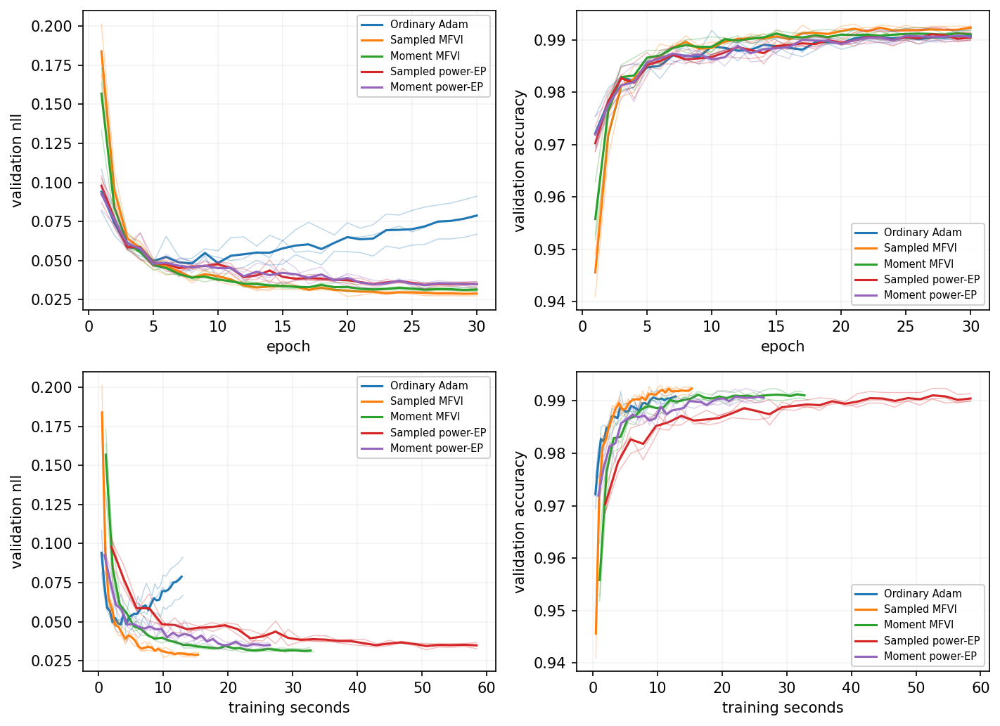

In [75]:
mlp_results = show_benchmark("mlp", "MLP / MNIST", learning=True)
lenet_results = show_benchmark("lenet", "LeNet / MNIST", learning=True)


The combined diagnostics distinguish calibration, error ranking and OOD
ranking. Fashion-MNIST is the recorded OOD control.
Training and inference times above are historical GPU measurements, not the
time taken to rebuild this notebook. Compilation/setup, stopping policy,
prediction sample count and device must be considered before comparing costs.
The full configuration remains expandable immediately beside its result.


## Dirty-MNIST: uncertainty about ambiguous digits

The native LeNet comparison below trains all five methods for 30 epochs on
110,000 observations, with a fixed 10,000-observation validation set. Repeated
labels of an ambiguous image remain in the same split. Proper scores count all
ten labels; OOD ranking counts each image once. Fashion-MNIST is the OOD control,
while ambiguous digits remain in distribution. No new hyperparameter search is
used in this port check. Each method is reported separately at seed 41.

The source is `run_training.py --architecture lenet --dataset dirty --method …`.
The eager implementation executes the explicit local reverse traversal at every
update. Its timings are measured here; they are not replaced by the historical
optimized implementation's timings.


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
0,Moment EP,0.83267,0.48972,0.01436,0.24608,0.05180,0.82051,0.88076,2091.70551,32.96933,1.61062,33.42572
1,Moment MFVI,0.83444,0.48366,0.01240,0.24327,0.05091,0.82153,0.89321,1889.71048,29.78550,1.56823,32.54606
2,Ordinary,0.82627,0.50594,0.01544,0.25429,0.05532,0.81645,0.90059,63.44398,1.00000,0.04818,1.00000
3,Sampled EP,0.83150,0.48960,0.01370,0.24582,0.05179,0.82295,0.88733,707.17023,11.14637,2.33370,48.43203
4,Sampled MFVI,0.83411,0.48167,0.01233,0.24303,0.05039,0.82414,0.90883,196.39535,3.09557,2.19888,45.63421


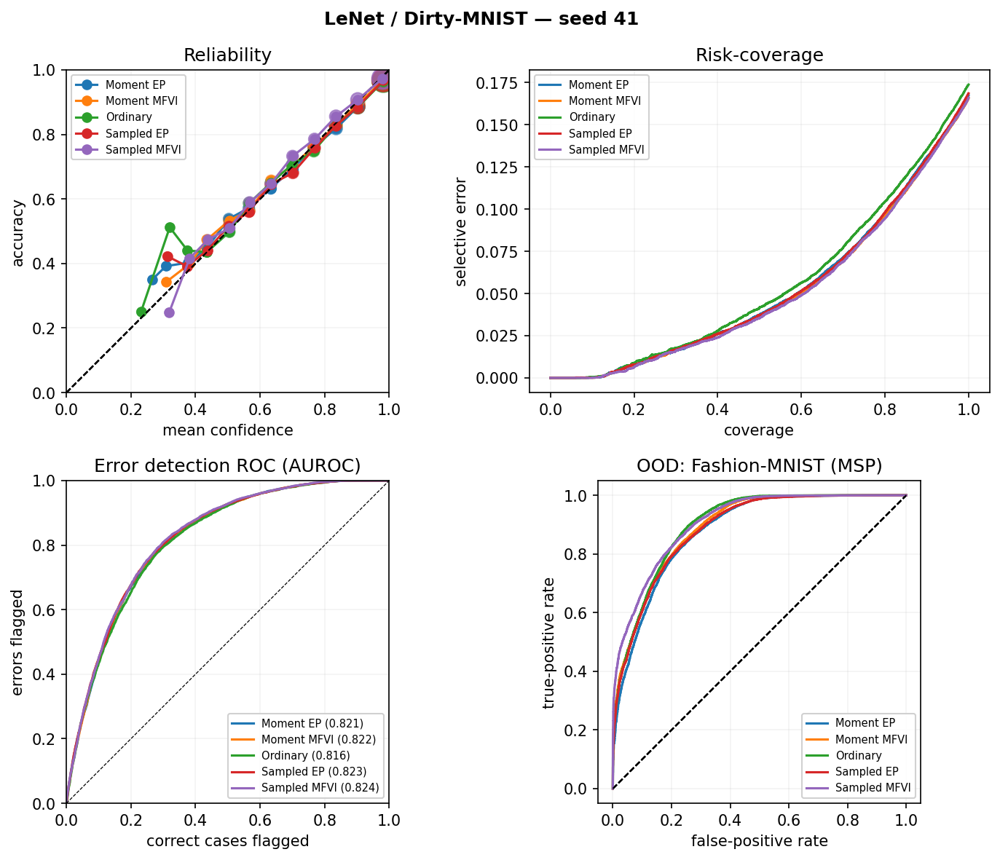

In [78]:
from bayesify_torch.results import native_image_predictions
dirty = native_image_predictions(evidence / "native_dirty")
assert len(dirty)==5, "The complete native Dirty-MNIST evidence must be bundled."
table = benchmark_metrics(dirty)
for name,key in [("Train s ↓","training_seconds"),("Infer s ↓","inference_seconds")]:
    table[name]=[r["measurement"][key] for r,a in dirty]
ordinary=table[table.method=="Ordinary"].iloc[0]
table["Train × ↓"]=table["Train s ↓"]/ordinary["Train s ↓"]
table["Infer × ↓"]=table["Infer s ↓"]/ordinary["Infer s ↓"]
display(table[["method","accuracy","nll","ece","brier","aurc","error_auroc","msp_auroc",
               "Train s ↓","Train × ↓","Infer s ↓","Infer × ↓"]].rename(columns={
    "accuracy":"Accuracy ↑","nll":"NLL ↓","ece":"ECE ↓","brier":"Brier ↓",
    "aurc":"AURC ↓","error_auroc":"Error AUROC ↑","msp_auroc":"OOD AUROC ↑"}).round(5))
benchmark_panel(dirty,"LeNet / Dirty-MNIST");plt.show()


Inference seconds use the common 10,000-image clean-MNIST cohort, rather than
mixing computation for repeated ambiguous labels into the timing. Moment models
use one moment pass; sampled models use 20 networks. These are the original
warmed cohort measurements from each complete run. The separate values-only
prediction optimization is checked against a live backward-record traversal
and does not replace those historical run times. The reported probability
scores include the ambiguous labels. These one-seed results validate the full
native path and do not establish a universal Bayesian advantage.


# 5. CIFAR-10: ResNet-20 and DenseNet-40

ResNet-20 contains three stages of three residual blocks and the option-A
stride-two shortcut. DenseNet-40 has three 12-layer dense blocks with growth
12 and no bottleneck/compression. Addition and concatenation are ordinary DAG
nodes, so all reverse contributions meet before their shared parent is visited.


In [81]:
from bayesify_torch.architectures import *

def _conv(cin: int, cout: int, kernel: int = 3, stride: int = 1) -> MomentConv2d:
    layer = MomentConv2d(
        cin, cout, kernel, stride=stride, padding=kernel // 2, bias=False, prior_variance=1e-3
    )
    nn.init.kaiming_normal_(layer.weight.mean, mode="fan_out", nonlinearity="relu")
    return layer

class MomentCifarNet(nn.Module):
    """A native PyTorch model with deterministic and moment/message entry points."""

    def __init__(self, graph: MomentDAG, architecture: str):
        super().__init__()
        self.network, self.architecture = graph, architecture

    def forward(self, x: Tensor) -> Tensor:
        return self.network(x)

    def forward_moments(self, x: DiagonalMoments) -> GraphPass:
        # CIFAR BatchNorm and option-A shortcut use the projected local VJP.
        # The primitive dense/conv/ReLU equations retain separate literal tests.
        return self.network.forward_moments(x, literal=False)

    @property
    def mean_parameter_count(self) -> int:
        return sum(module.mean.numel() for module in self.modules() if hasattr(module, "mean"))

def resnet20(classes: int = 10) -> MomentCifarNet:
    """Original CIFAR ResNet-20: three stages, three residual blocks per stage."""
    nodes: list[tuple[str, nn.Module, tuple[str, ...]]] = []

    def add(name: str, layer: nn.Module, *parents: str) -> str:
        nodes.append((name, layer, tuple(parents)))
        return name

    x = add("stem_conv", _conv(3, 16), "input")
    x = add("stem_bn", MomentBatchNorm2d(16), x)
    x = add("stem_relu", MomentReLU(), x)
    channels = 16
    for stage, output_channels in enumerate((16, 32, 64), start=1):
        for block in range(1, 4):
            prefix = f"stage{stage}_block{block}"
            stride = 2 if stage > 1 and block == 1 else 1
            skip = x if stride == 1 else add(f"{prefix}_shortcut", MomentCifarShortcut(), x)
            h = add(f"{prefix}_conv1", _conv(channels, output_channels, stride=stride), x)
            h = add(f"{prefix}_bn1", MomentBatchNorm2d(output_channels), h)
            h = add(f"{prefix}_relu1", MomentReLU(), h)
            h = add(f"{prefix}_conv2", _conv(output_channels, output_channels), h)
            h = add(f"{prefix}_bn2", MomentBatchNorm2d(output_channels), h)
            x = add(f"{prefix}_sum", MomentAdd(), skip, h)
            x = add(f"{prefix}_relu2", MomentReLU(), x)
            channels = output_channels
    x = add("global_pool", MomentGlobalAvgPool2d(), x)
    add("classifier", MomentLinear(channels, classes, prior_variance=1e-3), x)
    return MomentCifarNet(MomentDAG(nodes), "resnet20")

def densenet40(classes: int = 10, growth: int = 12) -> MomentCifarNet:
    """CIFAR DenseNet-40, growth 12, without bottlenecks or compression."""
    nodes: list[tuple[str, nn.Module, tuple[str, ...]]] = []

    def add(name: str, layer: nn.Module, *parents: str) -> str:
        nodes.append((name, layer, tuple(parents)))
        return name

    channels = 16
    x = add("stem_conv", _conv(3, channels), "input")
    for stage in range(1, 4):
        for block in range(1, 13):
            prefix = f"dense{stage}_{block}"
            h = add(f"{prefix}_bn", MomentBatchNorm2d(channels), x)
            h = add(f"{prefix}_relu", MomentReLU(), h)
            h = add(f"{prefix}_conv", _conv(channels, growth), h)
            x = add(f"{prefix}_concat", MomentConcat(dim=1), x, h)
            channels += growth
        if stage < 3:
            prefix = f"transition{stage}"
            x = add(f"{prefix}_bn", MomentBatchNorm2d(channels), x)
            x = add(f"{prefix}_relu", MomentReLU(), x)
            x = add(f"{prefix}_conv", _conv(channels, channels, kernel=1), x)
            x = add(f"{prefix}_pool", MomentAvgPool2d(2), x)
    x = add("final_bn", MomentBatchNorm2d(channels), x)
    x = add("final_relu", MomentReLU(), x)
    x = add("global_pool", MomentGlobalAvgPool2d(), x)
    add("classifier", MomentLinear(channels, classes, prior_variance=1e-3), x)
    return MomentCifarNet(MomentDAG(nodes), "densenet40")


,model,input,output,mean parameters,log-variance parameters,ONNX nodes,ONNX max |error|
0,ResNet-20,"(1, 3, 32, 32)","(1, 10)",269722,269722,55,0.0






,model,input,output,mean parameters,log-variance parameters,ONNX nodes,ONNX max |error|
0,DenseNet-40 (growth 12),"(1, 3, 32, 32)","(1, 10)",1019722,1019722,157,0.0






In [82]:
native_cifar = {"ResNet-20": resnet20().float(), "DenseNet-40 (growth 12)": densenet40().float()}
cifar_example = torch.zeros(1, 3, 32, 32)
cifar_architectures = {
    "ResNet-20": show_architecture(
        "ResNet-20", "cifar_resnet20", native_cifar["ResNet-20"], cifar_example, inline=False),
    "DenseNet-40 (growth 12)": show_architecture(
        "DenseNet-40 (growth 12)", "cifar_densenet40",
        native_cifar["DenseNet-40 (growth 12)"], cifar_example, inline=False),
}


The complete ResNet and DenseNet graphs are deliberately scrollable instead
of being shrunk into an unreadable page thumbnail. Netron shows the actual
residual additions and dense concatenations. The ONNX files are executable
mean networks; Gaussian variances and reverse messages remain in the PyTorch
modules and are documented by the parameter split and inference sections.


In [84]:
torch.manual_seed(9)
cifar_input, cifar_label = torch.randn(1,3,32,32, dtype=torch.float32), torch.tensor([4])
cifar_smoke = []
for name, model in native_cifar.items():
    model.eval()
    start = time.perf_counter()
    passed = model.forward_moments(DiagonalMoments(cifar_input, torch.zeros_like(cifar_input)))
    child = categorical_quadrature_head(passed.output, cifar_label, "ep", power=.5).signal
    messages = passed.backward(child)
    cifar_smoke.append({"architecture": name, "DAG nodes": len(model.network.nodes),
                        "weight message blocks": len(messages.parameters),
                        "finite": all(torch.isfinite(value.delta_mean).all()
                                      for value in messages.parameters.values()),
                        "forward + backward seconds": time.perf_counter()-start})
display(pd.DataFrame(cifar_smoke))


,architecture,DAG nodes,weight message blocks,finite,forward + backward seconds
0,ResNet-20,70,59,True,0.391320
1,DenseNet-40 (growth 12),157,119,True,1.687464


The native smoke pass verifies that graph semantics survive loops in the
undirected inference view: skip and dense connections accumulate one message
per edge, while each persistent weight belief receives one accumulated update.
It is not a replacement for a full CIFAR-10 training run, so no result from a
different implementation is shown here.


## Trained residual and dense networks

These original PyTorch runs trained from scratch for 100 epochs, with a fixed
5,000-example validation cohort used for checkpoint selection. This is the
archived validation comparison, **not** the later R/TensorFlow official-test
table. The OOD control is SVHN (1,000 predeclared ID and 1,000 OOD cases).
ResNet and DenseNet share the definitions
of NLL, calibration, selective risk and error/OOD ROC used for MNIST. They
retain separate timing receipts; a speed ratio across different devices would
not be meaningful.

The skip-connection test establishes correct accumulation on a computation
DAG. Covariance approximation and the choice of finite optimizer remain
separate questions; cycles in an undirected factor graph do not turn a
feed-forward residual network into a recurrent computation.


Full settings, objective, checkpoint selection and timing provenance: evidence/manifest.json
Full settings, objective, checkpoint selection and timing provenance: evidence/manifest.json


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Moment MFVI,0.91780,0.31494,0.12888,0.02525,0.01323,0.89842
Ordinary AdamW,0.90040,0.35945,0.15440,0.04357,0.01614,0.90323
Moment power-EP,0.91600,0.28724,0.12803,0.02547,0.01276,0.90712
Sampled power-EP,0.90220,0.34566,0.15160,0.03810,0.01525,0.90605
Sampled MFVI,0.91360,0.28173,0.12613,0.01101,0.01159,0.91959


,OOD AUROC ↑,OOD AP ↑,OOD FPR95 ↓
method,,,
Moment MFVI,0.81849,0.78308,0.513
Ordinary AdamW,0.90538,0.87295,0.294
Moment power-EP,0.90165,0.87982,0.325
Sampled power-EP,0.92440,0.88967,0.207
Sampled MFVI,0.89010,0.85174,0.291


,Train seconds ↓,Predict seconds ↓,device,prediction_cases,Train × ↓,Predict × ↓
method,,,,,,
Moment MFVI,2221.375,0.108,A100,5000,8.920,2.801
Ordinary AdamW,249.031,0.039,A100,5000,1.000,1.000
Moment power-EP,1270.690,0.108,A100,5000,5.103,2.800
Sampled power-EP,1047.385,0.651,A100,5000,4.206,16.877
Sampled MFVI,292.316,0.652,A100,5000,1.174,16.888


,method,seed,lr,tau,epochs
0,moment_vadam,41,0.003,0.001,100
1,adamw,41,0.003,0.010,100
2,moment_ep,41,0.003,0.010,100
3,sampled_ep,41,0.003,0.001,100
4,sampled_vadam,41,0.003,0.001,100


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Ordinary AdamW,0.89840,0.34889,0.15341,0.04831,0.01481,0.91619
Sampled power-EP,0.89800,0.33821,0.15140,0.04633,0.01431,0.92033
Sampled MFVI,0.93100,0.21529,0.10000,0.01124,0.00760,0.93246
Moment power-EP,0.91960,0.28146,0.12112,0.01769,0.01306,0.90134
Moment MFVI,0.93220,0.26372,0.10636,0.02691,0.00896,0.91362


,OOD AUROC ↑,OOD AP ↑,OOD FPR95 ↓
method,,,
Ordinary AdamW,0.88088,0.85080,0.350
Sampled power-EP,0.85328,0.81437,0.408
Sampled MFVI,0.87614,0.82025,0.357
Moment power-EP,0.70629,0.66750,0.696
Moment MFVI,0.89252,0.84934,0.294


,Train seconds ↓,Predict seconds ↓,device,prediction_cases,Train × ↓,Predict × ↓
method,,,,,,
Ordinary AdamW,1651.976,0.421,A100,5000,1.000,1.000
Sampled power-EP,6732.753,6.869,A100,5000,4.076,16.298
Sampled MFVI,1744.275,6.872,A100,5000,1.056,16.305
Moment power-EP,7728.741,1.014,A100,5000,4.678,2.406
Moment MFVI,15242.695,1.015,A100,5000,9.227,2.409


,method,seed,lr,tau,epochs
0,adamw,41,0.003,0.010,100
1,sampled_ep,41,0.003,0.001,100
2,sampled_vadam,41,0.003,0.001,100
3,moment_ep,41,0.003,0.010,100
4,moment_vadam,41,0.003,0.001,100


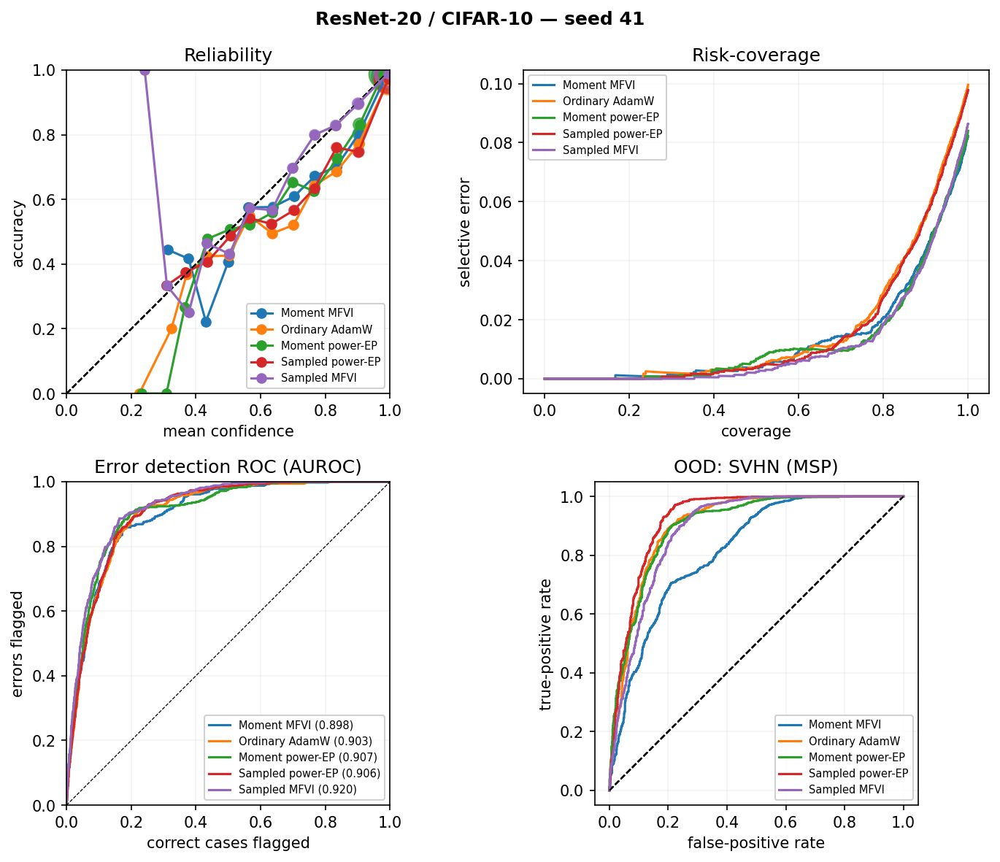

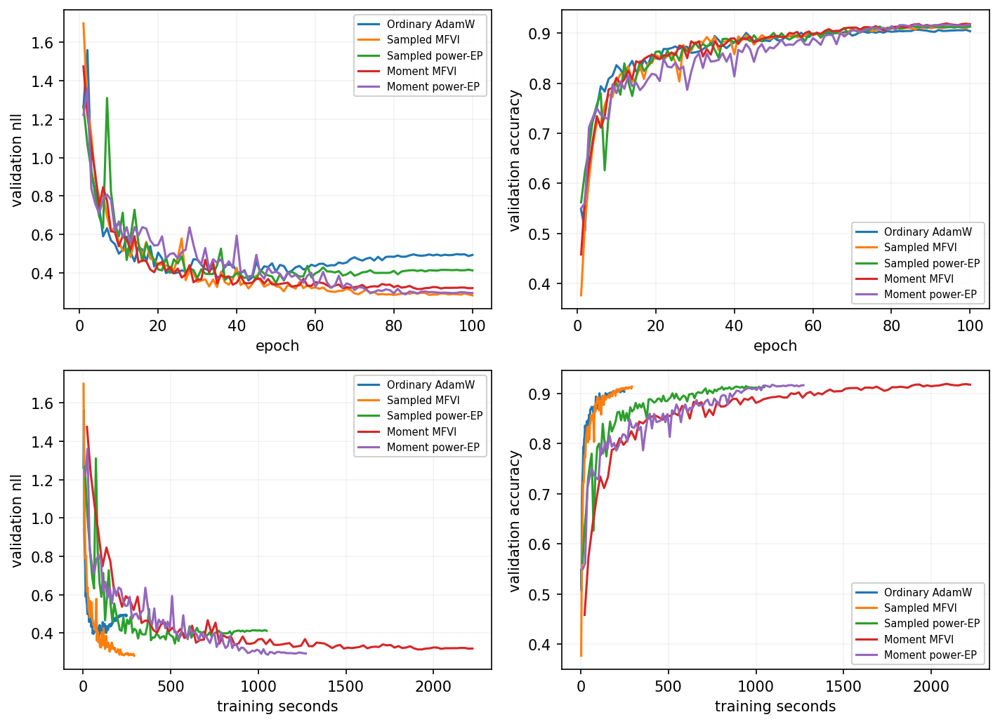

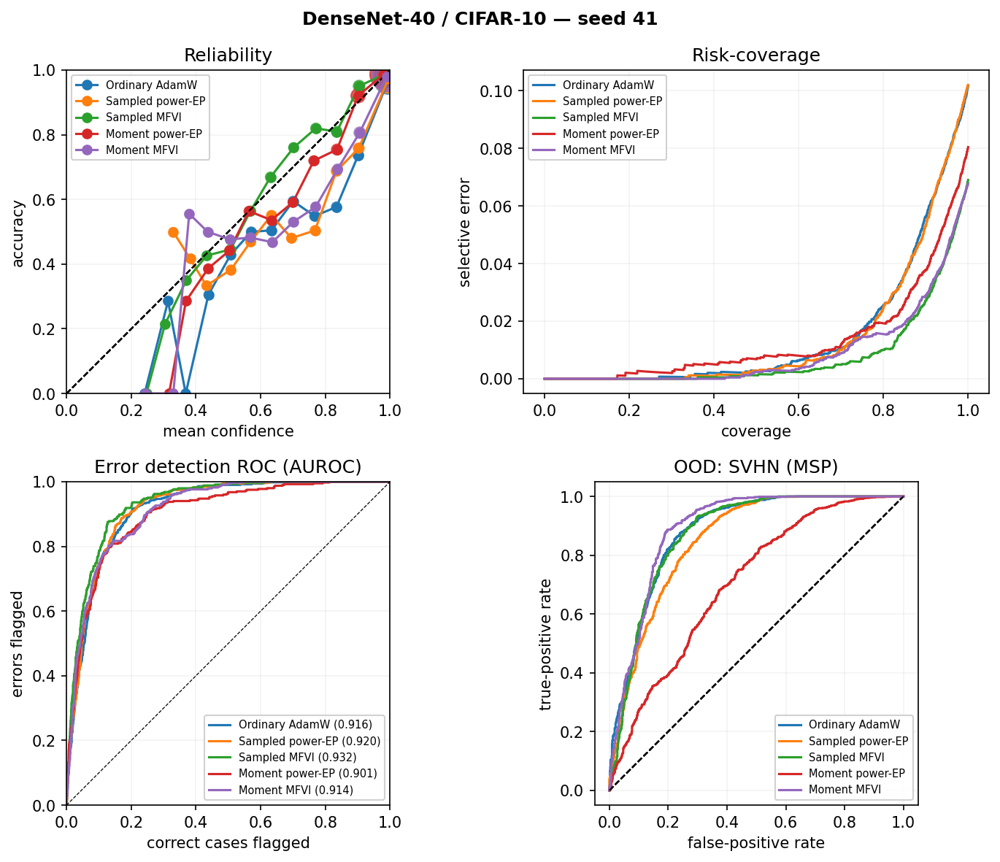

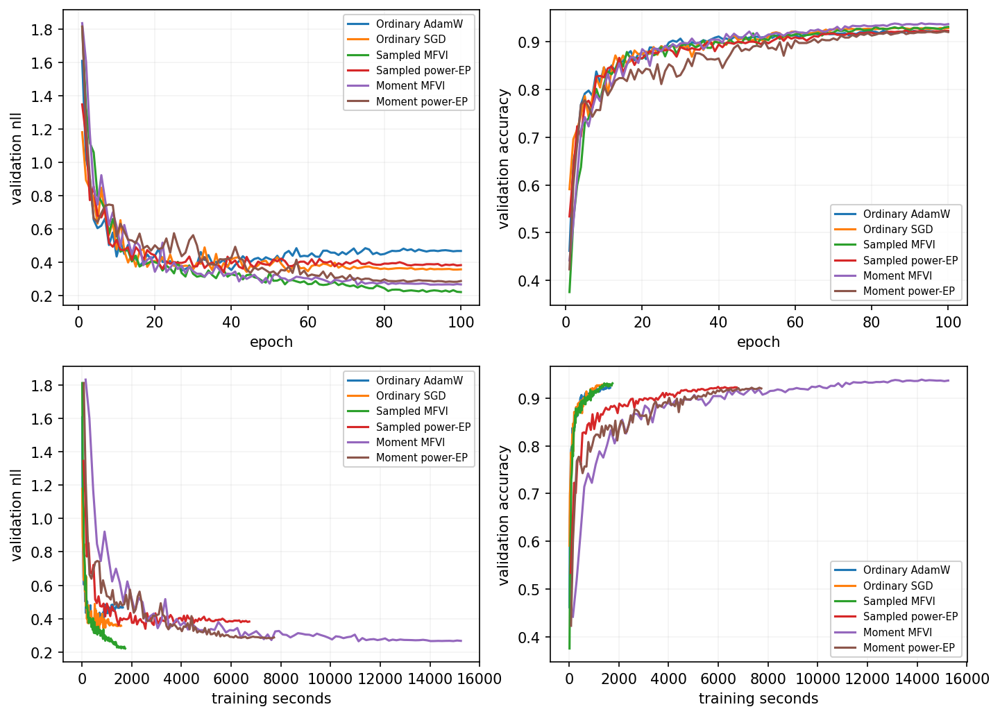

In [87]:
resnet_results = show_benchmark("resnet20", "ResNet-20 / CIFAR-10", learning=True)
densenet_results = show_benchmark("densenet40", "DenseNet-40 / CIFAR-10", learning=True)


# 6. GPT-2 with rank-4 Q/V LoRA on SST-2

Only the adapters are uncertain. A complete draw is shared across all tokens
and examples. The moment path retains shared covariance carriers through the
transformer and averages class probabilities at the verbalizer. The original
training sources are already PyTorch modules and are included unchanged.


### LayerNorm, attention and LoRA: the actual directional equations

For LayerNorm, $a=x-\bar x$, $s=(d^{-1}\|a\|^2+\varepsilon)^{-1/2}$.
Its directional derivative is
$\delta y=\gamma s[\delta x-\overline{\delta x}-a s^2\overline{a\delta x}]
+\delta\gamma\,sa+\delta\beta$.
Differentiate the centering, variance and scale successively to obtain this
expression. Merely scaling each marginal variance by $\gamma^2s^2$ omits both
projection terms. The local JVP in the notebook includes them.

For attention, $S=QK^\top/\sqrt d$, $P=\mathrm{softmax}(S)$, $O=PV$.
The three directional equations are
$\delta S=(\delta QK^\top+Q\delta K^\top)/\sqrt d$,
$\delta P=P\odot[\delta S-\sum_jP_j\delta S_j]$, and
$\delta O=\delta P V+P\delta V$.
Shared columns preserve $Q$–$K$–$V$ cross terms that independent marginal
propagation discards. Causal and padding masks remain deterministic.

For LoRA, $Y=XW_0+cXAB$ and
$\delta Y=\delta X(W_0+cAB)+cX\delta A B+cXA\delta B$.
The first-order rule omits $cX\delta A\delta B$ and related products involving
$\delta X$. If $B=0$ at initialization, the first-order derivative with respect
to $A$ vanishes, while the product uncertainty need not vanish. Therefore the
initial and learned-belief tests must both be run; checking only the mean
network or only late checkpoints misses this failure mode.


**Key code: local moment push, explicit reverse and probability integration (gpt2/moments.py)**

```python
@staticmethod
def push(function,mean,factors,weights,directions):
    """All branch cross terms survive because every operand shares r."""
    primals=(mean,*weights)
    value=function(*primals)
    def tangent(*d):return torch.func.jvp(function,primals,d)[1]
    out=torch.vmap(tangent)(factors,*directions)
    return value,out

def reverse(self,trace,grad_mean,grad_factors,variances):
    """Local cached VJP; no exact-posterior or global-Jacobian substitution.

    Adjacent moment-signal encode/decode cancel at regular boundaries.
    Singular low-rank boundaries remain in factor coordinates rather than
    adding fake covariance to make a Fisher inverse possible.
    """
    gm=[];gd=[];a,b=grad_mean,grad_factors
    for f,h,u,w,d in reversed(trace):
        n=len(w)
        def local(hh,uu,*z):return self.push(f,hh,uu,z[:n],z[n:])
        _,pull=torch.func.vjp(local,h,u,*w,*d)
        result=pull((a,b));a,b=result[:2]
        if n:gm[0:0]=result[2:2+n];gd[0:0]=result[2+n:]
    gv=[(g*e).sum(0)/(2*v.sqrt()) for g,e,v in zip(gd,self.probes,variances)]
    return gm,gv

def binary_probability(m,U,nodes,node_weights):
    mean=m[:,1]-m[:,0];variance=(U[:,:,1]-U[:,:,0]).square().mean(0)
    positive=(torch.sigmoid(mean[:,None]+variance.clamp_min(1e-30).sqrt()[:,None]*nodes)*node_weights).sum(-1)
    return torch.stack((1-positive,positive),-1)
```


In [91]:
#@title Support: GPT-2 source inventory (expand to inspect)
from pathlib import Path
for path in ["python/gpt2/model.py", "python/gpt2/moments.py",
             "python/gpt2/optimizers.py", "python/gpt2/moment_training.py"]:
    text = (_reference_repo / path).read_text()
    tree = ast.parse(text)
    names = [node.name for node in tree.body if isinstance(node, (ast.ClassDef, ast.FunctionDef))]
    print(f"{path}: {', '.join(names)}")


python/gpt2/model.py: GaussianWeight, QVLoRA, GPT2LoRA
python/gpt2/moments.py: TransformerMoments, binary_head, binary_probability
python/gpt2/optimizers.py: cavity_field, field_pullback, Vadam, sampled_vadam_step, sampled_ep_step
python/gpt2/moment_training.py: MomentStep


<details><summary><strong>Native PyTorch source: GPT-2 LoRA model</strong></summary>

```python
"""GPT-2 with Gaussian Q/V LoRA blocks. No backbone weights are trained.

Each draw is one complete adapter network, shared across all examples/tokens.
The frozen LM head evaluates only the two declared sentiment token rows.
"""
import torch
from torch import nn
from torch.nn import functional as F
from transformers import GPT2Model, AutoTokenizer


class GaussianWeight(nn.Module):
    def __init__(self, shape, std, variance):
        super().__init__()
        self.mean = nn.Parameter(torch.randn(shape) * std)
        self.log_variance = nn.Parameter(torch.full(shape, variance).log())


class QVLoRA(nn.Module):
    def __init__(self, base, rank=4, alpha=32, variance=1e-6):
        super().__init__(); self.base=base; self.scale=alpha/rank
        d=base.weight.shape[0]
        self.blocks=nn.ModuleList([GaussianWeight((d,rank),.02,variance),
            GaussianWeight((rank,d),0.,variance), GaussianWeight((d,rank),.02,variance),
            GaussianWeight((rank,d),0.,variance)])
        self.current=None

    def forward(self,x):
        a,b,c,d=self.current if self.current is not None else [p.mean for p in self.blocks]
        q=(x@a)@b; v=(x@c)@d
        return self.base(x)+self.scale*torch.cat((q,torch.zeros_like(q),v),dim=-1)


class GPT2LoRA(nn.Module):
    def __init__(self, path, seed=41, variance=1e-6, device='cuda'):
        super().__init__(); torch.manual_seed(seed)
        self.backbone=GPT2Model.from_pretrained(path,attn_implementation='eager')
        for p in self.backbone.parameters(): p.requires_grad_(False)
        self.backbone.eval()  # Dropout is disabled for every method, not weight uncertainty.
        for block in self.backbone.h:
            block.attn.c_attn=QVLoRA(block.attn.c_attn,variance=variance)
        tok=AutoTokenizer.from_pretrained(path)
        neg,pos=tok.encode(' negative'),tok.encode(' positive')
        assert len(neg)==len(pos)==1
        self.register_buffer('label_ids',torch.tensor([neg[0],pos[0]]))
        self.to(device)

    @property
    def layers(self):
        return [p for b in self.backbone.h for p in b.attn.c_attn.blocks]

    def belief(self):
        return [p.mean for p in self.layers],[p.log_variance.exp() for p in self.layers]

    def forward(self,ids,mask,weights=None):
        if weights is None: weights=[p.mean for p in self.layers]
        for i,block in enumerate(self.backbone.h): block.attn.c_attn.current=weights[4*i:4*i+4]
        h=self.backbone(input_ids=ids,attention_mask=mask,use_cache=False).last_hidden_state
        last=h[torch.arange(len(ids),device=ids.device),mask.sum(-1)-1]
        return F.linear(last,self.backbone.wte.weight[self.label_ids])

    def belief_state(self):
        return [{k:v.detach().cpu() for k,v in p.state_dict().items()} for p in self.layers]

    def restore_belief(self,state):
        for p,s in zip(self.layers,state): p.load_state_dict(s)

```

</details>


<details><summary><strong>Native PyTorch source: transformer moment carriers</strong></summary>

```python
"""Shared-factor GPT-2 moment modules, with explicit local reverse traversal.

Initial closure: relinearize at CURRENT means on every forward pass, not a
frozen checkpoint. U carries common uncertainty directions through Q/K/V,
LayerNorm and residual branches. C = mean_r U_r U_r^T is PSD but approximate.
This module is a baseline to diagnose against samples, not an exact Gaussian
transformer or a claim that low-rank covariance is already sufficient.
"""
import math
import torch
from torch.nn import functional as F


class TransformerMoments:
    def __init__(self,model,rank=4,seed=901):
        self.model=model;self.rank=rank
        g=torch.Generator(device=model.label_ids.device).manual_seed(seed)
        self.probes=[torch.randint(0,2,(rank,)+tuple(p.mean.shape),device=p.mean.device,generator=g).to(p.mean.dtype)*2-1
                     for p in model.layers]

    def embedding(self,ids):
        b=self.model.backbone
        positions=torch.arange(ids.shape[1],device=ids.device)
        return b.wte(ids)+b.wpe(positions)

    @staticmethod
    def norm(x,layer):
        return F.layer_norm(x,layer.normalized_shape,layer.weight,layer.bias,layer.eps)

    def block_function(self,index,mask):
        block=self.model.backbone.h[index];attn=block.attn;adapter=attn.c_attn
        assert not attn.scale_attn_by_inverse_layer_idx and not attn.reorder_and_upcast_attn
        def function(h,a,b,c,d):
            x=self.norm(h,block.ln_1)
            qkv=x@adapter.base.weight+adapter.base.bias
            q=(x@a)@b;v=(x@c)@d
            qkv=qkv+adapter.scale*torch.cat((q,torch.zeros_like(q),v),-1)
            q,k,v=qkv.split(h.shape[-1],dim=-1)
            B,T,D=q.shape;H=attn.num_heads
            reshape=lambda t:t.reshape(B,T,H,D//H).transpose(1,2)
            q,k,v=map(reshape,(q,k,v))
            scores=q@k.transpose(-1,-2)
            if attn.scale_attn_weights:scores=scores/math.sqrt(D//H)
            causal=torch.ones((T,T),dtype=torch.bool,device=h.device).tril()
            valid=causal[None,None]&mask[:,None,None,:].bool()
            scores=scores.masked_fill(~valid,torch.finfo(scores.dtype).min)
            context=(scores.softmax(-1)@v).transpose(1,2).reshape(B,T,D)
            h=h+context@attn.c_proj.weight+attn.c_proj.bias
            x=self.norm(h,block.ln_2)
            x=block.mlp.act(x@block.mlp.c_fc.weight+block.mlp.c_fc.bias)
            return h+x@block.mlp.c_proj.weight+block.mlp.c_proj.bias
        return function

    def head_function(self,mask):
        b=self.model.backbone
        def head(h):
            x=self.norm(h,b.ln_f)
            last=x[torch.arange(len(x),device=x.device),mask.sum(-1)-1]
            return F.linear(last,b.wte.weight[self.model.label_ids])
        return head

    @staticmethod
    def push(function,mean,factors,weights,directions):
        """All branch cross terms survive because every operand shares r."""
        primals=(mean,*weights)
        value=function(*primals)
        def tangent(*d):return torch.func.jvp(function,primals,d)[1]
        out=torch.vmap(tangent)(factors,*directions)
        return value,out

    def point(self,ids,mask,weights):
        h=self.embedding(ids)
        for i in range(len(self.model.backbone.h)):h=self.block_function(i,mask)(h,*weights[4*i:4*i+4])
        return self.head_function(mask)(h)

    def forward(self,ids,mask,means,variances,cache=False):
        h=self.embedding(ids);u=torch.zeros((self.rank,)+h.shape,device=h.device,dtype=h.dtype)
        directions=[v.sqrt()[None]*e for v,e in zip(variances,self.probes)]
        trace=[]
        for i in range(len(self.model.backbone.h)):
            f=self.block_function(i,mask);w=means[4*i:4*i+4];d=directions[4*i:4*i+4]
            if cache:trace.append((f,h,u,w,d))
            h,u=self.push(f,h,u,w,d)
        if cache:trace.append((self.head_function(mask),h,u,[],[]))
        m,U=self.push(self.head_function(mask),h,u,[],[])
        return (m,U),trace

    def reverse(self,trace,grad_mean,grad_factors,variances):
        """Local cached VJP; no exact-posterior or global-Jacobian substitution.

        Adjacent moment-signal encode/decode cancel at regular boundaries.
        Singular low-rank boundaries remain in factor coordinates rather than
        adding fake covariance to make a Fisher inverse possible.
        """
        gm=[];gd=[];a,b=grad_mean,grad_factors
        for f,h,u,w,d in reversed(trace):
            n=len(w)
            def local(hh,uu,*z):return self.push(f,hh,uu,z[:n],z[n:])
            _,pull=torch.func.vjp(local,h,u,*w,*d)
            result=pull((a,b));a,b=result[:2]
            if n:gm[0:0]=result[2:2+n];gd[0:0]=result[2+n:]
        gv=[(g*e).sum(0)/(2*v.sqrt()) for g,e,v in zip(gd,self.probes,variances)]
        return gm,gv


def binary_head(m,U,y,nodes,node_weights,expected=True,power=1.):
    """Integrate the scalar logit contrast, not independent class probabilities."""
    mean=m[:,1]-m[:,0]
    variance=(U[:,:,1]-U[:,:,0]).square().mean(0)
    z=mean[:,None]+variance.clamp_min(1e-30).sqrt()[:,None]*nodes
    ll=F.logsigmoid((2*y[:,None]-1)*z)
    if expected:return -(ll*node_weights).sum(-1).mean()
    return -(torch.logsumexp(power*ll+node_weights.log(),-1)/power).mean()


def binary_probability(m,U,nodes,node_weights):
    mean=m[:,1]-m[:,0];variance=(U[:,:,1]-U[:,:,0]).square().mean(0)
    positive=(torch.sigmoid(mean[:,None]+variance.clamp_min(1e-30).sqrt()[:,None]*nodes)*node_weights).sum(-1)
    return torch.stack((1-positive,positive),-1)

```

</details>


In [94]:
from bayesify_torch.transformer_inspection import transformer_summary, export_transformer
text, counts = transformer_summary(_reference_repo, "sst2")
display(pd.DataFrame([counts]))
display(HTML("<details><summary><b>Complete torchinfo layer summary</b></summary><pre>"+html.escape(text)+"</pre></details>"))
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    receipt = export_transformer(_reference_repo, "sst2", _architecture_work / "sst2.onnx")
display(pd.DataFrame([receipt]))
display(HTML(architecture_link("sst2", _architecture_work / "sst2.onnx")))
print("Native training entry point: python/gpt2/run_selected.py")


Native training entry point: python/gpt2/run_selected.py


,task,output_shape,trainable_scalars,frozen_scalars
0,sst2,"[1, 2]",294912,124439808


,task,bytes,maximum_absolute_error,parameter_storage,random_weights_for_inspection
0,sst2,480769,0.000001,explicit graph inputs; no weights included,True


## Trained adapters: accuracy, calibration and error detection

The original comparison uses GPT-2-small, rank-4 Gaussian Q/V adapters and two
fixed sentiment verbalizer rows. It is binary classification, not autoregressive
generation of a sentence. The official SST-2 validation split contains 872
examples. The displayed selected checkpoints are exploratory single-seed
results; they are not a fresh independent test after choosing among settings.
The original mean/variance learning rates, temperatures, prediction sample
counts, epoch and costs are bundled with the raw probabilities.


Full settings, objective, checkpoint selection and timing provenance: evidence/manifest.json


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Ordinary AdamW,0.91972,0.22739,0.12789,0.03729,0.01987,0.84250
Moment power-EP,0.92317,0.22336,0.12586,0.03133,0.01919,0.83708
Moment MFVI (accuracy),0.91858,0.22588,0.12930,0.03062,0.01969,0.84234
Moment MFVI (NLL),0.91284,0.22220,0.12805,0.03288,0.01868,0.86412
Sampled MFVI,0.91514,0.22036,0.12647,0.02149,0.01886,0.86031


,Train seconds ↓,Predict seconds ↓,device,prediction_cases,Train × ↓,Predict × ↓
method,,,,,,
Ordinary AdamW,112.727,0.619,A100,872,1.000,1.000
Moment EP (first order),608.791,1.550,A100,872,5.401,2.503
Moment MFVI (accuracy),200.574,1.560,A100,872,1.779,2.520
Moment MFVI (NLL),198.783,1.564,A100,872,1.763,2.527
Sampled MFVI (16 draws),125.799,9.870,A100,872,1.116,15.941


,method,seed,tau
0,Ordinary AdamW,41,
1,Moment power-EP,41,0.01
2,Moment MFVI (accuracy),41,0.0001
3,Moment MFVI (NLL),41,3e-05
4,Sampled MFVI,41,0.001


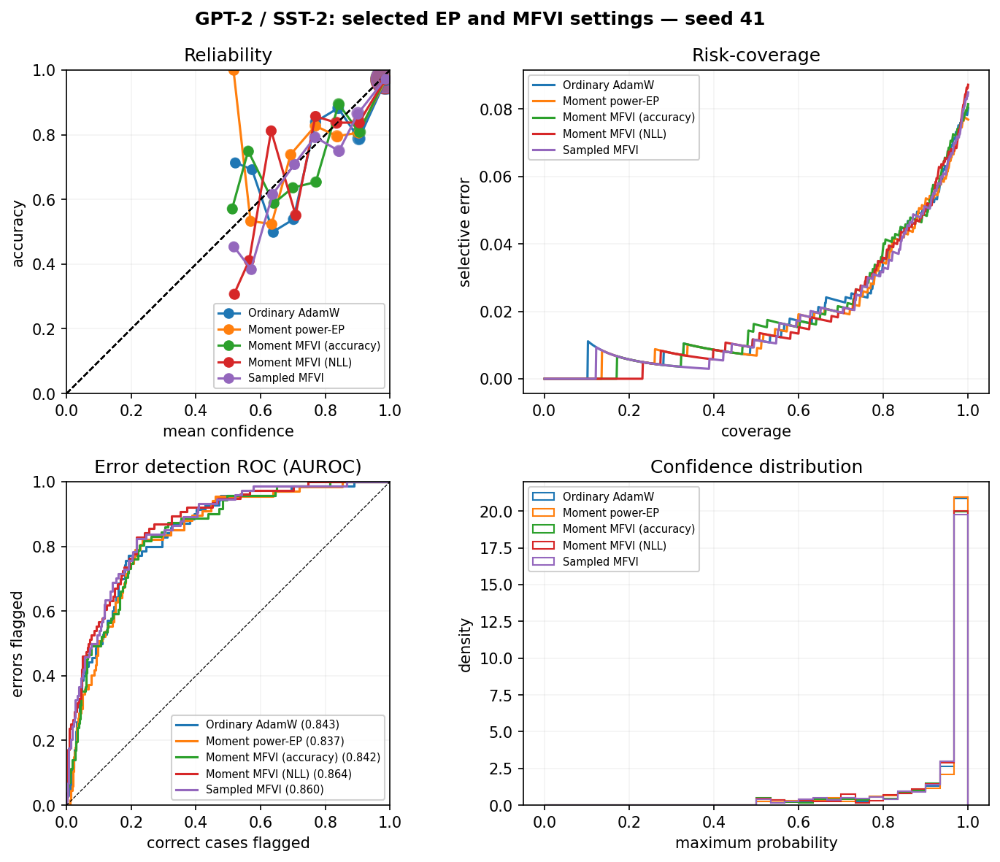

In [96]:
sst2_results = show_benchmark("sst2", "GPT-2 / SST-2: selected EP and MFVI settings")


## The same Gaussian adapters in two independent implementations

This check transfers the selected MFVI and EP **beliefs**, including both Gaussian
LoRA factors, without training again. The two implementations use the same frozen
GPT-2 weights, 872 sentiment inputs and 20-node scalar Gaussian integral.
For the logit contrast $z(w)$, the delta approximation is $m_z=z(m)$ and
$v_z=\sum_j(\partial_jz(m))^2v_j$. Differentiating this approximation also
differentiates its Jacobian; freezing that Jacobian would define a different update.
This check uses the fully differentiated map; a frozen-Jacobian training variant
is a separate approximation.

The table compares native PyTorch and JAX predictions and likelihood derivatives
at the same four fixed examples. It tests the implementation of this approximation,
not its accuracy against nonlinear posterior samples. The earlier Monte Carlo
study supplies the separate approximation-quality comparison.


**Key code: scalar moment map and method-specific likelihood**

```python
def binary_marginals(engine,ids,mask,means,variances,joint=False):
    h=engine.embedding(ids);inputs=[]
    for i in range(len(engine.model.backbone.h)):
        inputs.append(h)
        h=engine.block_function(i,mask)(h,*means[4*i:4*i+4])
    z=engine.head_function(mask)(h);contrast=z[:,1]-z[:,0]
    def head_gradient(one_h,one_mask):
        def scalar(x):
            pair=engine.head_function(one_mask[None])(x[None])[0]
            return pair[1]-pair[0]
        return torch.func.grad(scalar)(one_h)
    sensitivity=torch.vmap(head_gradient)(h,mask)
    variance=contrast.new_zeros((len(ids),len(ids))) if joint else torch.zeros_like(contrast)
    for i in reversed(range(len(inputs))):
        weights=means[4*i:4*i+4]
        def local_pull(one_h,one_mask,one_sensitivity):
            f=engine.block_function(i,one_mask[None])
            def local(x,*w):return f(x[None],*w)[0]
            _,pull=torch.func.vjp(local,one_h,*weights)
            return pull(one_sensitivity)
        sensitivity,*J=torch.vmap(local_pull)(inputs[i],mask,sensitivity)
        for j,v in zip(J,variances[4*i:4*i+4]):
            if joint:
                weighted=(j*v.sqrt()).flatten(1)
                variance=variance+weighted@weighted.T
            else:variance=variance+(j.square()*v).flatten(1).sum(1)
    return contrast,variance

def objective(engine,ids,mask,y,means,variances,nodes,weights,expected=True):
    m,v=binary_marginals(engine,ids,mask,means,variances)
    z=m[:,None]+v.clamp_min(1e-30).sqrt()[:,None]*nodes
    ll=F.logsigmoid((2*y[:,None]-1)*z)
    return -(ll*weights).sum(-1).mean() if expected else -torch.logsumexp(ll+weights.log(),-1).mean()
```


In [99]:
folder = evidence / "transferred_gaussian_text"
subprocess.run([sys.executable, str(evidence / "matched/compare_text_beliefs.py"), str(folder)],
               check=True, capture_output=True, text=True)
agreement = json.loads((folder / "native_agreement.json").read_text())
assert agreement["passed"], "Investigate the matched-belief discrepancy before reporting equivalence."
records=[]
for method in ("mfvi", "ep"):
    for suffix, framework in (("_torch", "PyTorch"), ("", "JAX")):
        r=json.loads((folder / (method+suffix+".json")).read_text())
        records.append({"Belief":method.upper(), "Implementation":framework,
                        "Accuracy ↑":r["accuracy"], "NLL ↓":r["nll"], "ECE ↓":r["ece"]})
display(pd.DataFrame(records).round(7))
display(pd.DataFrame(agreement["rows"]).rename(columns={
    "max_abs":"Maximum absolute error ↓", "relative_l2":"Relative L2 error ↓"}))


,Belief,Implementation,Accuracy ↑,NLL ↓,ECE ↓
0,MFVI,PyTorch,0.918578,0.225980,0.030367
1,MFVI,JAX,0.918578,0.225980,0.030367
2,EP,PyTorch,0.923165,0.223255,0.029407
3,EP,JAX,0.923165,0.223255,0.029407


,method,quantity,Maximum absolute error ↓,Relative L2 error ↓,passed
0,mfvi,probabilities,9.000301e-06,0.000001,True
1,mfvi,objective,5.066395e-07,0.000004,True
2,mfvi,mean,9.512529e-06,0.000010,True
3,mfvi,variance,3.767014e-05,0.000005,True
4,ep,probabilities,6.139278e-06,0.000001,True
5,ep,objective,0.000000e+00,0.000000,True
6,ep,mean,2.960209e-06,0.000005,True
7,ep,variance,1.716614e-05,0.000008,True


# 7. Conditional moment MFVI: GPT-2 and RoBERTa LoRA

The BLoB-style conditional Gaussian adapter is a second **MFVI** construction.
It changes which LoRA factor is uncertain and how likelihood and KL updates
are applied. Its shared nonlinear activation carriers preserve correlations
that the simplest diagonal activation approximation drops. It is not EP and
does not use Vadam. These differences explain why it has its own transformer
implementation instead of being a flag on the image-layer example.


### Conditional Gaussian carriers and probability averaging

The BLoB-inspired construction learns **one diagonal Gaussian adapter
distribution**, not a mixture or an ensemble: $A=M_A+\rho^{\odot2}\odot\epsilon$
with $\epsilon\sim N(0,I)$; $B$ is a point parameter and the pretrained backbone
is frozen. Thus $\operatorname{Var}(A)=\rho^{\odot4}$. The objective is expected
log likelihood plus the source Gaussian KL, with prior standard deviation 0.2
and the source cyclic KL schedule. Likelihood AdamW and the separate
prior/variance SGD step follow that source update. This is **mean-field VI
with a conditional-moment approximation**, not EP or a canonical unit MFVI step.

**Why activation correlations survive diagonal weights.** For one adapter,
write $z=(W+sBA)x$ and $\overline W=W+sBM_A$. With independent $A$ and $x$,
mean $m_x$ and covariance $C_x$, conditional expectation gives
$E[z]=\overline Wm_x$. The law of total covariance gives the exact affine
identity $\operatorname{Cov}(z)=\overline W C_x\overline W^\top
+s^2B\operatorname{Diag}\{V_A(\operatorname{diag}C_x+m_x^{\odot2})\}B^\top$,
where $V_A=\operatorname{Var}(A)$. To derive the second term, condition on $x$:
independent rows of $A$ have conditional output variance
$\sum_j(V_A)_{ij}x_j^2$; then average $x_j^2$.
Multiplication by $B$ induces correlated outputs even though $V_A$ is diagonal.
For different inputs, the same random adapter is reused; their injected
cross-covariance contains $\sum_j(V_A)_{ij}E[x_jx'_j]$, not separate weight draws.

The training approximation retains these dependencies through shared local
directions. For paired nonlinear block outputs $Y_k^\pm$, define their mean
$m=(2K)^{-1}\sum_k(Y_k^++Y_k^-)$, odd deviations
$O_k=(Y_k^+-Y_k^-)/2$ and even deviations
$E_k=(Y_k^++Y_k^-)/2-m$. A moment carrier
$\widetilde Y=m+K^{-1/2}\sum_k(\epsilon_kO_k+\zeta_kE_k)$,
with independent coefficient vectors uniformly distributed on the sphere of
radius $\sqrt K$, has conditional mean $m$
and covariance $K^{-1}\sum_k(O_kO_k^\top+E_kE_k^\top)$.
Indeed, $\epsilon=\sqrt K g/\|g\|$ for $g\sim N(0,I_K)$ satisfies
$E\epsilon=0$ and $E[\epsilon\epsilon^\top]=I_K$ by rotational symmetry and
its fixed squared norm $K$; the independently generated $\zeta$ does too.
Expanding the paired centered outer products proves that this equals the
paired empirical covariance. Two antithetic pairs per block were used in the
training fit. This spherical carrier is stochastic and need not be Gaussian
conditional on its integration nodes; the finite-node nonlinear calculation
remains an approximation. The posterior weights are still a single Gaussian.
The Gaussian coordinate
bridge remains the same; this extension changes the moment closure and update.

The source training code also uses Flipout signs to reduce gradient variance.
Those signs preserve each example's perturbation marginal; independently
flipped examples are not a single shared-weight draw of the joint function.
Cross-input covariance diagnostics must therefore share actual sampled
weights, rather than treating independently flipped training rows as joint
posterior function samples.

At deployment, a compact fixed Gaussian state carries correlated directions
through the network. SST-2 uses nonlinear rank 1; CLINC uses tangent rank 2.
The output head averages probabilities: for SST-2 it integrates $E[\sigma(D)]$
over the Gaussian logit contrast; for CLINC it averages softmax probabilities
at symmetric output nodes. It does not take softmax of mean logits.


**Training and serving carriers are different.** The spherical law above is
stochastic and bounded conditional on its nodes. A Gaussian carrier with the
same columns has the same first two moments but a different higher-moment law.
The original `source_stream_moments.py` also couples these nodes to the source
sampler's random stream. If $a$ is a unit vector, $\xi_*$ and $Z_i$ are independent
standard Gaussians, set $\Xi_i=a_i\xi_*+Z_i-a_i\sum_j a_jZ_j$.
Conditional on $a$, the joint covariance is $aa^\top+(I-aa^\top)^2=I$ and
$\sum_i a_i\Xi_i=\xi_*$. Thus the nodes have the intended independent Gaussian
law while preserving the source draw under recombination. Since this law does
not depend on $a$, the nodes are independent of $a$ under the ideal random
construction. This coupling and its stop-gradient/randomness choices matter
when comparing updates, not only predicted moments.


**Key code: stochastic conditional-moment training transition (source_stream_moments.py)**

```python
def transition(layer, h, mask, K, seed, reference=False):
    # Private cubature randomness: the original source consumes none of it.
    auxiliary = torch.Generator(device=h.device).manual_seed(seed)
    a = torch.randn(K, device=h.device, dtype=h.dtype, generator=auxiliary)
    a = a / a.norm()
    b = torch.randn(K, device=h.device, dtype=h.dtype, generator=auxiliary)
    b = b / b.norm()

    def linear(layer, x):
        base = layer.base_layer if hasattr(layer, 'base_layer') else layer
        y = F.linear(x, base.weight, base.bias)
        if not hasattr(layer, 'lora_A'):
            return y
        for name in layer.active_adapters:
            A, B = layer.lora_A[name].weight, layer.lora_B[name].weight
            scale = layer.scaling[name]
            y = y + F.linear(F.linear(x, A), B) * scale
            if hasattr(layer, 'lora_A_rho') and layer.blobsample:
                assert layer.bayes_eps >= 0
                # EXACT source draw order/shapes, with the node axis removed.
                r = torch.ones_like(x[0]).uniform_(-1, 1).sign()
                t = x.new_ones(x.shape[1:-1] + (A.shape[0],)).uniform_(-1, 1).sign()
                xi = torch.randn_like(A)
                if reference:
                    nodes = xi[None]
                else:
                    Z = torch.randn((K,) + tuple(A.shape), device=x.device,
                                    dtype=x.dtype, generator=auxiliary)
                    av = a[:, None, None]
                    nodes = av * xi + Z - av * (av * Z).sum(0)
                    nodes = torch.cat([nodes, -nodes])
                noise = torch.einsum('k...d,krd->k...r', x * r,
                                     nodes * layer.lora_A_rho[name].square()) * t
                y = y + F.linear(noise, B) * scale
        return y

    x = h[None].expand(1 if reference else 2*K, *h.shape)
    att = layer.attention.self
    N, B, T, D = x.shape
    H, d = att.num_attention_heads, att.attention_head_size
    q, k, v = [linear(getattr(att, n), x).reshape(N, B, T, H, d).transpose(2, 3)
               for n in ['query', 'key', 'value']]
    masks = mask[None].expand(N, *mask.shape).reshape(N*B, *mask.shape[1:])
    y = F.scaled_dot_product_attention(q.reshape(N*B, H, T, d),
                                      k.reshape(N*B, H, T, d),
                                      v.reshape(N*B, H, T, d),
                                      attn_mask=masks, dropout_p=0.)
    y = y.reshape(N, B, H, T, d).transpose(2, 3).reshape(N, B, T, D)
    y = linear(layer.attention.output.dense, y)
    ln = layer.attention.output.LayerNorm
    x = F.layer_norm(x+y, ln.normalized_shape, ln.weight, ln.bias, ln.eps)
    y = layer.intermediate.intermediate_act_fn(linear(layer.intermediate.dense, x))
    y = linear(layer.output.dense, y)
    ln = layer.output.LayerNorm
    y = F.layer_norm(x+y, ln.normalized_shape, ln.weight, ln.bias, ln.eps)
    if reference:
        return y[0]
    plus, minus = y[:K], y[K:]
    mean = (plus+minus).mean(0)/2
    odd, even = (plus-minus)/2, (plus+minus)/2-mean
    shape = (K,) + (1,)*mean.ndim
    return mean + (a.reshape(shape)*odd+b.reshape(shape)*even).sum(0)
```


**Key code: nonlinear moments and tangent normalization (compact_moments.py)**

```python
def elementwise_moments(m,U,nodes,weights,signs,kind):
    v=U.square().mean(0)
    shape=(len(nodes),)+(1,)*m.ndim
    z=m[None]+root(2*v)[None]*nodes.reshape(shape)
    y=activation(z,kind);w=weights.reshape(shape)
    mean=(w*y).sum(0);variance=(w*(y-mean[None]).square()).sum(0)
    plus,minus=activation(m[None]+U,kind),activation(m[None]-U,kind)
    center=(plus+minus).mean(0)/2
    cols=(plus-minus)/2+((plus+minus)/2-center[None])*signs
    raw=cols.square().mean(0)
    threshold=(16*torch.finfo(m.dtype).eps*(1+m.abs())).square()
    active=(v>threshold)&(raw>torch.finfo(raw.dtype).tiny)
    ratio=torch.where(active,variance,torch.ones_like(variance))/torch.where(active,raw,torch.ones_like(raw))
    cols=torch.where(active[None],cols*root(ratio)[None],activation_derivative(m,kind)[None]*U)
    return torch.where(active,mean,activation(m,kind)),cols

def tangent_norm(m,U,weight,bias,eps):
    c=m-m.mean(-1,keepdim=True)
    s2=c.square().mean(-1,keepdim=True)+eps
    du=U-U.mean(-1,keepdim=True)
    projected=(du-c[None]*(du*c[None]).mean(-1,keepdim=True)/s2[None])*weight/s2.sqrt()[None]
    return F.layer_norm(m,weight.shape,weight,bias,eps),projected

def tangent_softmax(m,U,mask):
    p=(m+mask).softmax(-1)
    return p,p[None]*(U-(U*p[None]).sum(-1,keepdim=True))
```


<details><summary><strong>Native PyTorch source: separate BLoB transformer model</strong></summary>

```python
"""External BLoB on the tutorial's architectures, with explicit adaptation scope.

Only GPT-2's fused QKV storage is split: its point function is unchanged. This
lets the original BLoB Linear code apply to query/value exactly as in RoBERTa.
The Bayesian family is the source random A / deterministic B, NOT our former
random A+B or CLINC full-weight family. No algorithm is called EP here.
"""
import math
import torch
from torch import nn
from transformers import GPT2LMHeadModel,RobertaForSequenceClassification
from transformers.pytorch_utils import Conv1D
from peft import LoraConfig,get_peft_model
from replicate import arguments,Local,BLoB,MLE

class SplitQKV(nn.Module):
    def __init__(self,layer):
        super().__init__();d=layer.in_features
        for i,name in enumerate(['query','key','value']):
            m=nn.Linear(d,d,device=layer.weight.device,dtype=layer.weight.dtype)
            with torch.no_grad():m.weight.copy_(layer.weight[i*d:(i+1)*d]);m.bias.copy_(layer.bias[i*d:(i+1)*d])
            setattr(self,name,m)
    def forward(self,x):return torch.cat([self.query(x),self.key(x),self.value(x)],-1)

def convert_conv(module):
    for name,child in list(module.named_children()):
        if isinstance(child,Conv1D):
            linear=nn.Linear(child.weight.shape[0],child.weight.shape[1],device=child.weight.device,dtype=child.weight.dtype)
            with torch.no_grad():linear.weight.copy_(child.weight.T);linear.bias.copy_(child.bias)
            setattr(module,name,linear)
        else:convert_conv(child)

def make_model(task,method,seed,n,epochs,full_head=False,mean_lr=None,tutorial_init=False,point_decay=.01):
    torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
    if task=='sst2':
        base=GPT2LMHeadModel.from_pretrained('gpt2',revision='607a30d783dfa663caf39e06633721c8d4cfcd7e',attn_implementation='eager')
        base.config.use_cache=False;convert_conv(base)
        for block in base.transformer.h:block.attn.c_attn=SplitQKV(block.attn.c_attn)
        pc=LoraConfig(r=4,lora_alpha=32,lora_dropout=0.,target_modules=['query','value'])
    else:
        base=RobertaForSequenceClassification.from_pretrained('roberta-base',revision='e2da8e2f811d1448a5b465c236feacd80ffbac7b',num_labels=150,attn_implementation='eager')
        targets=['query','value'] if full_head else ['query','value','classifier.dense','classifier.out_proj']
        pc=LoraConfig(r=8,lora_alpha=8,lora_dropout=0.,target_modules=targets)
    peft=get_peft_model(base,pc)
    if full_head:
        assert task=='clinc'
        # A new 150-class task needs a trainable classifier. Its parameters are
        # point estimates in BOTH matched methods; Bayesian uncertainty remains
        # in the backbone adapters. This is not full-weight Bayesian fine tuning.
        for p in peft.get_base_model().classifier.parameters():p.requires_grad_(True)
    # The established SST-2 adapter initializer. Pair it across all methods.
    if task=='sst2':
        with torch.no_grad():
            for name,p in peft.named_parameters():
                if 'lora_A.' in name:p.normal_(0.,.02)
                if 'lora_B.' in name:p.zero_()
    requested_means={n:p.detach().clone() for n,p in peft.named_parameters() if 'lora_A.' in n or 'lora_B.' in n} if tutorial_init else None
    args=arguments('map' if method=='ordinary' else 'blob',seed)
    args.num_samples=n;args.n_epochs=epochs;args.outdim=2 if task=='sst2' else 150
    args.max_train_steps=epochs*math.ceil(n/32);args.lr=mean_lr if mean_lr is not None else (3e-4 if task=='sst2' else 5e-5)
    args.opt_wd=point_decay if method=='ordinary' else 0.;args.warmup_ratio=.05 if task=='sst2' else .06
    model=(MLE if method=='ordinary' else BLoB)(peft,pc,args,Local()).cuda()
    if requested_means is not None:
        # The source's second PEFT construction reinitializes adapters. Restore
        # the requested tutorial initializer only in the explicitly named run.
        restored=set()
        with torch.no_grad():
            for name,p in peft.named_parameters():
                if name in requested_means:
                    p.copy_(requested_means[name]);restored.add(name)
        assert restored==set(requested_means),'PEFT changed adapter names: requested initializer was not restored'
    if full_head:
        # WrapperBase constructs another PEFT wrapper, which freezes non-adapter
        # parameters again. Restore the declared point-head scope AFTER it.
        for p in model.base_model.get_base_model().classifier.parameters():p.requires_grad_(True)
        # Keep the source likelihood AdamW / KL-SGD ordering. Give the point
        # classifier the SAME decoupled decay in both methods; its bias has none.
        named=dict(model.named_parameters());ids={id(p):name for name,p in named.items()}
        groups=[]
        for group in model.opt.param_groups:
            head=[p for p in group['params'] if 'classifier' in ids[id(p)]]
            rest=[p for p in group['params'] if 'classifier' not in ids[id(p)]]
            if rest:groups.append({**group,'params':rest})
            if head:groups.append({**group,'params':head,'weight_decay':0. if all('bias' in ids[id(p)] for p in head) else point_decay})
        model.opt.param_groups=groups
    # Dropout disabled in the historical configuration. eval() leaves gradients
    # enabled and the source's explicit blobsample switch remains true.
    model.eval();model.M=int(100*n**(math.pi/8)/32);model.i=1
    return model

def logits(model,batch,task,target_ids=None):
    net=model.base_model.get_base_model()
    if task=='clinc':return net(input_ids=batch['input_ids'],attention_mask=batch['attention_mask']).logits
    h=net.transformer(input_ids=batch['input_ids'],attention_mask=batch['attention_mask'],use_cache=False).last_hidden_state
    last=batch['attention_mask'].sum(-1)-1
    h=h[torch.arange(len(h),device=h.device),last]
    return torch.nn.functional.linear(h,net.lm_head.weight[target_ids])

def set_sample(model,active):
    for layer in model.modules():
        if hasattr(layer,'blobsample'):layer.blobsample=active

```

</details>


<details><summary><strong>Native PyTorch source: compact transformer moments</strong></summary>

```python
"""Small-rank Gaussian propagation with merged affine means and covariance.

State(m,U) represents C=U^T U/K. This is a moment approximation, not K sampled
networks. A fixed sign sketch adds independent adapter uncertainty to U.
Covariance directions share their index through residual/attention branches.

The merged affine operation changes only execution. The optional SDPA cubature
changes the attention approximation: apply attention to jointly paired Q/K/V
nodes and project their output first two moments. Report it as an ablation.
"""
import math
import torch
import torch.nn.functional as F
from nonlinear_moments import State, root
from transfer_moments import TransferMoments


def activation(z,kind):
    if kind=='tanh':return z.tanh()
    if kind=='gpt_gelu':return .5*z*(1+torch.tanh(math.sqrt(2/math.pi)*(z+.044715*z.pow(3))))
    return z*torch.special.ndtr(z)

def activation_derivative(z,kind):
    if kind=='tanh':return 1-z.tanh().square()
    if kind=='gpt_gelu':
        c=math.sqrt(2/math.pi);t=torch.tanh(c*(z+.044715*z.pow(3)))
        return .5*(1+t)+.5*z*(1-t.square())*c*(1+3*.044715*z.square())
    return torch.special.ndtr(z)+z*torch.exp(-z.square()/2)/math.sqrt(2*math.pi)

def elementwise_moments(m,U,nodes,weights,signs,kind):
    v=U.square().mean(0)
    shape=(len(nodes),)+(1,)*m.ndim
    z=m[None]+root(2*v)[None]*nodes.reshape(shape)
    y=activation(z,kind);w=weights.reshape(shape)
    mean=(w*y).sum(0);variance=(w*(y-mean[None]).square()).sum(0)
    plus,minus=activation(m[None]+U,kind),activation(m[None]-U,kind)
    center=(plus+minus).mean(0)/2
    cols=(plus-minus)/2+((plus+minus)/2-center[None])*signs
    raw=cols.square().mean(0)
    threshold=(16*torch.finfo(m.dtype).eps*(1+m.abs())).square()
    active=(v>threshold)&(raw>torch.finfo(raw.dtype).tiny)
    ratio=torch.where(active,variance,torch.ones_like(variance))/torch.where(active,raw,torch.ones_like(raw))
    cols=torch.where(active[None],cols*root(ratio)[None],activation_derivative(m,kind)[None]*U)
    return torch.where(active,mean,activation(m,kind)),cols

fused_elementwise=torch.compile(elementwise_moments,dynamic=True,fullgraph=True)

def tangent_elementwise(m,U,kind):
    return activation(m,kind),activation_derivative(m,kind)[None]*U

def tangent_norm(m,U,weight,bias,eps):
    c=m-m.mean(-1,keepdim=True)
    s2=c.square().mean(-1,keepdim=True)+eps
    du=U-U.mean(-1,keepdim=True)
    projected=(du-c[None]*(du*c[None]).mean(-1,keepdim=True)/s2[None])*weight/s2.sqrt()[None]
    return F.layer_norm(m,weight.shape,weight,bias,eps),projected

def tangent_softmax(m,U,mask):
    p=(m+mask).softmax(-1)
    return p,p[None]*(U-(U*p[None]).sum(-1,keepdim=True))

fused_tangent_elementwise=torch.compile(tangent_elementwise,dynamic=True,fullgraph=True)
fused_tangent_norm=torch.compile(tangent_norm,dynamic=True,fullgraph=True)
fused_tangent_softmax=torch.compile(tangent_softmax,dynamic=True,fullgraph=True)


class CompactMoments(TransferMoments):
    def __init__(self, rank=2, seed=197, nonlinear=True, attention_rule='original', order=5, match_diagonal=False):
        super().__init__(rank=rank,seed=seed,nonlinear=nonlinear,order=order)
        self.attention_rule=attention_rule
        self.match_diagonal=match_diagonal
        self.affines={}
        self.probes={}
        self.quadrature={}
        self.task=None

    def forward_task(self,model,batch,task,target_ids=None,**kwargs):
        self.task=task
        return super().forward_task(model,batch,task,target_ids,**kwargs)

    def elementwise(self,x,fn,derivative):
        kind='tanh' if fn is torch.tanh else 'gpt_gelu' if self.task=='sst2' else 'gelu'
        if not self.nonlinear:
            return State(*fused_tangent_elementwise(x.m,x.U,kind))
        key=(x.m.device,x.m.dtype)
        if key not in self.quadrature:
            self.quadrature[key]=(torch.as_tensor(self.nodes,device=x.m.device,dtype=x.m.dtype),
                                  torch.as_tensor(self.weights,device=x.m.device,dtype=x.m.dtype))
        nodes,weights=self.quadrature[key]
        signs=self.noise(x.m.new_zeros(())).reshape((self.rank,)+(1,)*x.m.ndim)
        mean,U=fused_elementwise(x.m,x.U,nodes,weights,signs,kind)
        return State(mean,U)

    def norm(self,layer,x):
        if self.nonlinear:return super().norm(layer,x)
        return State(*fused_tangent_norm(x.m,x.U,layer.weight,layer.bias,layer.eps))

    def softmax(self,x,mask):
        if self.nonlinear:return super().softmax(x,mask)
        return State(*fused_tangent_softmax(x.m,x.U,mask))

    def noise(self,x):
        key=(self.counter,tuple(x.shape),x.device,x.dtype)
        if key not in self.probes:
            self.probes[key]=super().noise(x)
        else:
            self.counter+=1
        return self.probes[key]

    def linear(self,layer,x):
        # With frozen weights, W_eff=W+s B A is identical for every call.
        # Precompute it once. Account for this setup separately from inference.
        if layer not in self.affines:
            base=layer.base_layer if hasattr(layer,'base_layer') else layer
            W=base.weight.detach()
            if hasattr(layer,'lora_A'):
                W=W.clone()
                for name in layer.active_adapters:
                    W=W+(layer.lora_B[name].weight@layer.lora_A[name].weight)*layer.scaling[name]
            self.affines[layer]=(W,base.bias)
        W,bias=self.affines[layer]
        y=F.linear(torch.cat((x.m[None],x.U),0),W)
        m=y[0] if bias is None else y[0]+bias
        U=y[1:]
        diagonal=U.square().mean(0) if self.match_diagonal else None
        if hasattr(layer,'lora_A_rho'):
            for name in layer.active_adapters:
                rho=layer.lora_A_rho[name]
                sigma2=rho.pow(4) if layer.bayes_eps>=0 else F.softplus(rho).square()
                # E Var(BAx|x)=B diag(V_A (m^2+diag C)) B^T.
                v=F.linear(x.m.square()+(x.v if self.nonlinear else 0),sigma2)
                U=U+F.linear(self.noise(v)*root(v)[None],layer.lora_B[name].weight)*layer.scaling[name]
                if self.match_diagonal:
                    diagonal=diagonal+F.linear(v,layer.lora_B[name].weight.square())*layer.scaling[name]**2
        if self.match_diagonal:
            # Independent injected noise has no cross term with the incoming
            # uncertainty. Enforce its analytic marginal variance instead of
            # retaining a noisy finite-sketch cross term. Cross-covariance is
            # still approximated; matching the diagonal does not make it exact.
            raw=U.square().mean(0)
            safe=torch.where(raw>0,raw,torch.ones_like(raw))
            U=torch.where((raw>0)[None],U*root(diagonal/safe)[None],root(diagonal)[None].expand_as(U))
        return State(m,U)

    def attention(self,layer,x,mask):
        if self.attention_rule=='original':
            return super().attention(layer,x,mask)
        assert self.attention_rule=='cubature'
        q,k,v=[self.linear(getattr(layer,n),x) for n in ['query','key','value']]
        B,T,D=q.m.shape
        H,d=layer.num_attention_heads,layer.attention_head_size
        def paired(z):
            nodes=torch.cat((z.m[None]+z.U,z.m[None]-z.U),0)
            return nodes.reshape(2*self.rank*B,T,H,d).transpose(1,2)
        # All Q/K/V use the same node, retaining represented cross-covariance.
        masks=mask.expand(B,*mask.shape[1:])[None].expand(2*self.rank,B,*mask.shape[1:])
        masks=masks.reshape(2*self.rank*B,*mask.shape[1:])
        y=F.scaled_dot_product_attention(paired(q),paired(k),paired(v),
                                         attn_mask=masks,dropout_p=0.)
        y=y.transpose(1,2).reshape(2*self.rank,B,T,D)
        return self.pair_columns(y[:self.rank],y[self.rank:])


def ordinary_forward(model,batch,task,target_ids,affines=None,compile_mlp=False):
    """Point execution with fused SDPA, giving ordinary the same kernel benefit."""
    def linear(layer,x):
        if affines is None or not hasattr(layer,'lora_A'):return layer(x)
        if layer not in affines:
            base=layer.base_layer;W=base.weight.detach().clone()
            for name in layer.active_adapters:
                W=W+(layer.lora_B[name].weight@layer.lora_A[name].weight)*layer.scaling[name]
            affines[layer]=(W,base.bias)
        return F.linear(x,*affines[layer])
    net=model.base_model.get_base_model()
    ids=batch['input_ids'];B,T=ids.shape
    if task=='sst2':
        h=net.transformer.wte(ids)+net.transformer.wpe(torch.arange(T,device=ids.device))[None]
        layers=net.transformer.h
        valid=torch.ones(T,T,device=ids.device,dtype=torch.bool).tril()[None,None]&batch['attention_mask'][:,None,None,:].bool()
    else:
        h=net.roberta.embeddings(input_ids=ids)
        layers=net.roberta.encoder.layer
        valid=batch['attention_mask'][:,None,None,:].bool()
    for layer in layers:
        if task=='sst2':
            x=layer.ln_1(h);att=layer.attn;maps=att.c_attn
            H,d=att.num_heads,att.head_dim
        else:
            x=h;att=layer.attention.self;maps=att
            H,d=att.num_attention_heads,att.attention_head_size
        q,k,v=[linear(getattr(maps,n),x).reshape(B,T,H,d).transpose(1,2) for n in ['query','key','value']]
        y=F.scaled_dot_product_attention(q,k,v,attn_mask=valid,dropout_p=0.)
        y=y.transpose(1,2).reshape(B,T,-1)
        if task=='sst2':
            h=h+att.c_proj(y)
            if compile_mlp:
                from fused_carrier import apply_mlp
                h=apply_mlp(layer,h[None],h.new_ones(1))
            else:
                h=h+layer.mlp.c_proj(layer.mlp.act(layer.mlp.c_fc(layer.ln_2(h))))
        else:
            h=layer.attention.output.LayerNorm(h+layer.attention.output.dense(y))
            h=layer.output.LayerNorm(h+layer.output.dense(layer.intermediate.intermediate_act_fn(layer.intermediate.dense(h))))
    if task=='sst2':
        h=net.transformer.ln_f(h)
        h=h[torch.arange(B,device=h.device),batch['attention_mask'].sum(-1)-1]
        if affines is not None:
            # Python-list advanced indexing creates a host-to-device index
            # copy. Cache the two unchanged readout rows before graph capture.
            if 'readout' not in affines:affines['readout']=net.lm_head.weight[target_ids].detach()
            return F.linear(h,affines['readout'])
        return F.linear(h,net.lm_head.weight[target_ids])
    return net.classifier(h)


def gaussian_probabilities(mean,variance):
    """The existing narrow/broad integration, without unused loss derivatives.

Evaluate both branches and select on GPU: no CPU synchronization or data-
dependent indexing. The broad branch gets variance one at unused narrow
coordinates, avoiding undefined 0/0. This preserves the integration rule.
"""
    from gaussian_logistic import rules
    nodes,weights,z,zw=rules(str(mean.device))
    m=mean.double();v=variance.double();broad=v>=4
    d=m[:,None]+v.sqrt()[:,None]*nodes
    n1=(d.sigmoid()*weights).sum(-1);n0=((-d).sigmoid()*weights).sum(-1)
    safe=torch.where(broad,v,torch.ones_like(v))[:,None]
    mu=m[:,None];sd=safe.sqrt()
    plus=torch.exp(-(z-mu).square()/(2*safe))/torch.sqrt(2*torch.pi*safe)
    minus=torch.exp(-(-z-mu).square()/(2*safe))/torch.sqrt(2*torch.pi*safe)
    tailplus=torch.exp(-mu+safe/2+torch.special.log_ndtr((mu-safe-40)/sd)).squeeze(-1)
    tailminus=torch.exp(mu+safe/2+torch.special.log_ndtr((-mu-safe-40)/sd)).squeeze(-1)
    correction=((minus-plus)*(-z).sigmoid()*zw).sum(-1)+tailminus-tailplus
    b1=torch.special.ndtr((mu/sd).squeeze(-1))+correction
    b0=torch.special.ndtr((-mu/sd).squeeze(-1))-correction
    return torch.stack((torch.where(broad,b0,n0),torch.where(broad,b1,n1)),-1).to(mean.dtype)


class InferenceGraphs:
    """Capture each observed input shape; replay the identical cached math."""
    def __init__(self,forward):
        self.forward=forward;self.graphs={};self.pool=torch.cuda.graph_pool_handle()

    def __call__(self,batch):
        key=tuple(batch['input_ids'].shape)
        if key not in self.graphs:
            static={k:v.clone() for k,v in batch.items()}
            stream=torch.cuda.Stream();stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):self.forward(static)
            torch.cuda.current_stream().wait_stream(stream)
            graph=torch.cuda.CUDAGraph()
            with torch.cuda.graph(graph,pool=self.pool):result=self.forward(static)
            self.graphs[key]=(graph,static,result)
        graph,static,result=self.graphs[key]
        for k,v in batch.items():static[k].copy_(v)
        graph.replay()
        return result

```

</details>


In [106]:
#@title Support: conditional-MFVI source inventory (expand to inspect)
for path in ["python/blob_mirror/transfer_model.py", "python/blob_mirror/compact_moments.py"]:
    tree = ast.parse((_reference_repo / path).read_text())
    definitions = [node.name for node in tree.body if isinstance(node, (ast.ClassDef, ast.FunctionDef))]
    print(path, "->", ", ".join(definitions))


python/blob_mirror/transfer_model.py -> SplitQKV, convert_conv, make_model, logits, set_sample
python/blob_mirror/compact_moments.py -> activation, activation_derivative, elementwise_moments, tangent_elementwise, tangent_norm, tangent_softmax, CompactMoments, ordinary_forward, gaussian_probabilities, InferenceGraphs


In [107]:
text, counts = transformer_summary(_reference_repo, "clinc")
display(pd.DataFrame([counts]))
display(HTML("<details><summary><b>Complete torchinfo layer summary</b></summary><pre>"+html.escape(text)+"</pre></details>"))
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    receipt = export_transformer(_reference_repo, "clinc", _architecture_work / "clinc.onnx")
display(pd.DataFrame([receipt]))
display(HTML(architecture_link("clinc", _architecture_work / "clinc.onnx")))


,task,output_shape,trainable_scalars,frozen_scalars
0,clinc,"[1, 150]",1000854,124054272


,task,bytes,maximum_absolute_error,parameter_storage,random_weights_for_inspection
0,clinc,339662,4.619360e-07,explicit graph inputs; no weights included,True


These summaries execute real full-size module graphs at randomly initialized
weights, avoiding pretrained downloads for a shape inspection. GPT-2 uses
the original Gaussian Q/V wrapper. The RoBERTa summary inspects its mean
Transformers/PEFT architecture, before adding BLoB variance parameters; its
trainable count is explicitly the mean model's count. Neither summary is a
pretrained performance evaluation. Both complete transformer exports are
checked against ONNX Runtime. Their weights are explicit graph inputs, so
the downloadable diagrams contain no pretrained checkpoint. The actual
attention, residual, normalization and adapter operations remain inspectable.


## Fixed-checkpoint quality and measured cost

SST-2 uses the fixed epoch-3 comparison. CLINC uses 13,500 in-scope training
examples, 1,500 stopping examples and 4,500 official in-scope test examples,
with the epoch-6 checkpoint selected on the stopping set. Its rank-8 Q/V
adapters surround a frozen RoBERTa-base backbone; the point classification
head learns 150 intents. Input and output embeddings are not an uncertain
tied language-model head in this classification setup.

The compact predictors use one nonlinear covariance direction for SST-2 and
two first-order directions for CLINC. The saved full reporting-set probabilities
below come from the final optimized PyTorch predictor. The cost table distinguishes
full historical fits from restored-step timing; multiplying a faster step
by an epoch count would not be a measured full training time.


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Ordinary AdamW,0.91399,0.26608,0.14088,0.05116,0.01933,0.85213
Moment MFVI (BLoB),0.91858,0.21489,0.12226,0.02021,0.01896,0.85165


,Accuracy ↑,NLL ↓,Brier ↓,ECE ↓,AURC ↓,Error AUROC ↑
method,,,,,,
Ordinary AdamW,0.96222,0.14990,0.05701,0.00989,0.00309,0.94715
Moment MFVI (BLoB),0.96600,0.14172,0.05487,0.00723,0.00298,0.94205


,task,method,prediction,seconds,setup_seconds,inference_multiple
0,sst2,ordinary,merged point SDPA,0.958265,5.732253,1.000000
1,sst2,hybrid,nonlinear K1,2.103357,15.076072,2.194964
2,clinc,ordinary,merged point SDPA,1.256966,5.658535,1.000000
3,clinc,hybrid,tangent K2,3.280710,15.157895,2.610022


seconds  step_multiple
task  mode                                      
clinc antithetic_shared  0.091040       3.067047
      ordinary_sdpa      0.029786       1.000000
      original           0.143076       4.772067
sst2  antithetic_shared  0.171421       2.822881
      ordinary_compiled  0.060938       1.000000
      original           0.304227       5.008919

,task,method,hardware,training_seconds
2,GPT-2 / SST-2,Ordinary,A100,500.678716
3,GPT-2 / SST-2,Revised K8,A100,1967.555075
4,GPT-2 / SST-2,Revised K32,A100,1967.555075
5,RoBERTa / CLINC,Ordinary,L4,100.238693
6,RoBERTa / CLINC,Revised K8,L4,604.358988
7,RoBERTa / CLINC,Revised K32,L4,604.358988


,task,metric,estimate,low,high
0,sst2,accuracy,0.004587,-0.008028,0.018349
1,sst2,nll,-0.051190,-0.082074,-0.022836
2,sst2,ece15,-0.030953,-0.044231,-0.010515
3,clinc,accuracy,0.003778,0.000667,0.007111
4,clinc,nll,-0.008177,-0.015538,-0.000465
5,clinc,ece15,-0.002655,-0.007423,0.002782


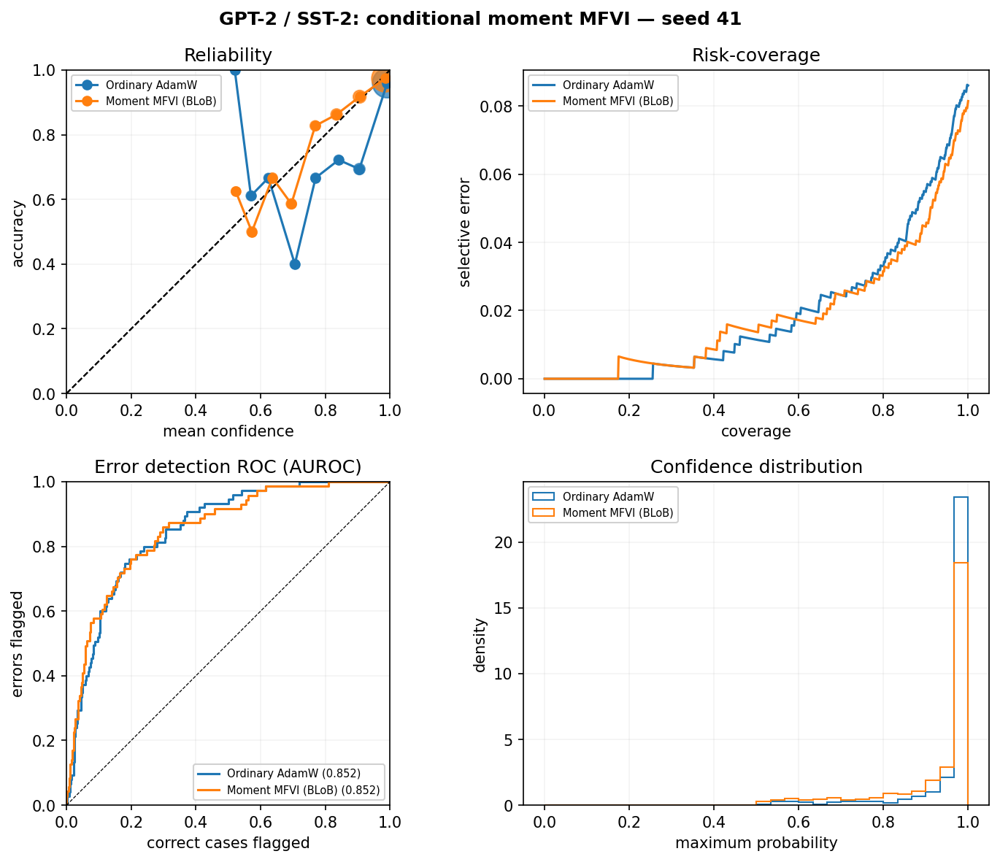

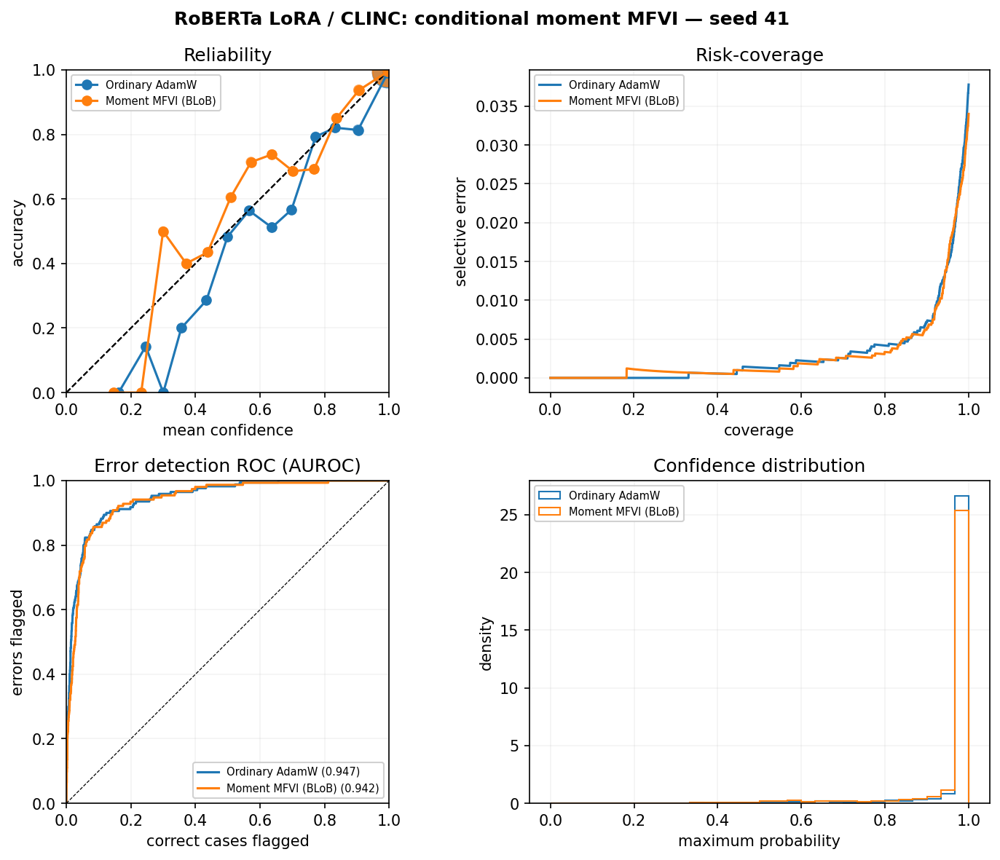

In [110]:
compact_sst2 = show_benchmark("compact_sst2", "GPT-2 / SST-2: conditional moment MFVI")
compact_clinc = show_benchmark("compact_clinc", "RoBERTa LoRA / CLINC: conditional moment MFVI")
predictions = pd.read_csv(evidence / "compact_transformers/prediction.csv")
display(predictions[["task", "method", "prediction", "seconds", "setup_seconds", "inference_multiple"]])
steps = pd.read_csv(evidence / "compact_transformers/training_steps.csv")
display(steps.groupby(["task", "mode"])[["seconds", "step_multiple"]].mean())
fits = pd.read_csv(evidence / "compact_transformers/historical_full_fit_cost.csv")
display(fits[~fits.task.str.contains("MRPC")][["task", "method", "hardware", "training_seconds"]])
display(pd.read_csv(evidence / "compact_transformers/paired_intervals.csv"))


The reported point estimates improve accuracy/NLL/ECE for these matched
checkpoints. The paired intervals condition on the existing fits, not on
retraining with new seeds. In particular, the stronger fixed-epoch SST-2 NLL
contrast partly reflects ordinary-model overfitting: its earlier epoch-1 NLL
was 0.21775, close to the compact predictor's 0.21489. CLINC's ECE interval
includes zero. These distinctions let the reader assess the demonstrated
calibration and efficiency without interpreting every favorable number as
an independently confirmed win. OOD performance for this compact predictor
is not inferred from a different checkpoint's OOD results.


# 8. Validation, reproduction and reading order

Run the semantic suite before any benchmark. It checks Fisher-coordinate
round trips, the EP/MFVI scalar counterexample, literal/projected layer
messages, repeated-parent accumulation, full graph updates, correlated
carriers, the power-EP cavity/field chain rule, all five training paths, metrics
and plots.


In [113]:
#@title Support: complete numerical regression suite (expand to inspect)
import subprocess
tests = _repo / "pytorch" / "tests"
if tests.exists():
    completed = subprocess.run(
        [sys.executable, "-m", "unittest", "discover", "-s", str(tests), "-q"],
        env={**os.environ, "PYTHONPATH": str(_repo / "src") if (_repo/"src").exists()
             else str(_repo/"pytorch"/"src")}, text=True, capture_output=True
    )
    print(completed.stdout + completed.stderr)
    if completed.returncode: raise RuntimeError("semantic suite failed")


[torch.onnx] Obtain model graph for `TinyResidualMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TinyResidualMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
----------------------------------------------------------------------
Ran 71 tests in 8.273s

OK (skipped=1)



## Evidence boundary

The exact, EP/MFVI-equivalence, approximation/cost, architecture and graph
checks run in this notebook. Benchmark metrics and figures are recalculated
from the bundled original PyTorch prediction arrays. Original fit time is not
the notebook rebuild time. No checkpoints, R-generated coordinates or figures
are embedded. `evidence/manifest.json` preserves source hashes, seeds, cohort,
objective/settings and costs. The native predictors are not all the same
implementation as the compact teaching modules. LeNet now includes the
Gaussian-pair max pool and independent literal/projected reverse calculations;
the five-method Dirty-MNIST experiment above executes complete 30-epoch fits
through those compact modules. Historical clean-MNIST and CIFAR results retain
their original optimized training source and measured costs.

### Running training rather than replaying evidence

For the selected GPT-2 runs, `python/gpt2/run_selected.py --method adamw`,
`--method sampled_mfvi`, or `--method moment_ep` downloads the pinned public
GPT-2/SST-2 assets and starts the original training program. It preserves the
three-epoch schedule even when reporting the epoch-one checkpoint. The separate
conditional-MFVI code is in `python/blob_mirror/train_fixed_transfer.py` with
its source dependency and data preparation described alongside it. Running a
full fit requires those public assets and adequate GPU time; the defaults of
this reader only reproduce figures and numerical checks.

The compact image trainer exposes the complete minibatch update and is exercised
end to end by the native Dirty-MNIST fits. Its eager, readable traversal and the
optimized historical trainer have different overheads; their timings are labeled
separately. Public image data and the complete training entry point are included.
Transformer ONNX exports inspect the actual native modules, while the matched
Gaussian-adapter check compares the same saved beliefs across implementations.

## Recommended reading order

Read `geometry.py`, then the Dense forward/literal reverse pair in `layers.py`,
then `graph.py`. Compare the MFVI and EP heads before reading `training.py`.
Only then move to `correlation.py`, the image architectures, and the transformer
carriers. Every output in this notebook can be regenerated without R.
